# 3 Smart Agriculture: Soil Moisture Forecasting for Precision Irrigation

## 3.5 Soil Moisture Dataset

### 3.5.2 Data Analysis

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

class DataAnalyzer:
    def __init__(self, df: pd.DataFrame):
        self.df = df.copy()
        self._normalize_columns(self.df)

    def _normalize_columns(self, df):
        """Lowercase, remove spaces and special characters"""
        df.columns = (
            df.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_")
            .str.replace("(", "", regex=False)
            .str.replace(")", "", regex=False)
            .str.replace("%", "pct", regex=False)
            .str.replace("/", "_", regex=False)
        )
    
    def info(self, df=None):
        df = df if df is not None else self.df
        print("=== Data Info ===")
        print(df.info())
        print("\n=== Missing Values per Column ===")
        print(df.isnull().sum())
    
    def describe(self, df=None):
        df = df if df is not None else self.df
        print("=== Statistical Summary ===")
        print(df.describe().T)
    
    def missing_summary(self, df=None):
        df = df if df is not None else self.df
        miss = df.isnull().sum()
        miss_pct = miss / len(df) * 100
        res = pd.DataFrame({'missing_count': miss, 'missing_pct': miss_pct}).sort_values('missing_pct', ascending=False)
        print("=== Missing Summary ===")
        print(res)
        plt.figure(figsize=(15, 6))
        sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
        plt.title("Missing Data Heatmap")
        plt.savefig("./output/missing_data_heatmap.png") 
        plt.show()
    
    def plot_time_series(self, df=None, cols=None, nrows=4, figsize=(15,10)):
        df = df if df is not None else self.df
        # Automatically detect numeric columns if not provided
        if cols is None:
            cols = df.select_dtypes(include=[np.number]).columns.tolist()
        
        # Handle datetime index
        if 'timestamp' in df.columns:
            df = df.set_index('timestamp')
        
        ncols = len(cols)//nrows + (1 if len(cols) % nrows else 0)
        fig, axs = plt.subplots(nrows, ncols, figsize=figsize)
        axs = np.atleast_1d(axs).flatten()
        for ax, col in zip(axs, cols):
            df[col].plot(ax=ax, title=f"Time Series of {col}")
            ax.set_xlabel("Time")
            ax.set_ylabel(col)
        plt.tight_layout()
        plt.savefig("./output/time_series_plots.png")
        plt.show()
    
    def plot_correlation_matrix(self, df=None, cols=None, figsize=(15,6), annot=True, cmap='coolwarm'):
        df = df if df is not None else self.df
        if cols is None:
            cols = df.select_dtypes(include=[np.number]).columns.tolist()
        corr = df[cols].corr()
        plt.figure(figsize=figsize)
        sns.heatmap(corr, annot=annot, fmt=".2f", cmap=cmap, square=True)
        plt.title("Correlation Matrix")
        plt.savefig("./output/correlation_matrix.png")
        plt.show()
    
    def full_report(self, df=None):
        df = df if df is not None else self.df
        self.info(df)
        print("\n")
        self.describe(df)
        print("\n")
        self.missing_summary(df)
        print("\n")
        self.plot_time_series(df)
        self.plot_correlation_matrix(df)


Data loaded from local path: ./data/Wazihub_Soil_Moisture_Prediction.csv
=== Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28049 entries, 0 to 28048
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   timestamp        28049 non-null  datetime64[ns]
 1   soil_humidity_1  8917 non-null   float64       
 2   soil_humidity_2  26304 non-null  float64       
 3   soil_humidity_3  16086 non-null  float64       
 4   soil_humidity_4  26306 non-null  float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 1.1 MB
None

=== Missing Values per Column ===
timestamp              0
soil_humidity_1    19132
soil_humidity_2     1745
soil_humidity_3    11963
soil_humidity_4     1743
dtype: int64


=== Statistical Summary ===
                   count                 mean                  min  \
timestamp          28049  2019-04-12 16:40:00  2019-02-23 00:00:00   
soil_humidity_1   8917.

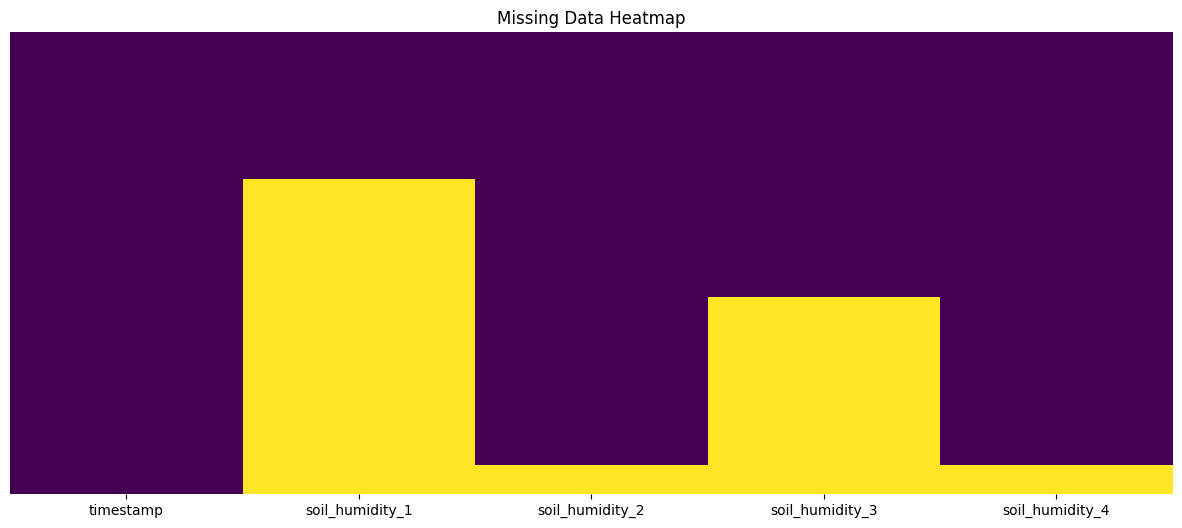

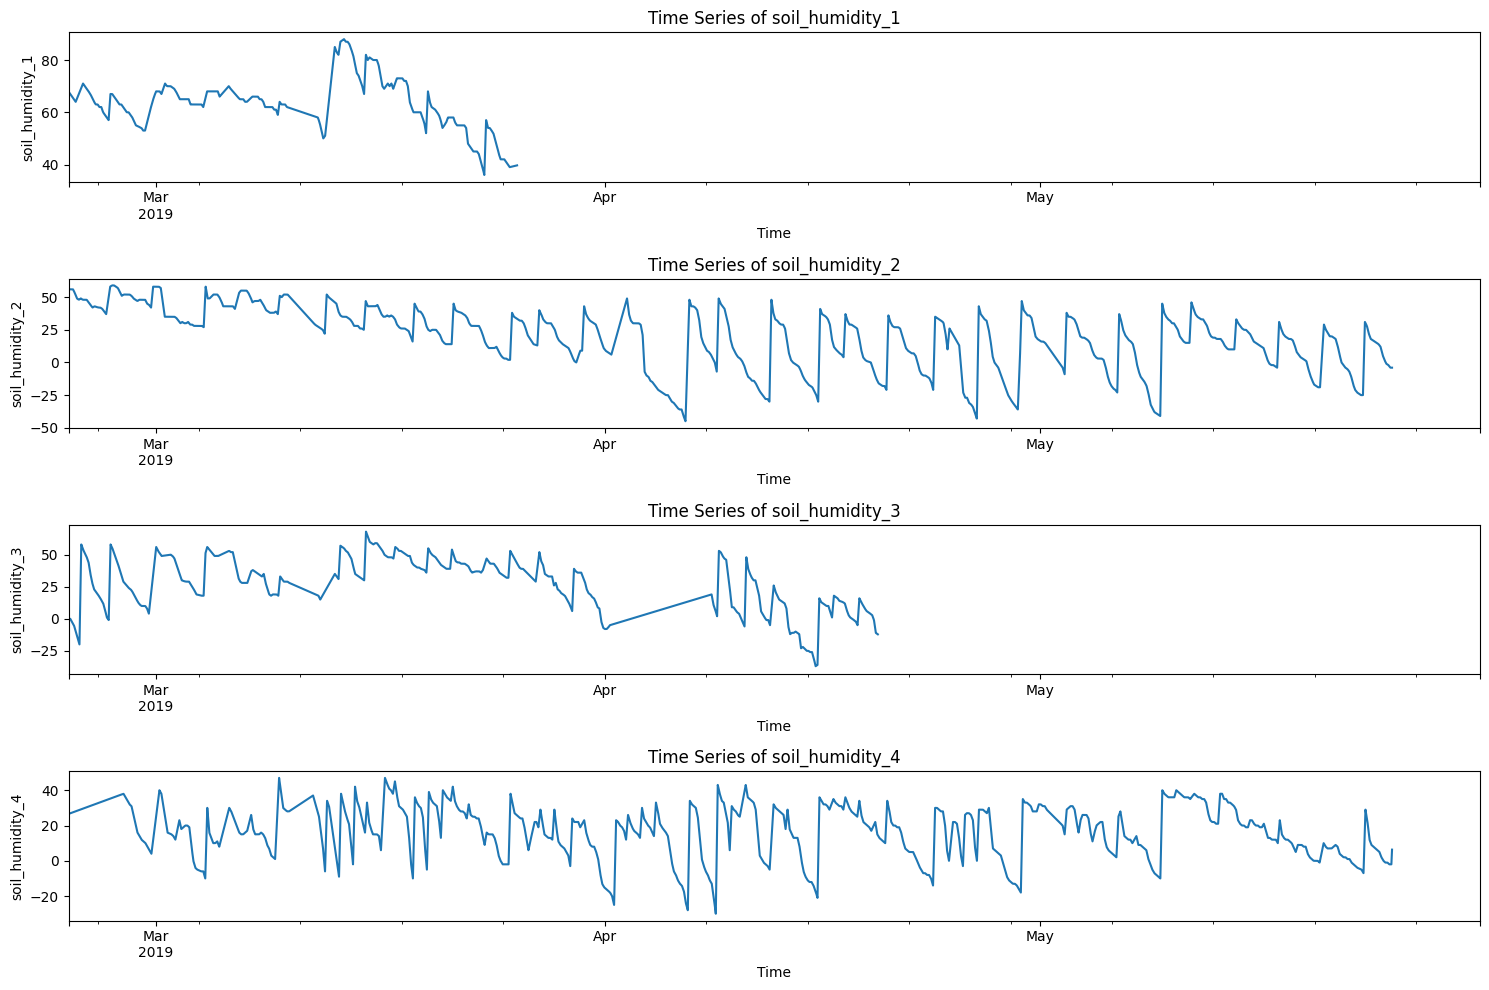

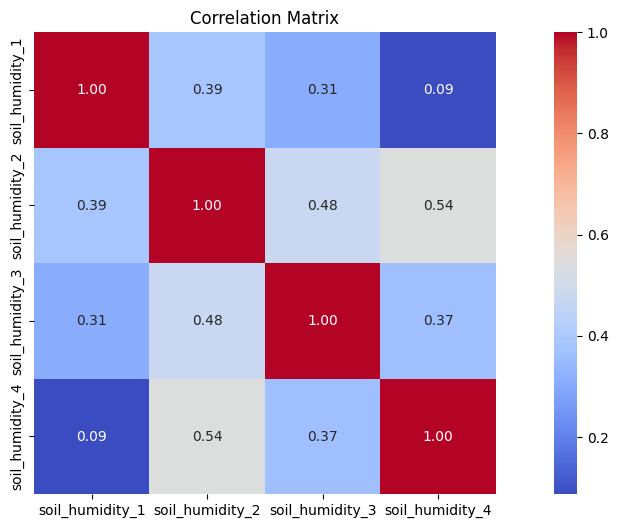

In [3]:
# Load dataset
path = './data/Wazihub_Soil_Moisture_Prediction.csv'
url = 'https://raw.githubusercontent.com/ayamlearning/Wazihub_Soil_Moisture_Prediction/refs/heads/master/Dataset/Train.csv'

# Check if the local file exists
if os.path.exists(path):
    df = pd.read_csv(path)
    print(f"Data loaded from local path: {path}")
else:
    df = pd.read_csv(url)
    print(f"Local file not found. Data loaded from URL: {url}")

# Initialize analyzer
analyzer = DataAnalyzer(df)

# Select only timestamp and four soil humidity columns (after normalization)
cols_to_use = ['timestamp', 'soil_humidity_1', 'soil_humidity_2', 'soil_humidity_3', 'soil_humidity_4']
soil_df = analyzer.df[cols_to_use].copy()

# Convert timestamp
soil_df['timestamp'] = pd.to_datetime(soil_df['timestamp'])

# Run full report on this subset
analyzer.full_report(soil_df)


## 3.6.1 Handling Missing Values

In [5]:
def clean_and_interpolate(df, value_cols, timestamp_col='timestamp', max_missing_fraction=0.1):
    df = df.copy()
    df[timestamp_col] = pd.to_datetime(df[timestamp_col])
    df = df.set_index(timestamp_col)
    
    # Detect missing values
    print("Missing values per column:")
    print(df[value_cols].isna().sum())
    
    # Drop rows at start/end if too many missing
    for col in value_cols:
        first_valid = df[col].first_valid_index()
        last_valid = df[col].last_valid_index()
        n = len(df)
        start_missing_fraction = df.loc[:first_valid].isna().sum()[col] / n
        end_missing_fraction = df.loc[last_valid:].isna().sum()[col] / n
        if start_missing_fraction > max_missing_fraction:
            df = df.loc[first_valid:]
        if end_missing_fraction > max_missing_fraction:
            df = df.loc[:last_valid]
    
    # Interpolate missing values in the middle
    df[value_cols] = df[value_cols].interpolate(method='time')
    
    # Forward/backward fill remaining NaNs
    df[value_cols] = df[value_cols].ffill().bfill()
    
    return df



Missing values per column:
soil_humidity_2    1745
soil_humidity_4    1743
dtype: int64
                     soil_humidity_2  soil_humidity_4
timestamp                                            
2019-02-23 00:00:00            55.72            26.57
2019-02-23 00:05:00            55.74            26.58
2019-02-23 00:10:00            55.77            26.59
2019-02-23 00:15:00            55.79            26.61
2019-02-23 00:20:00            55.82            26.62

Missing values per column after cleaning:
soil_humidity_2    0
soil_humidity_4    0
dtype: int64


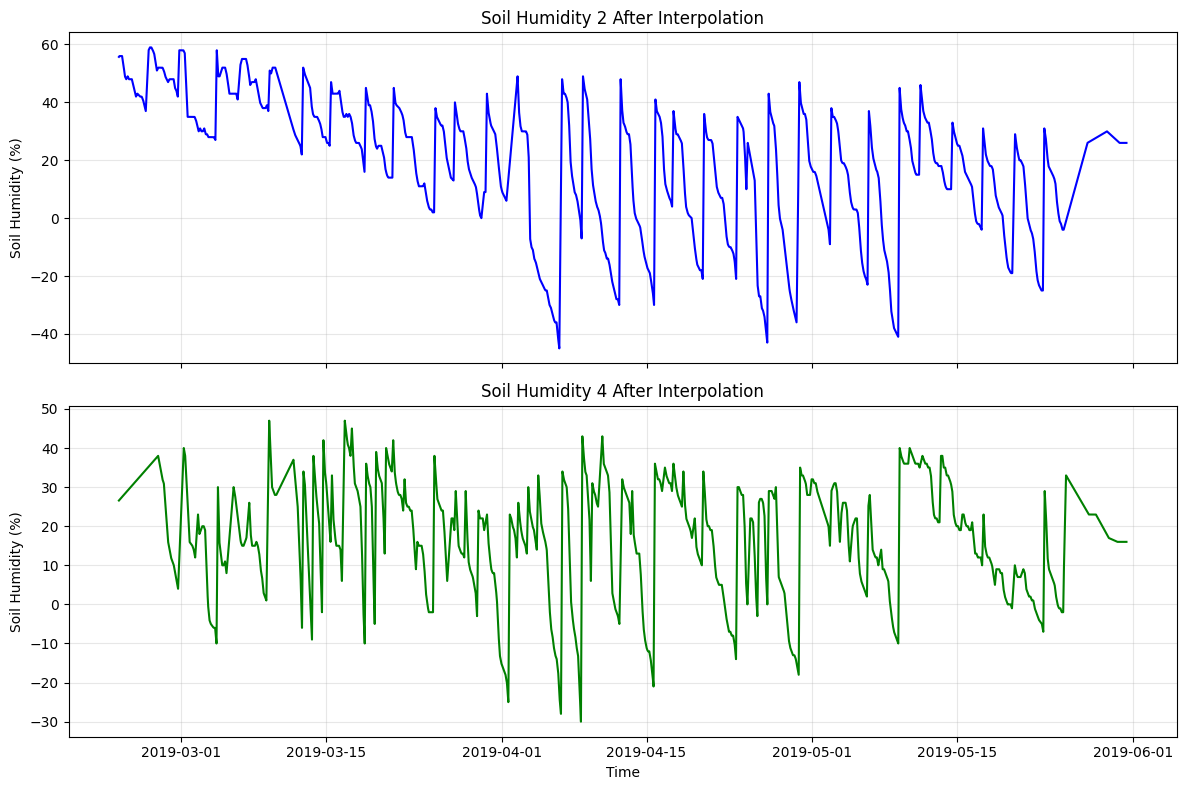

In [ ]:
# Example usage

import matplotlib.pyplot as plt

# Columns to clean
df_to_clean = soil_df[['soil_humidity_2', 'soil_humidity_4']].copy()
df_to_clean.loc[:, 'timestamp'] = soil_df['timestamp']

# Clean and interpolate
cleaned_df = clean_and_interpolate(df_to_clean, value_cols=['soil_humidity_2', 'soil_humidity_4'])

# Check the result
print(cleaned_df.head())
print("\nMissing values per column after cleaning:")
print(cleaned_df.isna().sum())

import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)  # 2 rows, 1 column

# Plot Soil Humidity 2
axs[0].plot(cleaned_df.index, cleaned_df['soil_humidity_2'], color='blue')
axs[0].set_title("Soil Humidity 2 After Interpolation")
axs[0].set_ylabel("Soil Humidity (%)")
axs[0].grid(True, alpha=0.3)

# Plot Soil Humidity 4
axs[1].plot(cleaned_df.index, cleaned_df['soil_humidity_4'], color='green')
axs[1].set_title("Soil Humidity 4 After Interpolation")
axs[1].set_xlabel("Time")
axs[1].set_ylabel("Soil Humidity (%)")
axs[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./output/interpolated_soil_humidity.png")
plt.show()




### 3.6.2 Denoise with Wavelet Transform

In [ ]:
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt

class WaveletDenoiser:
    def __init__(self, df: pd.DataFrame):
        self.df = df.copy()
        self.df.columns = (
            self.df.columns.str.strip()
                           .str.lower()
                           .str.replace(" ", "_")
                           .str.replace("(", "", regex=False)
                           .str.replace(")", "", regex=False)
                           .str.replace("%", "pct", regex=False)
                           .str.replace("/", "_", regex=False)
        )

    @staticmethod
    def adaptive_threshold_selection(coeffs):
        sigma = np.median(np.abs(coeffs[-1])) / 0.6745
        threshold = sigma * np.sqrt(2 * np.log(len(coeffs[0])))
        return threshold

    def denoise(self, cols=None, wavelet='db4', levels=None, threshold_scale=1.0, plot=True, zoom=200):
        import pywt
        import matplotlib.pyplot as plt
        import numpy as np
        from scipy.stats import pearsonr

        df_denoised = self.df.copy()
        if cols is None:
            cols = df_denoised.select_dtypes(include=[np.number]).columns.tolist()

        metrics_dict = {}
        for col in cols:
            signal = df_denoised[col].values
            # determine levels
            if levels is None:
                lev = min(6, int(np.log2(len(signal))))
            else:
                lev = levels
            # wavelet decomposition
            coeffs = pywt.wavedec(signal, wavelet, level=lev)
            # adaptive threshold with scaling
            threshold = self.adaptive_threshold_selection(coeffs) * threshold_scale
            coeffs_denoised = [coeffs[0]]
            for i in range(1, len(coeffs)):
                coeffs_denoised.append(pywt.threshold(coeffs[i], threshold*(0.5**i), mode='soft'))
            denoised_signal = pywt.waverec(coeffs_denoised, wavelet)[:len(signal)]
            df_denoised[col] = denoised_signal

            # metrics
            noise = signal - denoised_signal
            mse = np.mean(noise**2)
            snr_db = 20*np.log10(np.std(denoised_signal)/np.std(noise))
            correlation = np.corrcoef(signal, denoised_signal)[0,1]
            metrics_dict[col] = {
                'mse': mse,
                'snr_db': snr_db,
                'correlation': correlation,
                'threshold': threshold
            }

        # print metrics nicely
        import pandas as pd
        print("\nDenoising Metrics for Selected Columns:")
        print(pd.DataFrame(metrics_dict).T)

        
        # Plotting
        if plot:
            n_cols = len(cols)
            fig, axes = plt.subplots(n_cols, 3, figsize=(16, 5 * n_cols))
            if n_cols == 1:
                axes = np.expand_dims(axes, axis=0)
            for i, col in enumerate(cols):
                original = self.df[col].values
                denoised = df_denoised[col].values
                noise = original - denoised
                
                axes[i, 0].plot(df_denoised.index, original, label='Original', alpha=0.7)
                axes[i, 0].plot(df_denoised.index, denoised, label='Denoised', color='red')
                axes[i, 0].set_title(f'{col} Original vs Denoised')
                axes[i, 0].legend(); axes[i, 0].grid(True, alpha=0.3)
                plt.setp(axes[i, 0].get_xticklabels(), rotation=45, ha='right')

                axes[i, 1].plot(df_denoised.index, noise, color='gray')
                axes[i, 1].set_title(f'{col} Noise Component'); axes[i, 1].grid(True, alpha=0.3)
                plt.setp(axes[i, 1].get_xticklabels(), rotation=45, ha='right')

                axes[i, 2].plot(df_denoised.index[:zoom], original[:zoom], alpha=0.7, label='Original')
                axes[i, 2].plot(df_denoised.index[:zoom], denoised[:zoom], color='red', label='Denoised')
                axes[i, 2].set_title(f'{col} Zoomed - SNR {metrics_dict[col]["snr_db"]:.2f} dB')
                axes[i, 2].legend(); axes[i, 2].grid(True, alpha=0.3)
                plt.setp(axes[i, 2].get_xticklabels(), rotation=45, ha='right')
            
            plt.tight_layout()
            plt.savefig("./output/wavelet_denoising.png")
            plt.show()
        
        return df_denoised, metrics_dict



Denoising Metrics for Selected Columns:
                      mse     snr_db  correlation  threshold
soil_humidity_2  0.000027  72.589822          1.0   0.048065
soil_humidity_4  0.000026  68.755069          1.0   0.046303


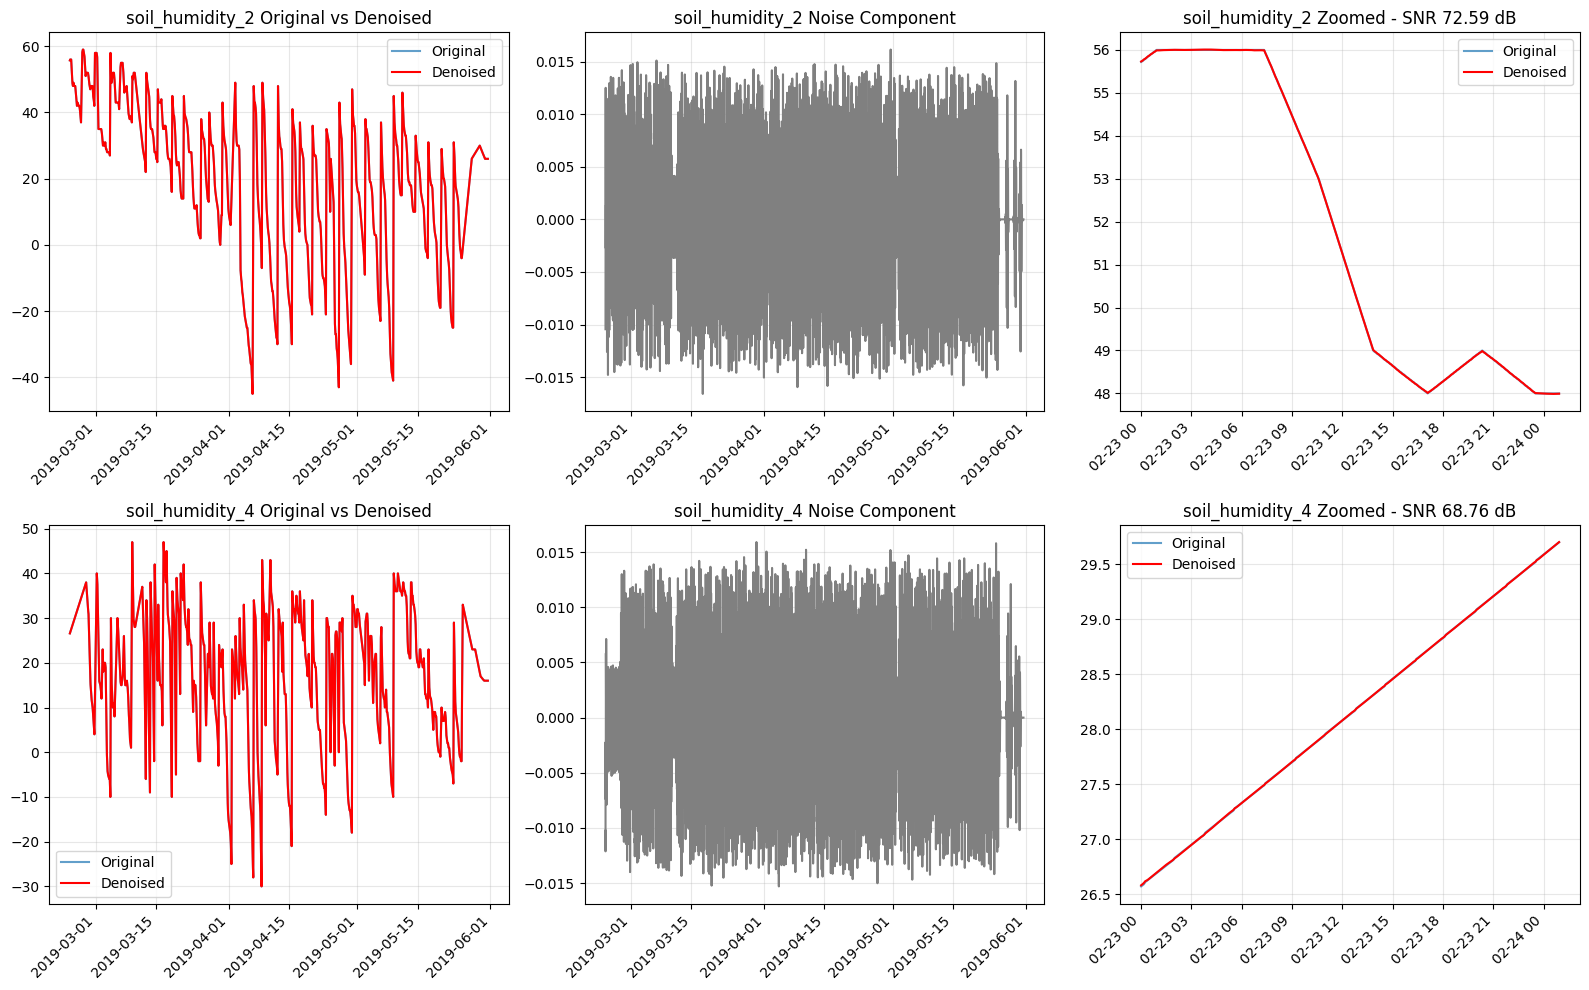

In [8]:
# Example usage

denoiser = WaveletDenoiser(cleaned_df)

# Denoise a single column
#cleaned_df, metrics = denoiser.denoise(cols=['soil_humidity_2'])

# Denoise two columns
denoised_df, metrics = denoiser.denoise(cols=['soil_humidity_2','soil_humidity_4'], 
                                       wavelet='sym5',             # choose wavelet type ('db4', 'sym5', 'coif3', etc.)
                                       levels=5,                   # decomposition level
                                       threshold_scale=5.0,        # increase threshold to smooth more
                                       plot=True,                  # whether to show plots
                                       zoom=300                     # zoom first N points for detailed view
                                       )

# Denoise all numeric columns
#cleaned_df, metrics = denoiser.denoise()

## 3.7 Forecasting with ARIMA

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

def forecast_arima(data, train_ratio=0.8, forecast_steps=None, 
                   seasonal_period=None, 
                   use_auto=True, use_seasonal=False, 
                   order=None, seasonal_order=None,
                   plot=True, verbose=True):
    """
    Fast time series forecasting - 10-100x faster than grid search.
    
    Speed improvements:
    - Uses pmdarima's auto_arima for automatic model selection (recommended)
    - Or manual order specification
    - Outlier handling
    - Reduced search space
    
    Parameters:
        data (pd.Series | pd.DataFrame): Input time series
        train_ratio (float): Train/test split ratio (default: 0.8)
        forecast_steps (int): Number of steps to forecast. If None, uses test set size
        seasonal_period (int): Seasonal period (e.g., 24 for hourly data)
        use_auto (bool): Use auto_arima (requires: pip install pmdarima)
        use_seasonal (bool): Include seasonal component
        order (tuple): Manual ARIMA order (p,d,q) - bypasses search
        seasonal_order (tuple): Manual seasonal order (P,D,Q,s)
        plot (bool): Whether to plot results
        verbose (bool): Print detailed output
    
    Returns:
        dict: Results including models, forecasts, and metrics
    """
    
    if isinstance(data, pd.Series):
        data = data.to_frame()
    
    results = {}
    
    # Check if pmdarima is available
    try:
        from pmdarima import auto_arima
        has_pmdarima = True
    except ImportError:
        has_pmdarima = False
        if use_auto:
            print("⚠️  pmdarima not installed. Install with: pip install pmdarima")
            print("Falling back to simplified search...")
            use_auto = False
    
    for col in data.columns:
        print(f"\n{'='*60}")
        print(f"Processing: {col}")
        print('='*60)
        
        series = data[col].dropna()
        
        # === 1. OUTLIER DETECTION & HANDLING ===
        q1, q3 = series.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower_bound = q1 - 3 * iqr
        upper_bound = q3 + 3 * iqr
        
        outliers = (series < lower_bound) | (series > upper_bound)
        n_outliers = outliers.sum()
        
        if n_outliers > 0:
            print(f"⚠️  Detected {n_outliers} outliers ({n_outliers/len(series)*100:.2f}%)")
            series_clean = series.copy()
            series_clean[outliers] = np.nan
            series_clean = series_clean.interpolate(method='linear')
        else:
            series_clean = series.copy()
        
        # === 2. TRAIN/TEST SPLIT ===
        train_size = int(len(series_clean) * train_ratio)
        train_data = series_clean.iloc[:train_size]
        test_data = series_clean.iloc[train_size:]
        
        # Determine forecast steps
        if forecast_steps is None:
            forecast_steps = len(test_data)
        
        print(f"Train size: {len(train_data)}, Test size: {len(test_data)}, Forecast steps: {forecast_steps}")
        
        # === 3. QUICK STATIONARITY CHECK ===
        adf_pval = adfuller(train_data, autolag='AIC')[1]
        is_stationary = adf_pval < 0.05
        
        if verbose:
            print(f"ADF p-value: {adf_pval:.4f} {'✓ Stationary' if is_stationary else '✗ Non-stationary'}")
        
        # === 4. MODEL FITTING ===
        start_time = pd.Timestamp.now()
        
        if order is not None:
            # Manual order specified - fastest option
            print(f"Using manual order: ARIMA{order}")
            if seasonal_order:
                model = SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
                print(f"  + Seasonal{seasonal_order}")
            else:
                model = ARIMA(train_data, order=order)
            best_model = model.fit(method_kwargs={"maxiter": 50})
            best_order = order
            best_seasonal_order = seasonal_order
            
        elif use_auto and has_pmdarima:
            # Use auto_arima - fast and reliable
            print("Running auto_arima (this may take 30-60 seconds)...")
            
            auto_model = auto_arima(
                train_data,
                start_p=0, start_q=0,
                max_p=3, max_q=3,
                d=None,  # Auto-detect differencing
                seasonal=use_seasonal,
                m=seasonal_period if use_seasonal else 1,
                start_P=0, start_Q=0,
                max_P=2, max_Q=2,
                D=None,
                trace=False,
                error_action='ignore',
                suppress_warnings=True,
                stepwise=True,  # Faster stepwise search
                n_jobs=-1,  # Use all CPU cores
                maxiter=50
            )
            
            best_order = auto_model.order
            best_seasonal_order = auto_model.seasonal_order if use_seasonal else None
            best_model = auto_model
            
        else:
            # Simplified grid search - limited scope for speed
            print("Running simplified search (max 2 mins)...")
            
            best_aic = np.inf
            best_order = None
            best_seasonal_order = None
            best_model = None
            
            # Limit search space for speed
            p_range = [0, 1, 2]
            d_range = [0, 1] if is_stationary else [1]
            q_range = [0, 1, 2]
            
            for p in p_range:
                for d in d_range:
                    for q in q_range:
                        if p == 0 and d == 0 and q == 0:
                            continue
                        
                        try:
                            model = ARIMA(train_data, order=(p, d, q))
                            fitted = model.fit(method_kwargs={"maxiter": 50})
                            
                            if fitted.aic < best_aic:
                                best_aic = fitted.aic
                                best_order = (p, d, q)
                                best_model = fitted
                        except:
                            continue
        
        elapsed = (pd.Timestamp.now() - start_time).total_seconds()
        
        if best_model is None:
            print("❌ No valid model found")
            continue
        
        model_str = f"SARIMA{best_order}x{best_seasonal_order}" if best_seasonal_order else f"ARIMA{best_order}"
        print(f"✓ Best model: {model_str} (fitted in {elapsed:.1f}s)")
        if hasattr(best_model, 'aic'):
            aic_value = best_model.aic() if callable(best_model.aic) else best_model.aic
            print(f"  AIC: {aic_value:.2f}")
        
        # === 5. FORECASTING ===
        # Generate forecast index
        if forecast_steps <= len(test_data):
            forecast_index = test_data.index[:forecast_steps]
            comparison_data = test_data.iloc[:forecast_steps]
        else:
            # Forecast beyond available test data
            last_date = series_clean.index[-1]
            if isinstance(last_date, pd.Timestamp):
                freq = pd.infer_freq(series_clean.index)
                if freq is None:
                    freq = series_clean.index[-1] - series_clean.index[-2]
                forecast_index = pd.date_range(start=last_date, periods=forecast_steps+1, freq=freq)[1:]
            else:
                forecast_index = range(len(series_clean), len(series_clean) + forecast_steps)
            comparison_data = test_data  # Compare with available test data only
        
        if use_auto and has_pmdarima:
            forecast = best_model.predict(n_periods=forecast_steps)
            forecast = pd.Series(forecast, index=forecast_index)
            # Approximate CI for pmdarima
            std_err = np.std(best_model.resid())
            forecast_ci_lower = forecast - 1.96 * std_err
            forecast_ci_upper = forecast + 1.96 * std_err
            forecast_ci = pd.DataFrame({
                'lower': forecast_ci_lower,
                'upper': forecast_ci_upper
            }, index=forecast_index)
        else:
            forecast_result = best_model.get_forecast(steps=forecast_steps)
            forecast = forecast_result.predicted_mean
            forecast.index = forecast_index
            forecast_ci = forecast_result.conf_int()
            forecast_ci.index = forecast_index
        
        # === 6. METRICS (only on available test data) ===
        if len(comparison_data) > 0:
            forecast_for_metrics = forecast.iloc[:len(comparison_data)]
            mse = mean_squared_error(comparison_data, forecast_for_metrics)
            rmse = np.sqrt(mse)
            mae = mean_absolute_error(comparison_data, forecast_for_metrics)
            
            # Robust MAPE
            mask = comparison_data != 0
            if mask.sum() > 0:
                mape = np.mean(np.abs((comparison_data[mask] - forecast_for_metrics[mask]) / comparison_data[mask])) * 100
            else:
                mape = np.inf
            
            #r2 = 1 - (np.sum((comparison_data - forecast_for_metrics)**2) / np.sum((comparison_data - comparison_data.mean())**2))
            
            # Directional accuracy
            actual_diff = comparison_data.diff().dropna()
            forecast_diff = forecast_for_metrics.diff().dropna()
            directional_accuracy = (np.sign(actual_diff) == np.sign(forecast_diff)).sum() / len(actual_diff) * 100
        else:
            # No test data to compare
            rmse = mae = mape = r2 = directional_accuracy = None
        
        if rmse is not None:
            print(f"\n📊 Metrics:")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  MAE: {mae:.4f}")
            print(f"  MAPE: {mape:.2f}%")
            #print(f"  R²: {r2:.4f}")
            print(f"  Directional Accuracy: {directional_accuracy:.2f}%")
        else:
            print(f"\n📊 Forecasting {forecast_steps} steps into the future (no test data for validation)")
        
        results[col] = {
            "best_order": best_order,
            "seasonal_order": best_seasonal_order,
            "stationary": is_stationary,
            "outliers_removed": n_outliers,
            "rmse": rmse,
            "mae": mae,
            "mape": mape,
            #"r2": r2,
            "directional_accuracy": directional_accuracy,
            "forecast": forecast,
            "forecast_ci": forecast_ci,
            "test_data": test_data,
            "train_data": train_data,
            "model": best_model,
            "fit_time": elapsed
        }
        
        # === 7. PLOTTING ===
        if plot:
            fig, axes = plt.subplots(2, 1, figsize=(14, 10))
            
            # Plot 1: Full View
            ax1 = axes[0]
            ax1.plot(train_data.index, train_data, label='Training', alpha=0.8, linewidth=1, color='blue')
            ax1.plot(forecast.index, forecast, label='Forecast', 
                    color='red', linewidth=2)
            ax1.fill_between(forecast.index,
                            forecast_ci.iloc[:, 0],
                            forecast_ci.iloc[:, 1],
                            alpha=0.3, color='red', label='Confidence Interval')
            if len(comparison_data) > 0:
                ax1.plot(comparison_data.index, comparison_data, label='Test (Actual)', 
                        linewidth=1.5, color='green')
            ax1.set_title(f"{col} - Full View", fontsize=12, fontweight='bold')
            ax1.set_xlabel("Time")
            ax1.set_ylabel("Value")
            ax1.legend(loc='upper left')
            ax1.grid(alpha=0.3)
            
            # Plot 2: Zoomed View (Forecast Period)
            ax2 = axes[1]
            ax2.plot(forecast.index, forecast, label='Forecast', 
                    color='red', linewidth=2)
            ax2.fill_between(forecast.index,
                            forecast_ci.iloc[:, 0],
                            forecast_ci.iloc[:, 1],
                            alpha=0.3, color='red', label='Confidence Interval')
            if len(comparison_data) > 0:
                ax2.plot(comparison_data.index, comparison_data, label='Test (Actual)', 
                        linewidth=2, color='green')
            ax2.set_title(f"{col} - Zoomed View (Forecast Period)", fontsize=12, fontweight='bold')
            ax2.set_xlabel("Time")
            ax2.set_ylabel("Value")
            ax2.legend(loc='upper left')
            ax2.grid(alpha=0.3)
            
            plt.tight_layout()
            plt.savefig(f"./output/forecast_{col}.png")
            plt.show()
    
    # Summary
    summary_df = pd.DataFrame({
        col: {
            "Model": f"{'S' if v['seasonal_order'] else ''}ARIMA{v['best_order']}" + 
                    (f"x{v['seasonal_order']}" if v['seasonal_order'] else ""),
            "RMSE": v['rmse'],
            "MAE": v['mae'],
            "MAPE%": v['mape'],
            #"R²": v['r2'],
            "Dir_Acc%": v['directional_accuracy'],
            "Time(s)": v['fit_time']
        }
        for col, v in results.items()
    }).T
    
    print("\n" + "="*60)
    print("SUMMARY")
    print("="*60)
    print(summary_df.round(3))
    
    return results, summary_df


# ============ USAGE EXAMPLES ============

# Option 1: AUTO (FASTEST & BEST) - requires pmdarima
# pip install pmdarima
# results, summary = forecast_arima(
#     denoised_df[['soil_humidity_2', 'soil_humidity_4']], 
#     use_auto=True,
#     use_seasonal=True,
#     seasonal_period=24,
#     forecast_steps=200  # Predict 200 steps
# )

# Option 2: Manual order (INSTANT) - if you know good parameters
# results, summary = forecast_arima(
#     denoised_df[['soil_humidity_2', 'soil_humidity_4']], 
#     order=(1, 1, 1),
#     forecast_steps=200,  # Predict 200 steps
#     use_auto=False
# )

# Option 3: Simplified search (SLOW but no dependencies)
# results, summary = forecast_arima(
#     denoised_df[['soil_humidity_2', 'soil_humidity_4']], 
#     use_auto=False,
#     use_seasonal=False,
#     forecast_steps=200  # Predict 200 steps
# )


Processing: soil_humidity_2
Train size: 22439, Test size: 5610, Forecast steps: 200
ADF p-value: 0.0000 ✓ Stationary
Running simplified search (max 2 mins)...
✓ Best model: ARIMA(2, 1, 2) (fitted in 36.5s)
  AIC: -61074.82

📊 Metrics:
  RMSE: 3.7269
  MAE: 2.9175
  MAPE: 9.74%
  Directional Accuracy: 61.81%


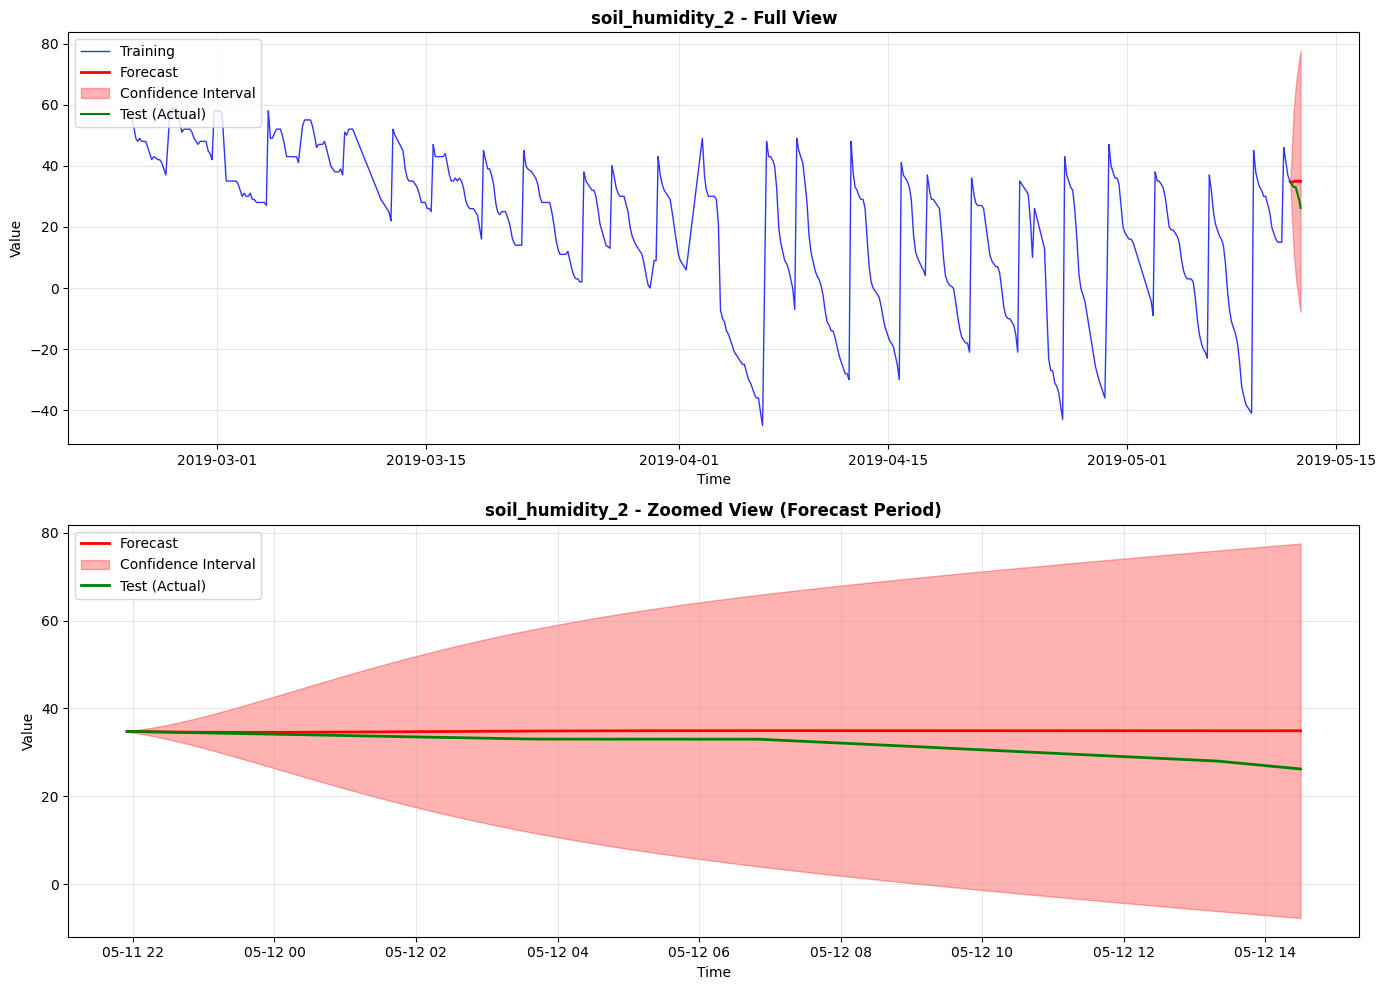


Processing: soil_humidity_4
Train size: 22439, Test size: 5610, Forecast steps: 200
ADF p-value: 0.0000 ✓ Stationary
Running simplified search (max 2 mins)...
✓ Best model: ARIMA(2, 0, 0) (fitted in 30.5s)
  AIC: -64989.68

📊 Metrics:
  RMSE: 9.2421
  MAE: 8.1566
  MAPE: 24.18%
  Directional Accuracy: 83.42%


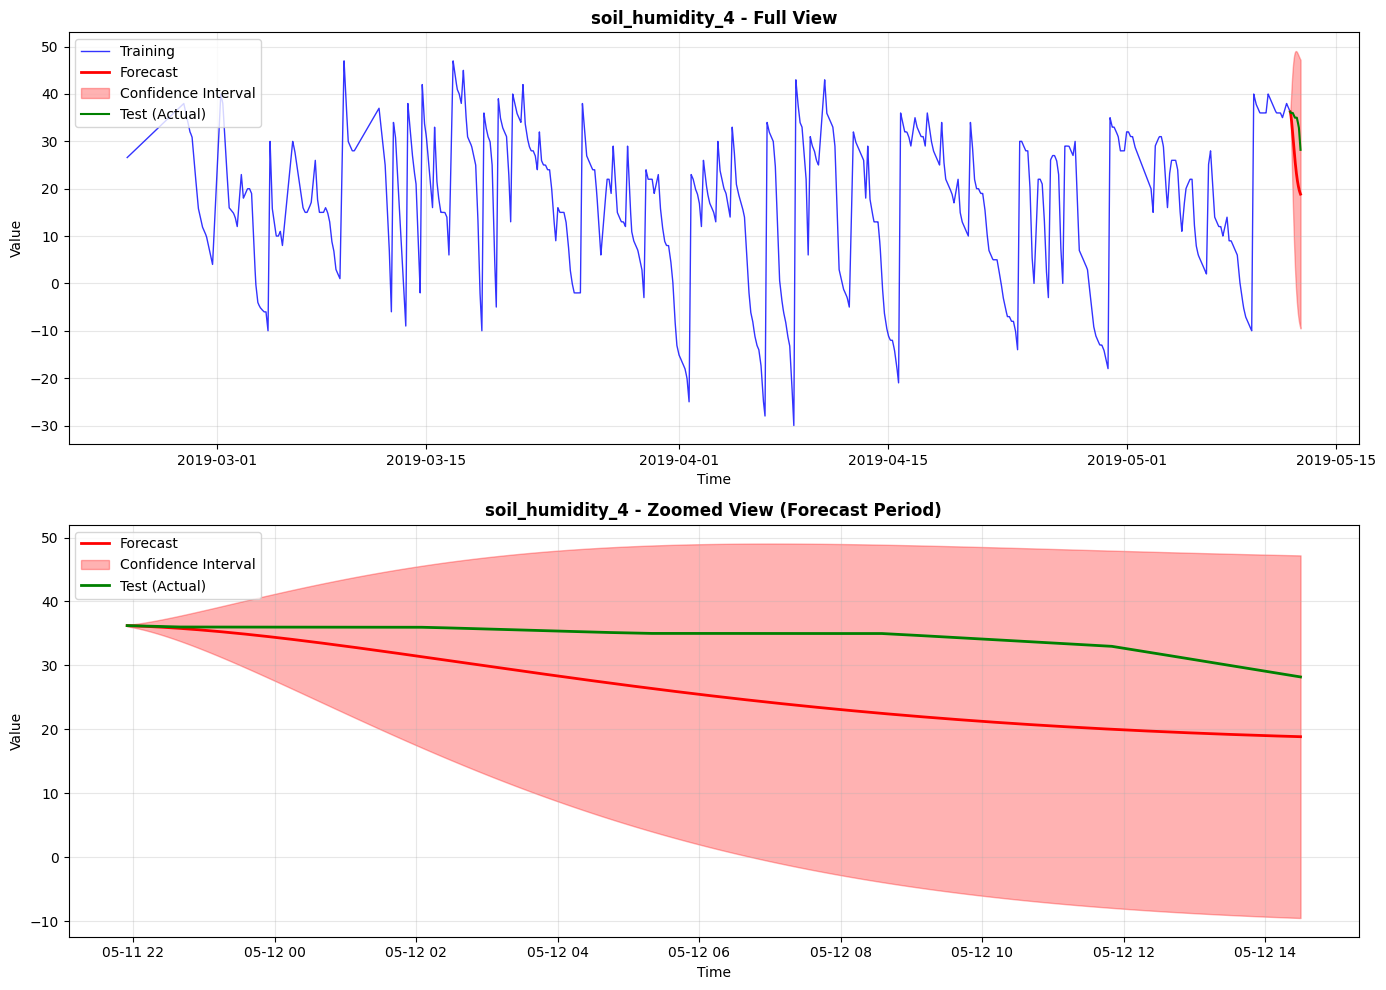


SUMMARY
                          Model      RMSE       MAE      MAPE%   Dir_Acc%  \
soil_humidity_2  ARIMA(2, 1, 2)  3.726934  2.917523   9.737374  61.809045   
soil_humidity_4  ARIMA(2, 0, 0)  9.242109  8.156625  24.179127  83.417085   

                   Time(s)  
soil_humidity_2  36.477356  
soil_humidity_4  30.547588  


In [44]:
results, summary = forecast_arima(
    denoised_df[['soil_humidity_2', 'soil_humidity_4']], 
    forecast_steps=200,
    use_auto=False
)

## 3.8 Advanced Extensions

### 3.8.1 Extension 1: SARIMAX Forecasting Model

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

class SARIMAForecaster:
    def __init__(self, df: pd.DataFrame):
        self.df = df.copy()
        self.df.columns = (
            self.df.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_")
            .str.replace("(", "")
            .str.replace(")", "")
        )

    def _check_stationarity(self, series):
        result = adfuller(series, autolag='AIC')
        return result[1] <= 0.05  # True if stationary

    def forecast(self, cols=None, forecast_steps=50, normalize=True, difference=False, plot=True):
        if cols is None:
            cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        elif isinstance(cols, str):
            cols = [cols]

        results = {}
        for col in cols:
            # Ensure the column exists and has no missing values
            if col not in self.df.columns:
                print(f"Column '{col}' not found in DataFrame.")
                results[col] = None
                continue

            series = self.df[col].dropna().astype(float).to_numpy()
            if len(series) == 0:
                print(f"Column '{col}' has no valid data after dropping NaN values.")
                results[col] = None
                continue

            original_series = series.copy()

            # Normalize
            scaler = None
            if normalize:
                scaler = MinMaxScaler()
                series = scaler.fit_transform(series.reshape(-1, 1)).flatten()

            # Difference
            if difference:
                series = np.diff(series, n=1)
                if len(series) == 0:
                    print(f"Column '{col}' has insufficient data after differencing.")
                    results[col] = None
                    continue

            try:
                # Split data into train and test
                # Use a more visible split: reserve forecast_steps for testing
                train_len = max(len(series) - forecast_steps, int(len(series) * 0.5))
                if train_len < 50:  # Ensure we have enough training data
                    train_len = 50
                
                train_series = series[:train_len]
                test_series = series[train_len:]
                actual_test_len = len(test_series)
                
                model = SARIMAX(train_series, order=(1, 0, 1), seasonal_order=(1, 0, 1, 24))
                fitted = model.fit(disp=False)

                forecast_res = fitted.get_forecast(steps=forecast_steps)
                forecast = forecast_res.predicted_mean
                forecast_ci = forecast_res.conf_int()  # No .to_numpy() needed

                # Inverse difference if needed
                if difference:
                    last_value = original_series[train_len - 1]
                    forecast = np.r_[last_value, forecast].cumsum()[1:]

                # Inverse scaling
                if normalize and scaler:
                    forecast = scaler.inverse_transform(forecast.reshape(-1, 1)).flatten()
                    forecast_ci = scaler.inverse_transform(forecast_ci)

                # Get actual test values from original series
                test_actual = original_series[train_len:]
                
                # Metrics - compare forecast with actual test data
                compare_len = min(len(test_actual), len(forecast))
                mse = mean_squared_error(test_actual[:compare_len], forecast[:compare_len])
                mae = mean_absolute_error(test_actual[:compare_len], forecast[:compare_len])
                mape = np.mean(np.abs((test_actual[:compare_len] - forecast[:compare_len]) / test_actual[:compare_len])) * 100
                stationary = self._check_stationarity(train_series)

                results[col] = {
                    "forecast": forecast,
                    "forecast_ci": forecast_ci,
                    "best_order": fitted.model_orders,
                    "aic": fitted.aic,
                    "stationary": stationary,
                    "mse": mse,
                    "mae": mae,
                    "mape": mape,
                    "train_len": train_len,
                    "test_actual": test_actual
                }

            except Exception as e:
                print(f"Forecasting failed for '{col}': {e}")
                results[col] = None

        # Print metrics table
        metrics_df = pd.DataFrame({
            col: {k: v for k, v in res.items() if k not in ['forecast', 'forecast_ci', 'train_len', 'test_actual']}
            for col, res in results.items() if res is not None
        }).T
        
        # Format MAPE to show with % symbol
        if 'mape' in metrics_df.columns:
            metrics_df_display = metrics_df.copy()
            metrics_df_display['mape'] = metrics_df_display['mape'].apply(lambda x: f"{x:.2f}%")
            print("\nForecast Metrics Summary:")
            print(metrics_df_display)
        else:
            print("\nForecast Metrics Summary:")
            print(metrics_df)

        # Plot
        if plot and metrics_df.shape[0] > 0:
            # Combined plot: full view and zoomed view alternating
            plt.figure(figsize=(14, 4 * len(cols) * 2))
            for i, col in enumerate(cols):
                if results[col] is None:
                    continue
                forecast = results[col]['forecast']
                ci = results[col]['forecast_ci']
                train_len = results[col]['train_len']
                test_actual = results[col]['test_actual']
                
                # Create forecast index based on DataFrame index type
                if isinstance(self.df.index, pd.DatetimeIndex):
                    train_end_time = self.df.index[train_len - 1]
                    freq = self.df.index.freq if self.df.index.freq is not None else pd.infer_freq(self.df.index)
                    if freq is None:
                        # Default to a reasonable frequency if none is set (e.g., 5 minutes)
                        freq = '5min'
                        print(f"Warning: No frequency found for '{col}'. Assuming 5-minute frequency ('5min').")
                    # Generate forecast index starting after the training data
                    forecast_index = pd.date_range(start=train_end_time, 
                                                  periods=forecast_steps + 1, 
                                                  freq=freq)[1:]
                    # Generate test index for actual values
                    test_index = pd.date_range(start=train_end_time,
                                              periods=len(test_actual) + 1,
                                              freq=freq)[1:]
                else:
                    # Fallback to numeric index if not datetime
                    forecast_index = pd.RangeIndex(start=self.df.index[train_len - 1] + 1, 
                                                  stop=self.df.index[train_len - 1] + 1 + forecast_steps)
                    test_index = pd.RangeIndex(start=self.df.index[train_len - 1] + 1,
                                              stop=self.df.index[train_len - 1] + 1 + len(test_actual))
                
                # FULL VIEW SUBPLOT
                plt.subplot(len(cols) * 2, 1, i * 2 + 1)
                
                # Plot training data
                plt.plot(self.df.index[:train_len], self.df[col].iloc[:train_len], 
                        label='Training', color='blue', alpha=0.7)

                # Plot forecast
                plt.plot(
                    forecast_index,
                    forecast, label='Forecast', color='red', linewidth=2
                )
                
                # Plot confidence interval
                plt.fill_between(
                    forecast_index,
                    ci[:, 0],
                    ci[:, 1],
                    color='red', alpha=0.3
                )
                
                # Plot test line (actual values in green)
                plt.plot(test_index, test_actual, label='Test (Actual)', 
                        color='green', linewidth=2, alpha=0.8)
                
                plt.title(f"{col} - Full View")
                plt.legend()
                
                # ZOOMED VIEW SUBPLOT
                plt.subplot(len(cols) * 2, 1, i * 2 + 2)
                
                # Plot forecast
                plt.plot(
                    forecast_index,
                    forecast, label='Forecast', color='red', linewidth=2
                )
                
                # Plot confidence interval
                plt.fill_between(
                    forecast_index,
                    ci[:, 0],
                    ci[:, 1],
                    color='red', alpha=0.3, label='Confidence Interval'
                )
                
                # Plot test line (actual values in green)
                plt.plot(test_index, test_actual, label='Test (Actual)', 
                        color='green', linewidth=2, alpha=0.8)
                
                plt.title(f"{col} - Zoomed View (Forecast Period)")
                plt.legend()
                plt.grid(True, alpha=0.3)
                
            plt.tight_layout()
            plt.savefig("./output/sarima_forecasting.png")
            plt.show()

        return results

# Example usage
# forecaster = SARIMAForecaster(signal_clean)
# res2 = forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], forecast_steps=200)


Forecast Metrics Summary:
                                                        best_order  \
soil_humidity_2  {'trend': 0, 'exog': 0, 'ar': 1, 'ma': 1, 'sea...   
soil_humidity_4  {'trend': 0, 'exog': 0, 'ar': 1, 'ma': 1, 'sea...   

                           aic stationary       mse       mae   mape  
soil_humidity_2 -272095.191268       True  1.424289   1.02086  3.93%  
soil_humidity_4 -259540.203602       True  0.000231  0.013938  0.09%  


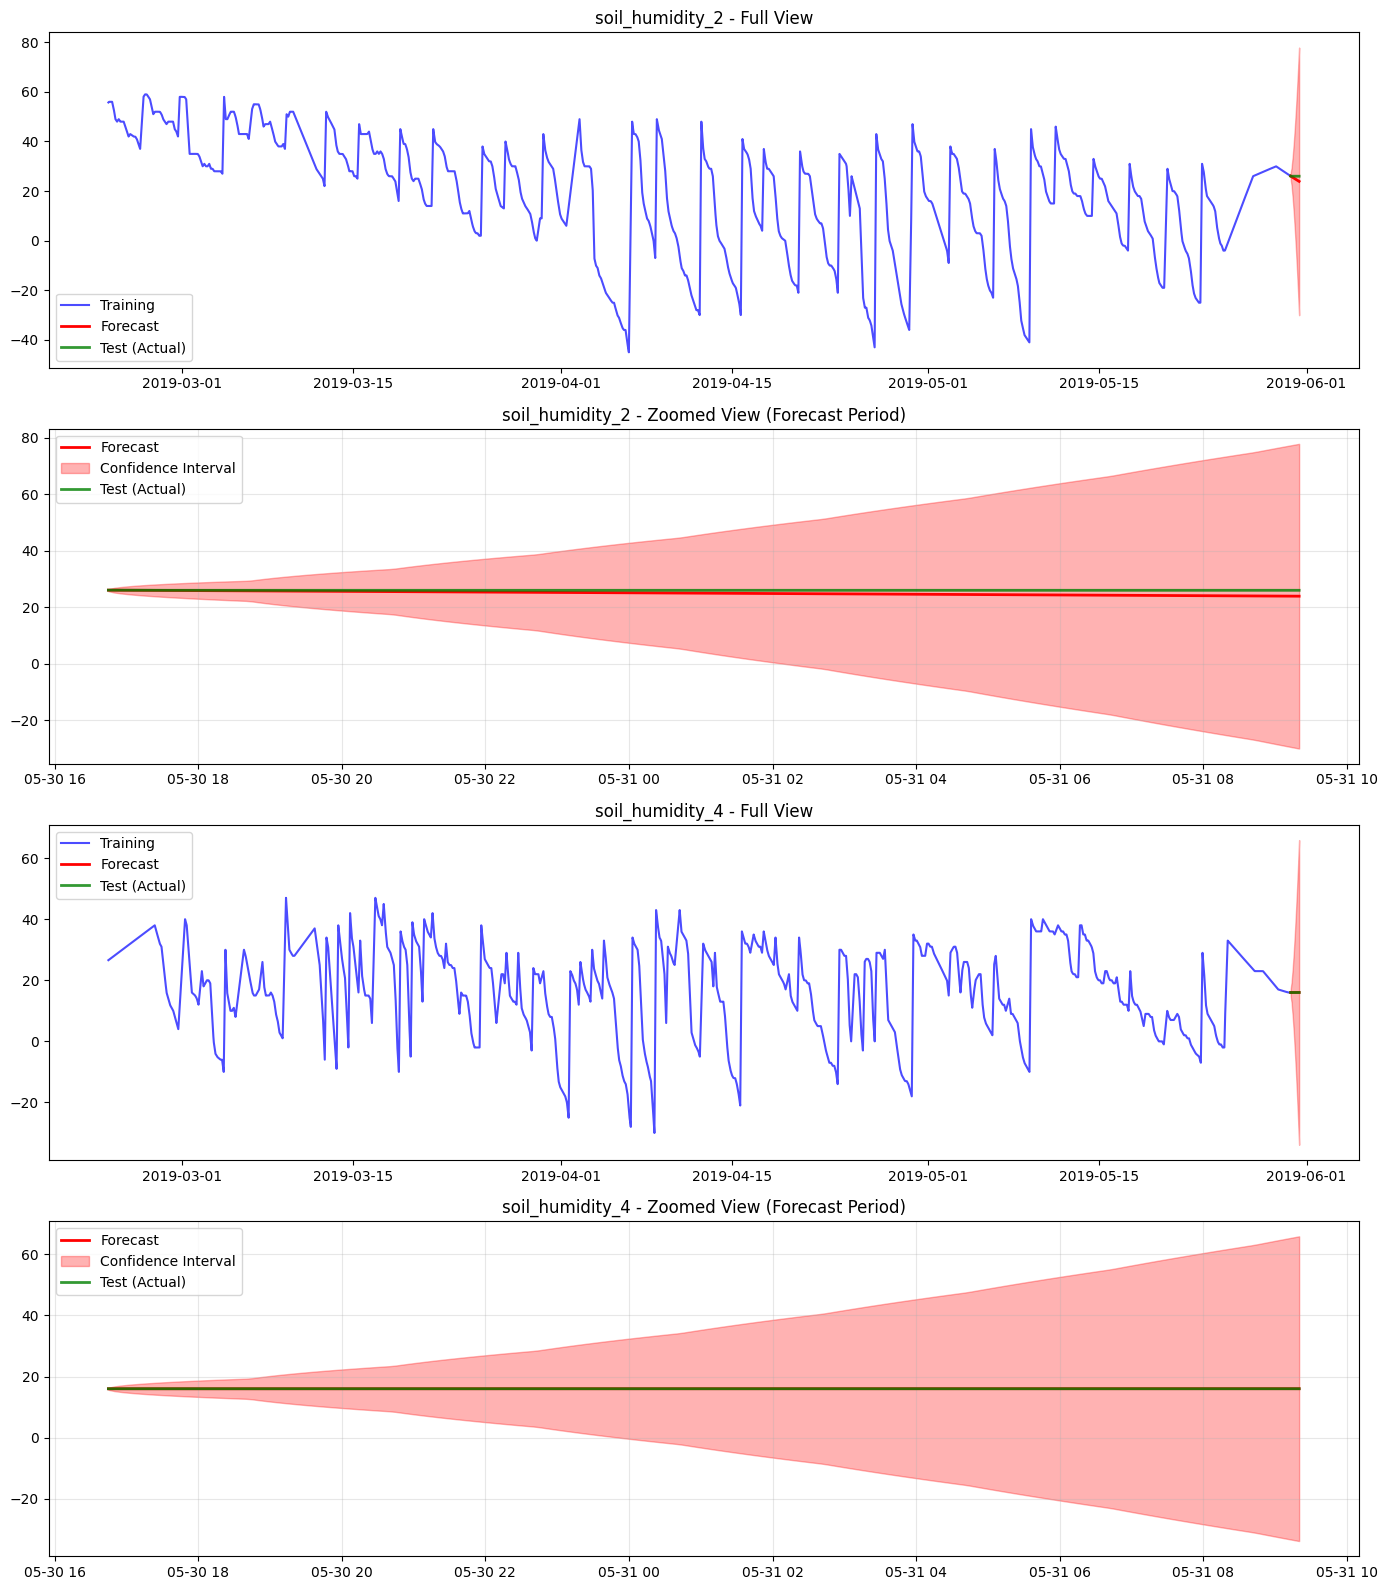

In [51]:
# Example usage
forecaster = SARIMAForecaster(denoised_df)
res2 = forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], forecast_steps=200)

### 3.8.2 Extension 2: Deep Learning with LSTM Networks

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

class LSTMForecaster:
    def __init__(self, df: pd.DataFrame):
        self.df = df.copy()
        self.df.columns = (
            self.df.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_")
            .str.replace("(", "")
            .str.replace(")", "")
        )
    
    def create_sequences(self, data, sequence_length):
        """Create sequences for LSTM training"""
        X, y = [], []
        for i in range(len(data) - sequence_length):
            X.append(data[i:(i + sequence_length)])
            y.append(data[i + sequence_length])
        return np.array(X), np.array(y)
    
    def forecast(self, cols=None, sequence_length=24, forecast_steps=200, 
                 epochs=100, batch_size=32, plot=True):
        if cols is None:
            cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        elif isinstance(cols, str):
            cols = [cols]
        
        results = {}
        
        for col in cols:
            # Ensure the column exists and has no missing values
            if col not in self.df.columns:
                print(f"Column '{col}' not found in DataFrame.")
                results[col] = None
                continue
            
            series = self.df[col].dropna().astype(float).to_numpy()
            if len(series) == 0:
                print(f"Column '{col}' has no valid data after dropping NaN values.")
                results[col] = None
                continue
            
            if len(series) < sequence_length + 50:
                print(f"Column '{col}' has insufficient data. Need at least {sequence_length + 50} points.")
                results[col] = None
                continue
            
            # Scale data
            scaler = MinMaxScaler()
            scaled_data = scaler.fit_transform(series.reshape(-1, 1)).flatten()
            
            # Create sequences
            X, y = self.create_sequences(scaled_data, sequence_length)
            
            # Split data into train and test
            train_len = max(len(X) - forecast_steps, int(len(X) * 0.5))
            if train_len < 50:
                train_len = 50
            
            X_train, X_test = X[:train_len], X[train_len:]
            y_train, y_test = y[:train_len], y[train_len:]
            
            # Reshape for LSTM (samples, time steps, features)
            X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
            X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
            
            try:
                # Build LSTM model
                model = Sequential([
                    LSTM(50, return_sequences=True, input_shape=(sequence_length, 1)),
                    Dropout(0.2),
                    LSTM(50, return_sequences=True),
                    Dropout(0.2),
                    LSTM(50),
                    Dropout(0.2),
                    Dense(25),
                    Dense(1)
                ])
                
                model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])
                
                # Early stopping callback
                early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
                
                # Train the model
                print(f"\nTraining LSTM model for '{col}'...")
                history = model.fit(X_train, y_train, 
                                   batch_size=batch_size, 
                                   epochs=epochs, 
                                   validation_split=0.2,
                                   callbacks=[early_stop],
                                   verbose=0)
                
                # Make predictions
                predictions = model.predict(X_test, verbose=0)
                predictions = scaler.inverse_transform(predictions.reshape(-1, 1)).flatten()
                y_test_rescaled = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
                
                # Calculate prediction errors for confidence interval
                residuals = y_test_rescaled - predictions
                std_error = np.std(residuals)
                
                # 95% confidence interval (1.96 * std_error)
                ci_lower = predictions - 1.96 * std_error
                ci_upper = predictions + 1.96 * std_error
                
                # Calculate metrics
                mse = mean_squared_error(y_test_rescaled, predictions)
                mae = mean_absolute_error(y_test_rescaled, predictions)
                mape = np.mean(np.abs((y_test_rescaled - predictions) / y_test_rescaled)) * 100
                
                # Get training data (original series up to where test starts)
                train_data_len = train_len + sequence_length
                
                results[col] = {
                    "predictions": predictions,
                    "test_actual": y_test_rescaled,
                    "ci_lower": ci_lower,
                    "ci_upper": ci_upper,
                    "train_data_len": train_data_len,
                    "mse": mse,
                    "mae": mae,
                    "mape": mape,
                    "history": history
                }
                
                print(f"Training completed for '{col}'")
                
            except Exception as e:
                print(f"LSTM training failed for '{col}': {e}")
                results[col] = None
        
        # Print metrics table
        metrics_df = pd.DataFrame({
            col: {k: v for k, v in res.items() if k not in ['predictions', 'test_actual', 'ci_lower', 'ci_upper', 'train_data_len', 'history']}
            for col, res in results.items() if res is not None
        }).T
        
        # Format MAPE to show with % symbol
        if 'mape' in metrics_df.columns:
            metrics_df_display = metrics_df.copy()
            metrics_df_display['mape'] = metrics_df_display['mape'].apply(lambda x: f"{x:.2f}%")
            print("\nLSTM Forecast Metrics Summary:")
            print(metrics_df_display)
        else:
            print("\nLSTM Forecast Metrics Summary:")
            print(metrics_df)
        
        # Plot
        if plot and metrics_df.shape[0] > 0:
            # Combined plot: full view and zoomed view alternating
            plt.figure(figsize=(14, 4 * len(cols) * 2))
            for i, col in enumerate(cols):
                if results[col] is None:
                    continue
                
                predictions = results[col]['predictions']
                test_actual = results[col]['test_actual']
                ci_lower = results[col]['ci_lower']
                ci_upper = results[col]['ci_upper']
                train_data_len = results[col]['train_data_len']
                
                # Create prediction index based on DataFrame index type
                if isinstance(self.df.index, pd.DatetimeIndex):
                    train_end_time = self.df.index[train_data_len - 1]
                    freq = self.df.index.freq if self.df.index.freq is not None else pd.infer_freq(self.df.index)
                    if freq is None:
                        freq = '5min'
                        print(f"Warning: No frequency found for '{col}'. Assuming 5-minute frequency ('5min').")
                    
                    # Generate prediction index starting after the training data
                    pred_index = pd.date_range(start=train_end_time, 
                                              periods=len(predictions) + 1, 
                                              freq=freq)[1:]
                else:
                    # Fallback to numeric index if not datetime
                    pred_index = pd.RangeIndex(start=self.df.index[train_data_len - 1] + 1, 
                                              stop=self.df.index[train_data_len - 1] + 1 + len(predictions))
                
                # FULL VIEW SUBPLOT
                plt.subplot(len(cols) * 2, 1, i * 2 + 1)
                
                # Plot training data
                plt.plot(self.df.index[:train_data_len], self.df[col].iloc[:train_data_len], 
                        label='Training', color='blue', alpha=0.7)
                
                # Plot predictions
                plt.plot(pred_index, predictions, label='LSTM Prediction', 
                        color='purple', linewidth=2)
                
                # Plot confidence interval
                plt.fill_between(pred_index, ci_lower, ci_upper, 
                                alpha=0.3, color='purple', label='Confidence Interval')
                
                # Plot test actual
                plt.plot(pred_index, test_actual, label='Test (Actual)', 
                        color='green', linewidth=2, alpha=0.8)
                
                plt.title(f"{col} - LSTM Forecast (Full View)")
                plt.legend()
                plt.ylabel('Value')
                
                # ZOOMED VIEW SUBPLOT
                plt.subplot(len(cols) * 2, 1, i * 2 + 2)
                
                # Plot predictions
                plt.plot(pred_index, predictions, label='LSTM Prediction', 
                        color='purple', linewidth=2)
                
                # Plot confidence interval
                plt.fill_between(pred_index, ci_lower, ci_upper, 
                                alpha=0.3, color='purple', label='Confidence Interval')
                
                # Plot test actual
                plt.plot(pred_index, test_actual, label='Test (Actual)', 
                        color='green', linewidth=2, alpha=0.8)
                
                plt.title(f"{col} - LSTM Forecast (Zoomed View)")
                plt.legend()
                plt.ylabel('Value')
                plt.grid(True, alpha=0.3)
            
            plt.tight_layout()
            plt.savefig("./output/lstm_forecasting.png")
            plt.show()
        
        return results

# Example usage
# forecaster = LSTMForecaster(signal_clean)
# results = forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], 
#                               sequence_length=24, 
#                               forecast_steps=200,
#                               epochs=100)


Training LSTM model for 'soil_humidity_2'...
Training completed for 'soil_humidity_2'

Training LSTM model for 'soil_humidity_4'...
Training completed for 'soil_humidity_4'

LSTM Forecast Metrics Summary:
                      mse       mae   mape
soil_humidity_2  0.003019  0.054835  0.21%
soil_humidity_4  0.001627  0.040333  0.25%


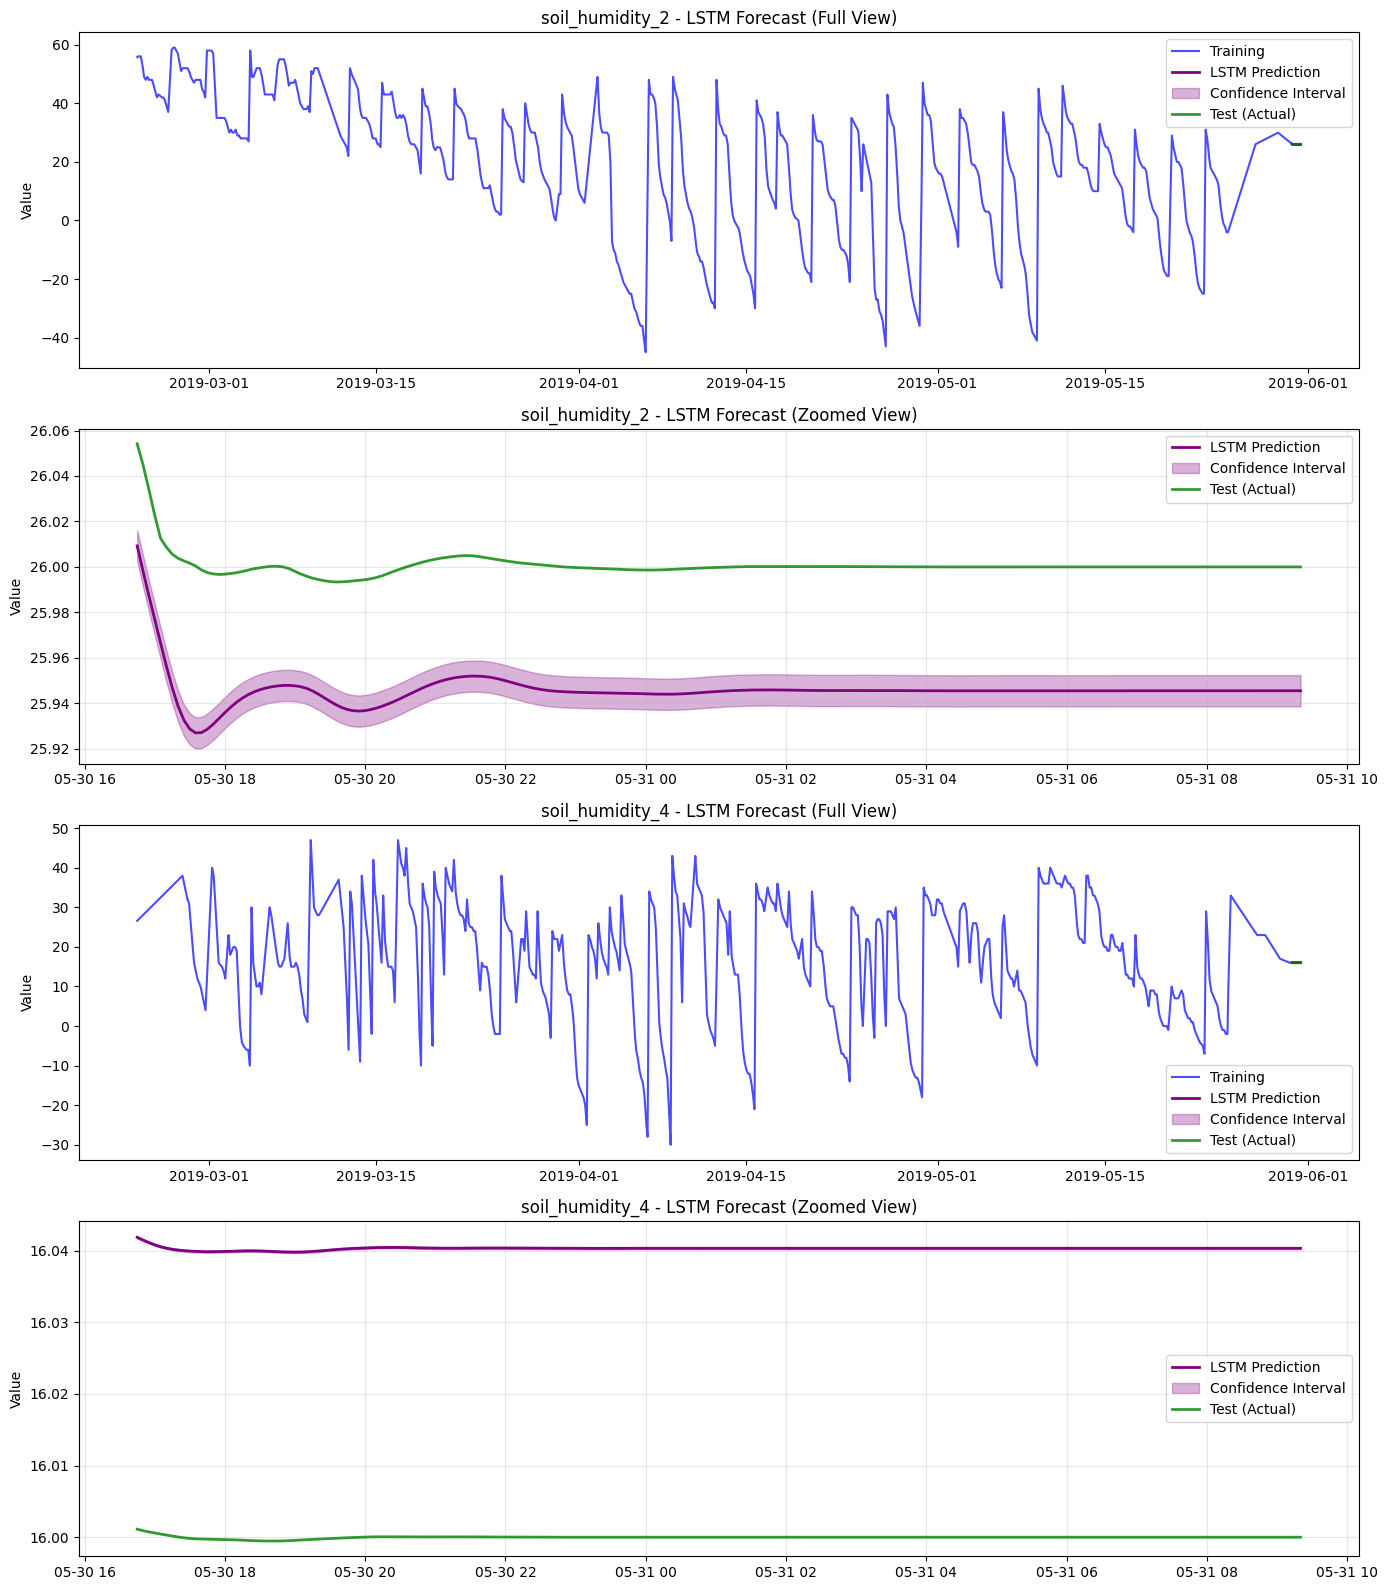

In [46]:
# Example usage
forecaster = LSTMForecaster(denoised_df[['soil_humidity_2', 'soil_humidity_4']], 
)
results = forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], 
                               sequence_length=24, 
                               forecast_steps=200,
                               epochs=100)

### 3.8.3 Extension 3: Multiresolution Decomposition for Trend-Seasonal-Noise Separation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

class WaveletForecaster:
    def __init__(self, df: pd.DataFrame):
        self.df = df.copy()
        self.df.columns = (
            self.df.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_")
            .str.replace("(", "")
            .str.replace(")", "")
        )
    
    def select_optimal_wavelet(self, signal):
        """Automatically select the best wavelet based on decomposition quality"""
        wavelets = ['db4', 'db8', 'sym4', 'coif3', 'haar']
        best_wavelet = 'db4'
        best_score = -np.inf
        
        for wavelet in wavelets:
            try:
                coeffs = pywt.wavedec(signal, wavelet, level=3)
                # Score based on energy concentration in approximation
                approx_energy = np.sum(coeffs[0]**2)
                total_energy = sum(np.sum(c**2) for c in coeffs)
                score = approx_energy / total_energy if total_energy > 0 else 0
                
                if score > best_score:
                    best_score = score
                    best_wavelet = wavelet
            except:
                continue
        
        return best_wavelet
    
    def detect_optimal_levels(self, signal, wavelet='db4'):
        """Determine optimal decomposition levels using energy criterion"""
        max_level = pywt.dwt_max_level(len(signal), wavelet)
        
        # Test different levels and find where detail energy becomes negligible
        for level in range(1, min(max_level, 10)):
            coeffs = pywt.wavedec(signal, wavelet, level=level)
            detail_energy = sum(np.sum(c**2) for c in coeffs[1:])
            total_energy = sum(np.sum(c**2) for c in coeffs)
            
            # If details contain less than 5% of energy, we've gone deep enough
            if detail_energy / total_energy < 0.05:
                return level
        
        return min(5, max_level)
    
    def multiresolution_decomposition(self, signal, wavelet='db4', levels=None):
        """
        Multiresolution decomposition to separate trend, seasonal, and noise components
        (Preserves noise characteristics - no thresholding applied)
        """
        if levels is None:
            levels = self.detect_optimal_levels(signal, wavelet)
        
        max_levels = pywt.dwt_max_level(len(signal), wavelet)
        levels = min(levels, max_levels)
        
        coeffs = pywt.wavedec(signal, wavelet, level=levels)
        
        # Reconstruct different frequency components
        # Low frequency = trend (approximation coefficient)
        trend = pywt.waverec([coeffs[0]] + [np.zeros_like(c) for c in coeffs[1:]], wavelet)
        
        # Mid frequency = seasonal patterns (detail coefficients at lower levels)
        seasonal_components = []
        seasonal_levels = min(3, len(coeffs) - 1)  # Use first 3 detail levels for seasonal
        for i in range(1, seasonal_levels + 1):
            if i < len(coeffs):
                temp_coeffs = [np.zeros_like(coeffs[0])] + [np.zeros_like(c) for c in coeffs[1:]]
                temp_coeffs[i] = coeffs[i]
                seasonal_components.append(pywt.waverec(temp_coeffs, wavelet))
        
        seasonal = np.sum(seasonal_components, axis=0) if seasonal_components else np.zeros_like(signal)
        
        # High-frequency components (noise) - remaining detail coefficients
        # This should include all detail levels AFTER the seasonal levels
        noise_coeffs = [np.zeros_like(coeffs[0])] + [np.zeros_like(c) for c in coeffs[1:]]
        has_noise = False
        for i in range(seasonal_levels + 1, len(coeffs)):
            noise_coeffs[i] = coeffs[i]
            has_noise = True
        
        if has_noise:
            noise = pywt.waverec(noise_coeffs, wavelet)
        else:
            # If no high-frequency levels exist, compute noise as residual
            reconstructed = pywt.waverec(coeffs, wavelet)
            min_len = min(len(reconstructed), len(signal))
            noise = signal[:min_len] - trend[:min_len] - seasonal[:min_len]
        
        # Ensure all components are same length as signal
        min_len = min(len(trend), len(seasonal), len(noise), len(signal))
        
        return trend[:min_len], seasonal[:min_len], noise[:min_len]
    
    def forecast_component(self, component, model_type='arima', forecast_steps=30):
        """Enhanced forecasting with better model selection"""
        try:
            if model_type == 'arima':
                # Use auto_arima-like approach with more sophisticated selection
                best_aic = np.inf
                best_forecast = None
                
                # Expanded order search
                p_range = range(0, 4)
                d_range = range(0, 2)
                q_range = range(0, 4)
                
                orders = [(p, d, q) for p in p_range for d in d_range for q in q_range 
                         if (p + d + q) > 0 and (p + d + q) <= 5]
                
                for order in orders[:15]:  # Limit search to avoid overfitting
                    try:
                        model = ARIMA(component, order=order)
                        fitted_model = model.fit()
                        if fitted_model.aic < best_aic:
                            best_aic = fitted_model.aic
                            best_forecast = fitted_model.forecast(steps=forecast_steps)
                    except:
                        continue
                
                if best_forecast is not None:
                    return best_forecast
                    
            elif model_type == 'seasonal':
                # Seasonal forecasting with FFT-based period detection
                from scipy import signal as scipy_signal
                
                try:
                    # Detect dominant frequency using FFT
                    fft = np.fft.fft(component)
                    freqs = np.fft.fftfreq(len(component))
                    magnitude = np.abs(fft)
                    
                    # Find dominant period (excluding DC component)
                    peak_freq_idx = np.argmax(magnitude[1:len(magnitude)//2]) + 1
                    dominant_period = int(1 / abs(freqs[peak_freq_idx])) if freqs[peak_freq_idx] != 0 else 12
                    dominant_period = min(max(dominant_period, 2), len(component) // 3)
                    
                    # Use SARIMAX with detected period
                    from statsmodels.tsa.statespace.sarimax import SARIMAX
                    model = SARIMAX(component, order=(1, 0, 1), 
                                  seasonal_order=(1, 0, 1, dominant_period))
                    fitted_model = model.fit(disp=False, maxiter=100)
                    return fitted_model.forecast(steps=forecast_steps)
                except:
                    # Fallback: repeat last cycle
                    if len(component) >= forecast_steps:
                        return component[-forecast_steps:]
                    else:
                        repeats = int(np.ceil(forecast_steps / len(component)))
                        return np.tile(component, repeats)[:forecast_steps]
                        
            elif model_type == 'trend':
                # Use exponential smoothing for trend
                from statsmodels.tsa.holtwinters import ExponentialSmoothing
                try:
                    model = ExponentialSmoothing(component, trend='add', seasonal=None)
                    fitted = model.fit()
                    return fitted.forecast(steps=forecast_steps)
                except:
                    # Fallback to linear extrapolation
                    x = np.arange(len(component))
                    coeffs = np.polyfit(x, component, 1)
                    future_x = np.arange(len(component), len(component) + forecast_steps)
                    return np.polyval(coeffs, future_x)
            else:
                # For noise: zero mean assumption after denoising
                return np.zeros(forecast_steps)
                
        except Exception as e:
            # Fallback
            return np.full(forecast_steps, np.mean(component[-min(10, len(component)):]))
    
    def forecast(self, cols=None, wavelet='auto', levels=None, forecast_steps=200, plot=True):
        if cols is None:
            cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        elif isinstance(cols, str):
            cols = [cols]
        
        results = {}
        
        for col in cols:
            if col not in self.df.columns:
                print(f"Column '{col}' not found in DataFrame.")
                results[col] = None
                continue
            
            series = self.df[col].dropna().astype(float).to_numpy()
            if len(series) < 100:
                print(f"Column '{col}' has insufficient data for wavelet decomposition.")
                results[col] = None
                continue
            
            try:
                # Split data
                train_len = max(len(series) - forecast_steps, int(len(series) * 0.7))
                train_series = series[:train_len]
                test_series = series[train_len:]
                
                print(f"\nProcessing '{col}' with enhanced wavelet decomposition...")
                
                # Auto-select wavelet if requested
                if wavelet == 'auto':
                    selected_wavelet = self.select_optimal_wavelet(train_series)
                    print(f"  Selected wavelet: {selected_wavelet}")
                else:
                    selected_wavelet = wavelet
                
                # Decompose
                trend, seasonal, noise = self.multiresolution_decomposition(
                    train_series, wavelet=selected_wavelet, levels=levels
                )
                
                # Forecast each component
                trend_forecast = self.forecast_component(trend, 'trend', forecast_steps)
                seasonal_forecast = self.forecast_component(seasonal, 'seasonal', forecast_steps)
                noise_forecast = self.forecast_component(noise, 'noise', forecast_steps)
                
                # Combine
                combined_forecast = trend_forecast + seasonal_forecast + noise_forecast
                
                # Calculate metrics
                compare_len = min(len(test_series), len(combined_forecast))
                mse = mean_squared_error(test_series[:compare_len], combined_forecast[:compare_len])
                mae = mean_absolute_error(test_series[:compare_len], combined_forecast[:compare_len])
                
                # Avoid division by zero in MAPE
                mask = test_series[:compare_len] != 0
                if np.sum(mask) > 0:
                    mape = np.mean(np.abs((test_series[:compare_len][mask] - 
                                         combined_forecast[:compare_len][mask]) / 
                                        test_series[:compare_len][mask])) * 100
                else:
                    mape = np.nan
                
                # Adaptive confidence intervals based on component uncertainties
                residuals = test_series[:compare_len] - combined_forecast[:compare_len]
                std_error = np.std(residuals) if len(residuals) > 0 else np.std(train_series) * 0.1
                
                ci_lower = combined_forecast - 1.96 * std_error
                ci_upper = combined_forecast + 1.96 * std_error
                
                results[col] = {
                    "forecast": combined_forecast,
                    "ci_lower": ci_lower,
                    "ci_upper": ci_upper,
                    "test_actual": test_series,
                    "train_len": train_len,
                    "trend": trend,
                    "seasonal": seasonal,
                    "noise": noise,
                    "wavelet_used": selected_wavelet,
                    "mse": mse,
                    "mae": mae,
                    "mape": mape
                }
                
                print(f"  MSE: {mse:.4f}, MAE: {mae:.4f}, MAPE: {mape:.2f}%")
                
            except Exception as e:
                print(f"Wavelet forecasting failed for '{col}': {e}")
                results[col] = None
        
        # Print metrics table
        metrics_df = pd.DataFrame({
            col: {k: v for k, v in res.items() if k not in ['forecast', 'ci_lower', 'ci_upper', 'test_actual', 'train_len', 
                                                             'trend', 'seasonal', 'noise', 'wavelet_used']}
            for col, res in results.items() if res is not None
        }).T
        
        # Format MAPE to show with % symbol
        if 'mape' in metrics_df.columns and len(metrics_df) > 0:
            metrics_df_display = metrics_df.copy()
            metrics_df_display['mape'] = metrics_df_display['mape'].apply(lambda x: f"{x:.2f}%" if not np.isnan(x) else "N/A")
            print("\nWavelet Forecast Metrics Summary:")
            print(metrics_df_display)
        elif len(metrics_df) > 0:
            print("\nWavelet Forecast Metrics Summary:")
            print(metrics_df)
        
        # Plot
        if plot and len(metrics_df) > 0:
            for col in cols:
                if results[col] is None:
                    continue
                
                train_len = results[col]['train_len']
                trend = results[col]['trend']
                seasonal = results[col]['seasonal']
                noise = results[col]['noise']
                forecast = results[col]['forecast']
                ci_lower = results[col]['ci_lower']
                ci_upper = results[col]['ci_upper']
                test_actual = results[col]['test_actual']
                wavelet_used = results[col]['wavelet_used']
                
                # Decomposition plots
                fig, axes = plt.subplots(4, 1, figsize=(14, 12))
                
                train_index = self.df.index[:train_len]
                
                axes[0].plot(train_index, self.df[col].iloc[:train_len], color='blue')
                axes[0].set_title(f'{col} - Original Training Signal (Wavelet: {wavelet_used})', 
                                fontsize=14, fontweight='bold')
                axes[0].grid(True, alpha=0.3)
                axes[0].set_ylabel('Value')
                
                axes[1].plot(train_index, trend, color='red')
                axes[1].set_title('Trend Component (Low Frequency)', fontsize=14, fontweight='bold')
                axes[1].grid(True, alpha=0.3)
                axes[1].set_ylabel('Value')
                
                axes[2].plot(train_index, seasonal, color='green')
                axes[2].set_title('Seasonal Component (Mid Frequency)', fontsize=14, fontweight='bold')
                axes[2].grid(True, alpha=0.3)
                axes[2].set_ylabel('Value')
                
                axes[3].plot(train_index, noise, color='gray')
                axes[3].set_title('Noise Component (High Frequency)', fontsize=14, fontweight='bold')
                axes[3].set_xlabel('Time')
                axes[3].grid(True, alpha=0.3)
                axes[3].set_ylabel('Value')
                
                plt.tight_layout()
                plt.savefig(f"./output/wavelet_decomposition_{col}.png")
                plt.show()
                
                # Forecast plots (full view and zoomed)
                fig, axes = plt.subplots(2, 1, figsize=(14, 8))
                
                # Create forecast index
                if isinstance(self.df.index, pd.DatetimeIndex):
                    train_end_time = self.df.index[train_len - 1]
                    freq = self.df.index.freq if self.df.index.freq is not None else pd.infer_freq(self.df.index)
                    if freq is None:
                        freq = '5min'
                        print(f"Warning: No frequency found for '{col}'. Assuming 5-minute frequency ('5min').")
                    
                    forecast_index = pd.date_range(start=train_end_time, 
                                                  periods=forecast_steps + 1, 
                                                  freq=freq)[1:]
                    test_index = pd.date_range(start=train_end_time,
                                              periods=len(test_actual) + 1,
                                              freq=freq)[1:]
                else:
                    forecast_index = pd.RangeIndex(start=self.df.index[train_len - 1] + 1, 
                                                  stop=self.df.index[train_len - 1] + 1 + forecast_steps)
                    test_index = pd.RangeIndex(start=self.df.index[train_len - 1] + 1,
                                              stop=self.df.index[train_len - 1] + 1 + len(test_actual))
                
                # FULL VIEW
                axes[0].plot(self.df.index[:train_len], self.df[col].iloc[:train_len], 
                           label='Training', color='blue', alpha=0.7)
                axes[0].plot(forecast_index, forecast, label='Wavelet Forecast', 
                           color='red', linewidth=2)
                axes[0].fill_between(forecast_index, ci_lower, ci_upper, 
                                    alpha=0.3, color='red', label='95% Confidence Interval')
                axes[0].plot(test_index, test_actual, label='Test (Actual)', 
                           color='green', linewidth=2, alpha=0.8)
                axes[0].set_title(f'{col} - Multiresolution Forecast (Full View)', 
                                fontsize=14, fontweight='bold')
                axes[0].legend()
                axes[0].grid(True, alpha=0.3)
                axes[0].set_ylabel('Value')
                
                # ZOOMED VIEW
                axes[1].plot(forecast_index, forecast, label='Wavelet Forecast', 
                           color='red', linewidth=2)
                axes[1].fill_between(forecast_index, ci_lower, ci_upper, 
                                    alpha=0.3, color='red', label='95% Confidence Interval')
                axes[1].plot(test_index, test_actual, label='Test (Actual)', 
                           color='green', linewidth=2, alpha=0.8)
                axes[1].set_title(f'{col} - Multiresolution Forecast (Zoomed View)', 
                                fontsize=14, fontweight='bold')
                axes[1].legend()
                axes[1].grid(True, alpha=0.3)
                axes[1].set_xlabel('Time')
                axes[1].set_ylabel('Value')
                
                plt.tight_layout()
                plt.savefig(f"./output/wavelet_forecasting_{col}.png")
                plt.show()
        
        return results

# Usage:
# forecaster = WaveletForecaster(signal_clean)
# results = forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], 
#                               wavelet='auto',  # Auto-select best wavelet
#                               levels=None,     # Auto-detect optimal levels
#                               forecast_steps=200)


Processing 'soil_humidity_2' with enhanced wavelet decomposition...
  Selected wavelet: db8
  MSE: 1.1428, MAE: 0.9112, MAPE: 3.50%

Processing 'soil_humidity_4' with enhanced wavelet decomposition...
  Selected wavelet: coif3
  MSE: 0.0004, MAE: 0.0168, MAPE: 0.10%

Enhanced Wavelet Forecast Metrics Summary:
                      mse       mae   mape
soil_humidity_2  1.142784  0.911214  3.50%
soil_humidity_4  0.000390  0.016781  0.10%


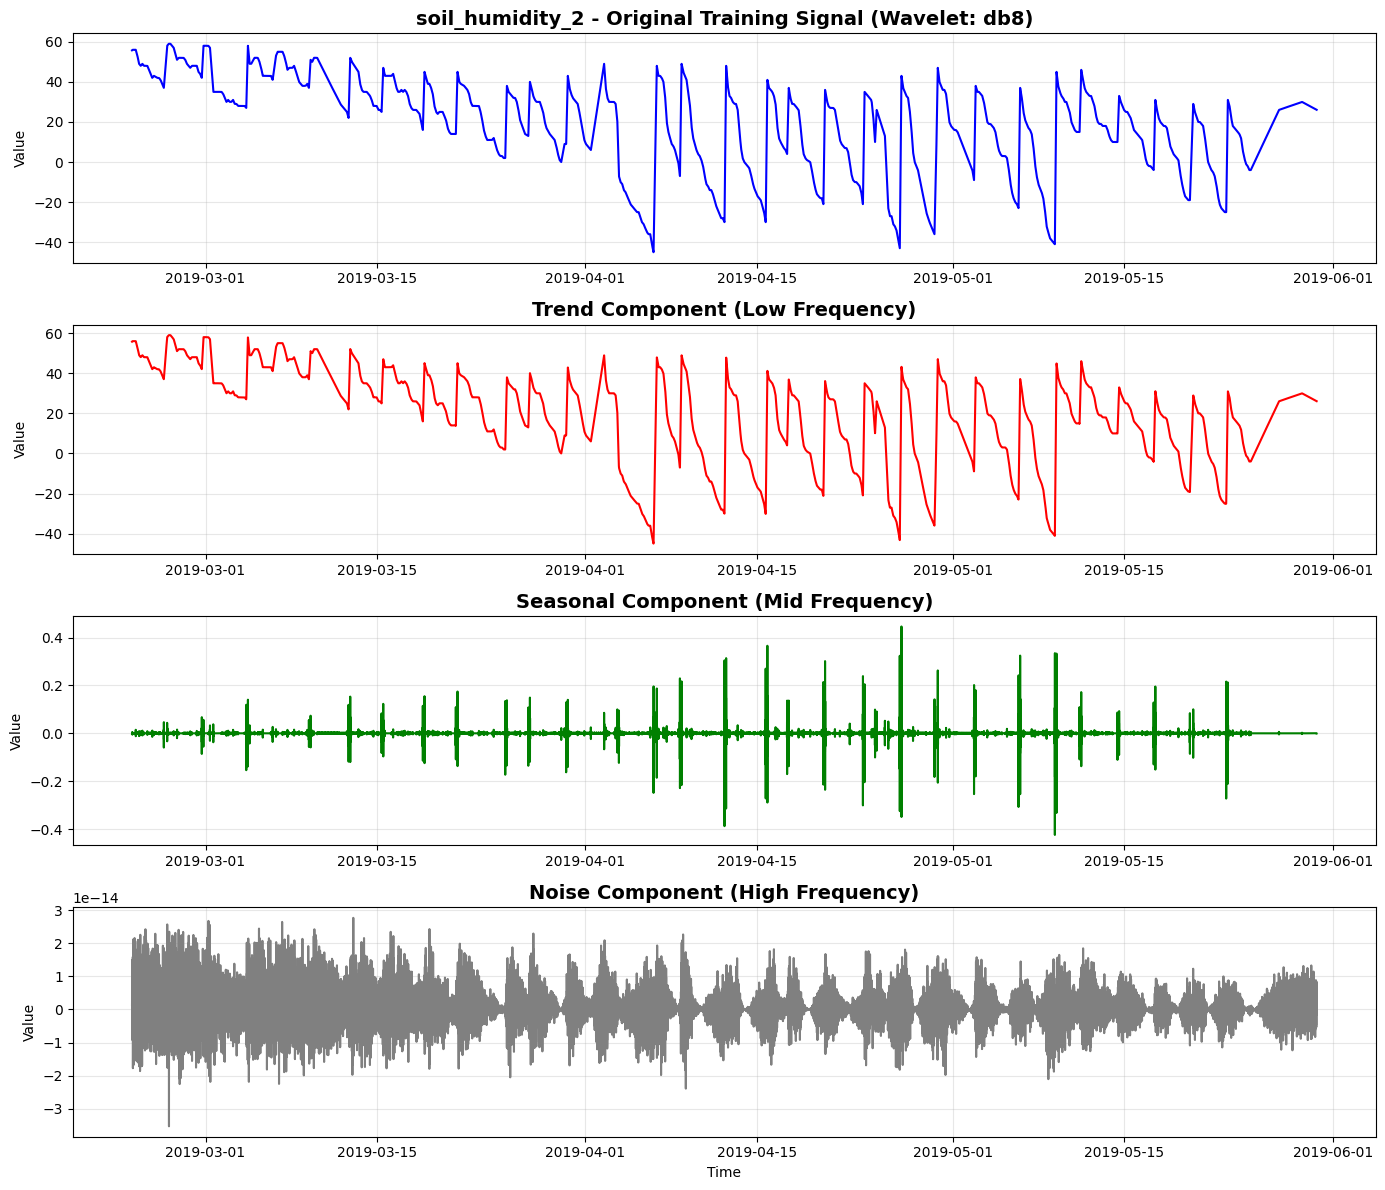

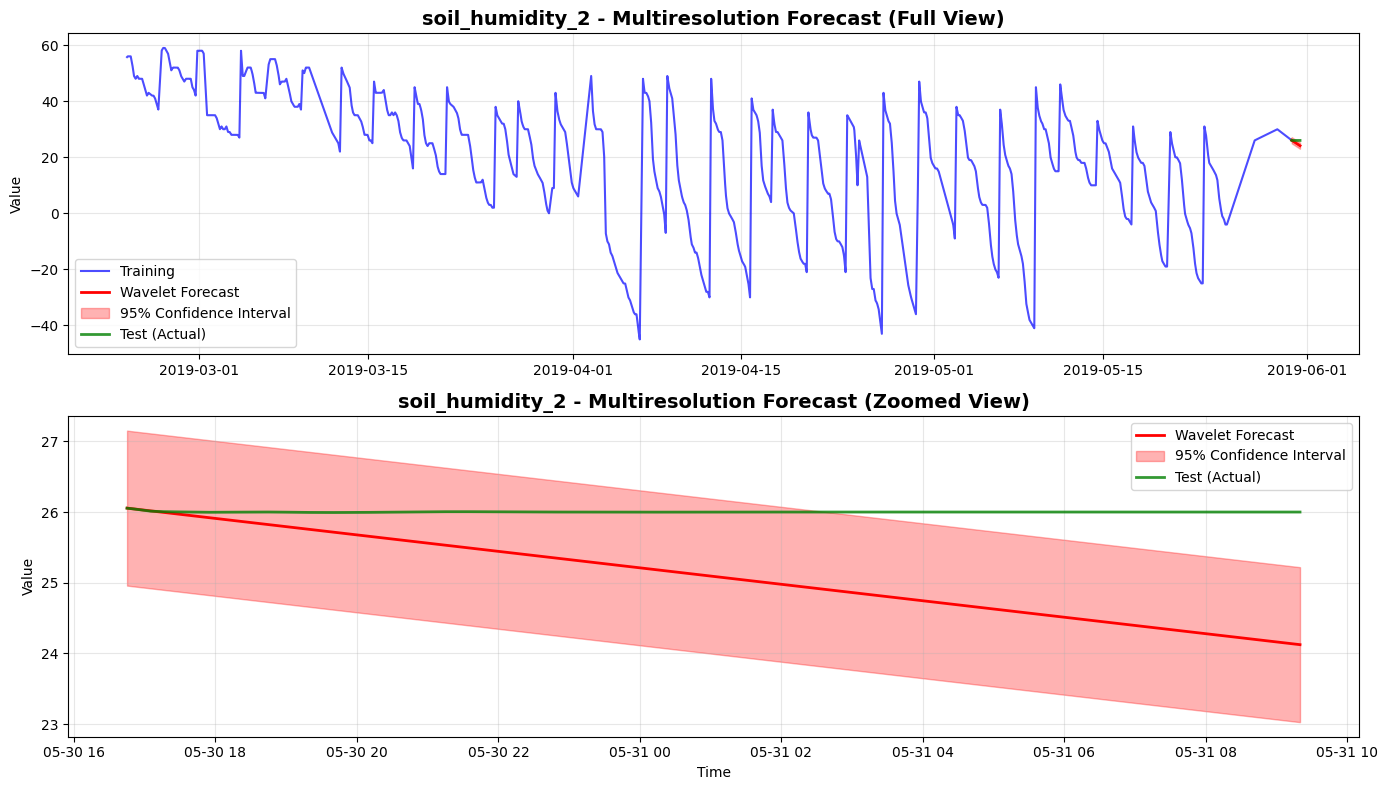

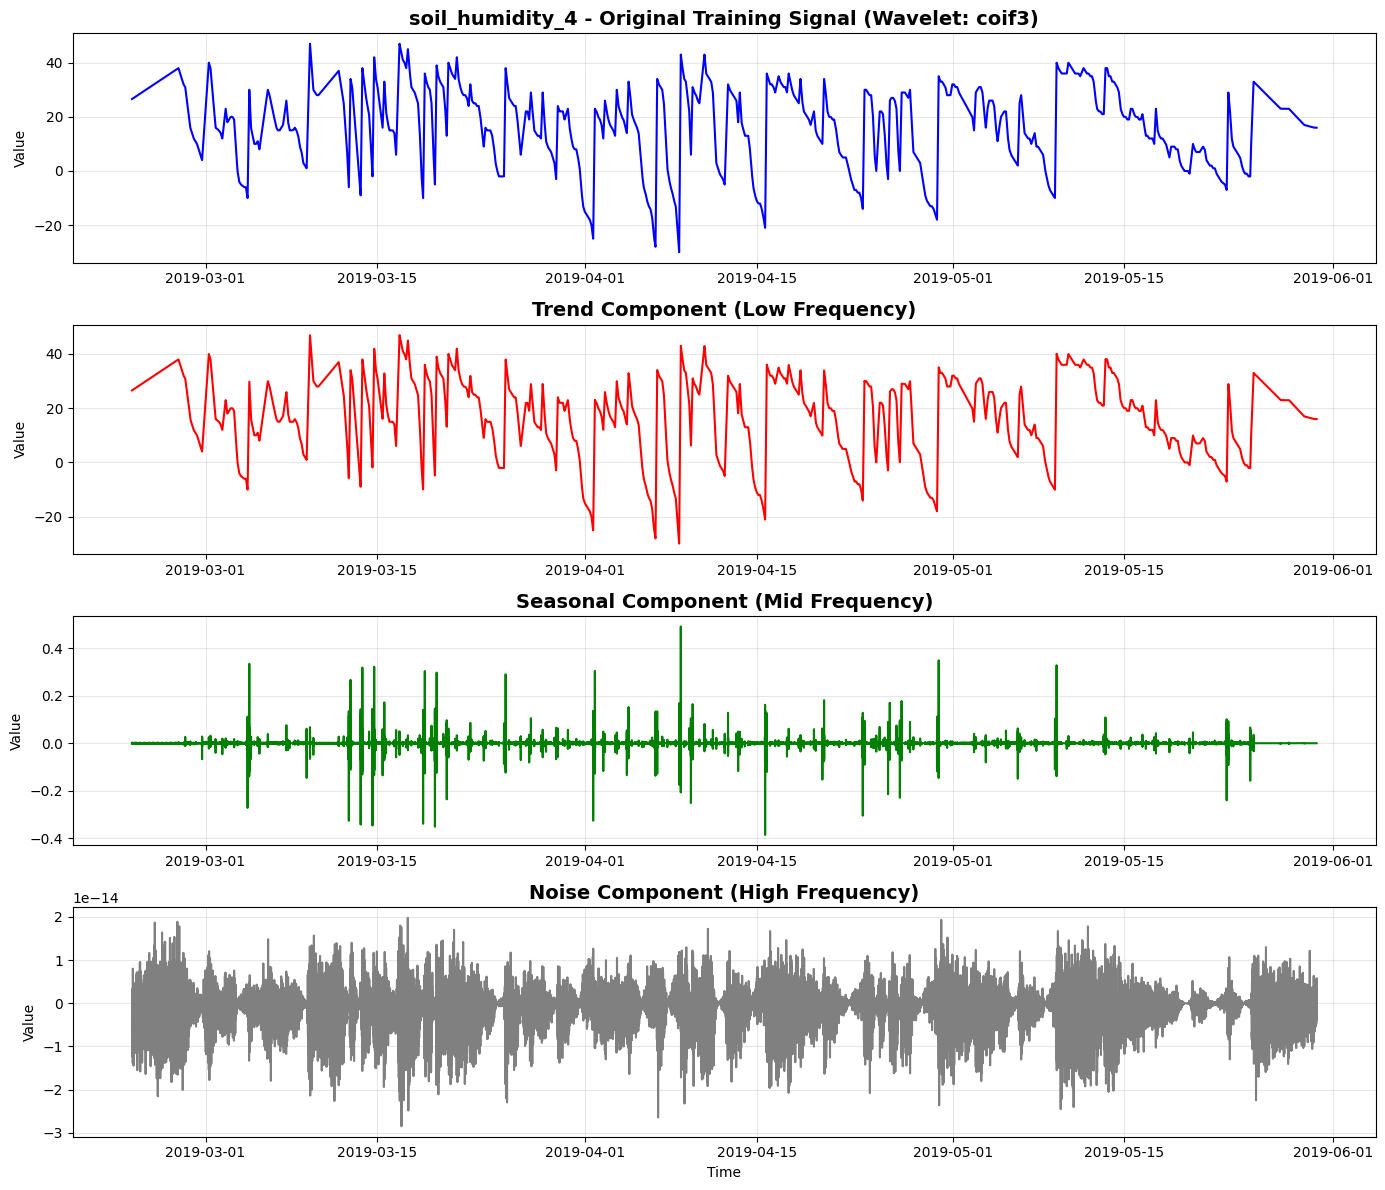

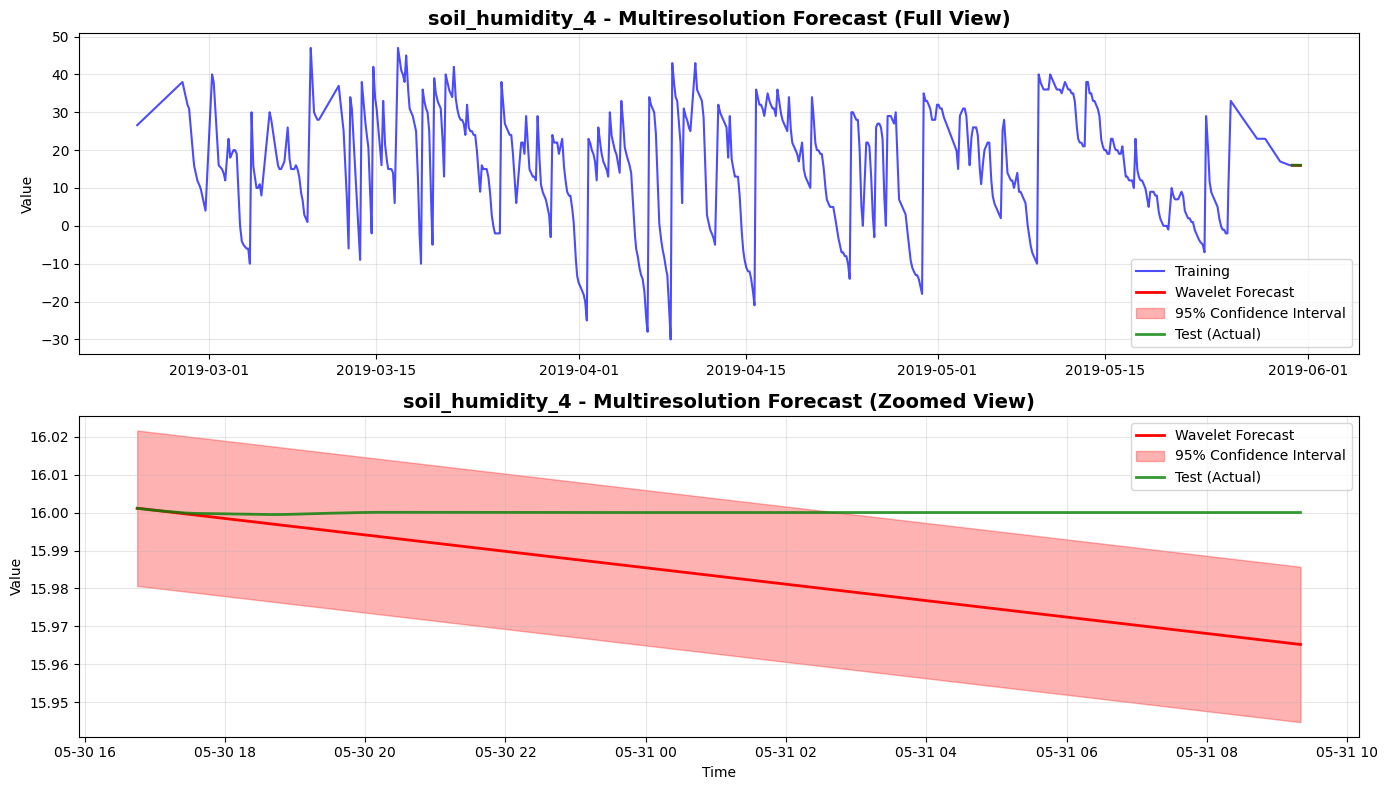

In [29]:
forecaster = WaveletForecaster(denoised_df)
results = forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], 
                              wavelet='auto',  # Auto-select best wavelet
                              levels=None,     # Auto-detect optimal levels
                              forecast_steps=200)

### 3.8.4 Extension 4: Ensemble Methods and Uncertainty Quantification


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error

class EnsembleForecastingSystem:
    def __init__(self, df: pd.DataFrame):
        self.df = df.copy()
        self.df.columns = (
            self.df.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_")
            .str.replace("(", "")
            .str.replace(")", "")
        )
        self.models = {}
        self.weights = {}
    
    def add_model(self, col, name, predictions, weight=1.0):
        """Add a model's predictions to the ensemble for a specific column"""
        if col not in self.models:
            self.models[col] = {}
            self.weights[col] = {}
        
        self.models[col][name] = predictions
        self.weights[col][name] = weight
    
    def weighted_ensemble(self, col):
        """Create weighted ensemble forecast for a specific column"""
        if col not in self.models or len(self.models[col]) == 0:
            return None
        
        total_weight = sum(self.weights[col].values())
        
        # Get the minimum length among all predictions
        min_length = min(len(pred) for pred in self.models[col].values())
        
        ensemble_forecast = np.zeros(min_length)
        
        for name, predictions in self.models[col].items():
            ensemble_forecast += (self.weights[col][name] / total_weight) * predictions[:min_length]
        
        return ensemble_forecast
    
    def uncertainty_quantification(self, col, confidence_level=0.95):
        """Calculate prediction intervals using ensemble spread for a specific column"""
        if col not in self.models or len(self.models[col]) == 0:
            return None, None, None
        
        # Get the minimum length among all predictions
        min_length = min(len(pred) for pred in self.models[col].values())
        
        # Truncate all predictions to minimum length
        predictions_matrix = np.array([pred[:min_length] for pred in self.models[col].values()])
        
        mean_prediction = np.mean(predictions_matrix, axis=0)
        std_prediction = np.std(predictions_matrix, axis=0)
        
        # Calculate confidence intervals
        alpha = 1 - confidence_level
        z_score = stats.norm.ppf(1 - alpha/2)
        
        lower_bound = mean_prediction - z_score * std_prediction
        upper_bound = mean_prediction + z_score * std_prediction
        
        return mean_prediction, lower_bound, upper_bound
    
    def forecast(self, model_results_dict, test_actual_dict=None, confidence_level=0.95, plot=True):
        """
        Create ensemble forecasts from multiple model results
        
        Parameters:
        -----------
        model_results_dict : dict
            Dictionary with model names as keys and their results dicts as values
            Example: {
                'SARIMA': sarima_results,
                'LSTM': lstm_results,
                'Wavelet': wavelet_results
            }
        test_actual_dict : dict, optional
            Dictionary with column names as keys and actual test values as values
        confidence_level : float
            Confidence level for prediction intervals (default 0.95)
        plot : bool
            Whether to generate plots
        """
        # Extract columns from first model result
        first_model = list(model_results_dict.values())[0]
        cols = [col for col in first_model.keys() if first_model[col] is not None]
        
        results = {}
        
        for col in cols:
            print(f"\nCreating ensemble for '{col}'...")
            
            # Add predictions from each model
            for model_name, model_results in model_results_dict.items():
                if col in model_results and model_results[col] is not None:
                    # Get predictions - handle different key names
                    if 'forecast' in model_results[col]:
                        predictions = model_results[col]['forecast']
                    elif 'predictions' in model_results[col]:
                        predictions = model_results[col]['predictions']
                    else:
                        continue
                    
                    # Auto-weight based on model performance (inverse MAPE)
                    if 'mape' in model_results[col] and model_results[col]['mape'] > 0:
                        weight = 1.0 / model_results[col]['mape']
                    else:
                        weight = 1.0
                    
                    self.add_model(col, model_name, predictions, weight=weight)
            
            if col not in self.models or len(self.models[col]) == 0:
                print(f"No models available for '{col}'")
                results[col] = None
                continue
            
            # Create ensemble forecast
            ensemble_forecast = self.weighted_ensemble(col)
            mean_pred, lower_bound, upper_bound = self.uncertainty_quantification(col, confidence_level)
            
            # Calculate metrics if test data is available
            if test_actual_dict and col in test_actual_dict:
                test_actual = test_actual_dict[col]
                compare_len = min(len(test_actual), len(ensemble_forecast))
                
                mse = mean_squared_error(test_actual[:compare_len], ensemble_forecast[:compare_len])
                mae = mean_absolute_error(test_actual[:compare_len], ensemble_forecast[:compare_len])
                mape = np.mean(np.abs((test_actual[:compare_len] - ensemble_forecast[:compare_len]) / 
                                     test_actual[:compare_len])) * 100
                
                results[col] = {
                    "ensemble_forecast": ensemble_forecast,
                    "mean_prediction": mean_pred,
                    "lower_bound": lower_bound,
                    "upper_bound": upper_bound,
                    "test_actual": test_actual,
                    "model_weights": self.weights[col].copy(),
                    "mse": mse,
                    "mae": mae,
                    "mape": mape
                }
            else:
                results[col] = {
                    "ensemble_forecast": ensemble_forecast,
                    "mean_prediction": mean_pred,
                    "lower_bound": lower_bound,
                    "upper_bound": upper_bound,
                    "model_weights": self.weights[col].copy()
                }
            
            print(f"Ensemble created for '{col}' using {len(self.models[col])} models")
            print(f"Model weights: {self.weights[col]}")
        
        # Print metrics table if available
        metrics_cols = [col for col in results.keys() if results[col] is not None and 'mse' in results[col]]
        if metrics_cols:
            metrics_df = pd.DataFrame({
                col: {k: v for k, v in res.items() if k in ['mse', 'mae', 'mape']}
                for col, res in results.items() if col in metrics_cols
            }).T
            
            if 'mape' in metrics_df.columns:
                metrics_df_display = metrics_df.copy()
                metrics_df_display['mape'] = metrics_df_display['mape'].apply(lambda x: f"{x:.2f}%")
                print("\nEnsemble Forecast Metrics Summary:")
                print(metrics_df_display)
        
        # Plot
        if plot and results:
            for col in cols:
                if results[col] is None:
                    continue
                
                ensemble_forecast = results[col]['ensemble_forecast']
                lower_bound = results[col]['lower_bound']
                upper_bound = results[col]['upper_bound']
                
                # Get train_len from first model
                train_len = None
                for model_results in model_results_dict.values():
                    if col in model_results and model_results[col] is not None:
                        if 'train_len' in model_results[col]:
                            train_len = model_results[col]['train_len']
                            break
                        elif 'train_data_len' in model_results[col]:
                            train_len = model_results[col]['train_data_len']
                            break
                
                if train_len is None:
                    train_len = len(self.df) - len(ensemble_forecast)
                
                # Create forecast index
                if isinstance(self.df.index, pd.DatetimeIndex):
                    train_end_time = self.df.index[train_len - 1]
                    freq = self.df.index.freq if self.df.index.freq is not None else pd.infer_freq(self.df.index)
                    if freq is None:
                        freq = '5min'
                    
                    forecast_index = pd.date_range(start=train_end_time, 
                                                  periods=len(ensemble_forecast) + 1, 
                                                  freq=freq)[1:]
                else:
                    forecast_index = pd.RangeIndex(start=self.df.index[train_len - 1] + 1, 
                                                  stop=self.df.index[train_len - 1] + 1 + len(ensemble_forecast))
                
                # Create subplots: full view and zoomed view
                fig, axes = plt.subplots(2, 1, figsize=(14, 8))
                
                # FULL VIEW
                axes[0].plot(self.df.index[:train_len], self.df[col].iloc[:train_len], 
                           label='Training', color='blue', alpha=0.7)
                axes[0].plot(forecast_index, ensemble_forecast, 
                           label='Ensemble Forecast', color='red', linewidth=2)
                axes[0].fill_between(forecast_index, lower_bound, upper_bound, 
                                   alpha=0.3, color='red', label=f'{int(confidence_level*100)}% Confidence Interval')
                
                if 'test_actual' in results[col]:
                    test_actual = results[col]['test_actual']
                    test_index = forecast_index[:len(test_actual)]
                    axes[0].plot(test_index, test_actual, 
                               label='Test (Actual)', color='green', linewidth=2, alpha=0.8)
                
                axes[0].set_title(f'{col} - Ensemble Forecast (Full View)', fontsize=14, fontweight='bold')
                axes[0].legend()
                axes[0].grid(True, alpha=0.3)
                axes[0].set_ylabel('Value')
                
                # ZOOMED VIEW
                axes[1].plot(forecast_index, ensemble_forecast, 
                           label='Ensemble Forecast', color='red', linewidth=2)
                axes[1].fill_between(forecast_index, lower_bound, upper_bound, 
                                   alpha=0.3, color='red', label=f'{int(confidence_level*100)}% Confidence Interval')
                
                if 'test_actual' in results[col]:
                    test_actual = results[col]['test_actual']
                    test_index = forecast_index[:len(test_actual)]
                    axes[1].plot(test_index, test_actual, 
                               label='Test (Actual)', color='green', linewidth=2, alpha=0.8)
                
                axes[1].set_title(f'{col} - Ensemble Forecast (Zoomed View)', fontsize=14, fontweight='bold')
                axes[1].legend()
                axes[1].grid(True, alpha=0.3)
                axes[1].set_xlabel('Time')
                axes[1].set_ylabel('Value')
                
                plt.tight_layout()
                plt.savefig(f"./output/ensemble_forecasting_{col}.png")
                plt.show()
                
                # Plot individual model contributions
                fig, ax = plt.subplots(figsize=(14, 6))
                
                for model_name, predictions in self.models[col].items():
                    ax.plot(forecast_index[:len(predictions)], predictions, 
                           label=f'{model_name} (weight: {self.weights[col][model_name]:.3f})', 
                           alpha=0.6, linewidth=1.5)
                
                ax.plot(forecast_index, ensemble_forecast, 
                       label='Ensemble', color='black', linewidth=3, linestyle='--')
                
                if 'test_actual' in results[col]:
                    test_actual = results[col]['test_actual']
                    test_index = forecast_index[:len(test_actual)]
                    ax.plot(test_index, test_actual, 
                           label='Actual', color='green', linewidth=2)
                
                ax.set_title(f'{col} - Individual Model Contributions', fontsize=14, fontweight='bold')
                ax.legend()
                ax.grid(True, alpha=0.3)
                ax.set_xlabel('Time')
                ax.set_ylabel('Value')
                
                plt.tight_layout()
                plt.savefig(f"./output/24.10_ensemble_model_contributions_{col}.png")
                plt.show()
        
        return results

# Example usage
# # First, run individual forecasters
# sarima_forecaster = SARIMAForecaster(your_dataframe)
# sarima_results = sarima_forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], forecast_steps=200)
# 
# lstm_forecaster = LSTMForecaster(your_dataframe)
# lstm_results = lstm_forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], forecast_steps=200)
# 
# wavelet_forecaster = WaveletForecaster(your_dataframe)
# wavelet_results = wavelet_forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], forecast_steps=200)
# 
# # Create ensemble
# ensemble = EnsembleForecastingSystem(your_dataframe)
# 
# # Combine all models
# test_actual = {
#     'soil_humidity_2': sarima_results['soil_humidity_2']['test_actual'],
#     'soil_humidity_4': sarima_results['soil_humidity_4']['test_actual']
# }
# 
# # Assuming denoised_df has a test split you defined separately
#test_actual = {
#    'soil_humidity_2': denoised_df['soil_humidity_2'].iloc[-test_size:].values,
#    'soil_humidity_4': denoised_df['soil_humidity_4'].iloc[-test_size:].values
#}
#
# ensemble_results = ensemble.forecast(
#     model_results_dict={
#         'SARIMA': sarima_results,
#         'LSTM': lstm_results,
#         'Wavelet': wavelet_results
#     },
#     test_actual_dict=test_actual,
#     confidence_level=0.95
# )


Forecast Metrics Summary:
                                                        best_order  \
soil_humidity_2  {'trend': 0, 'exog': 0, 'ar': 1, 'ma': 1, 'sea...   
soil_humidity_4  {'trend': 0, 'exog': 0, 'ar': 1, 'ma': 1, 'sea...   

                           aic stationary       mse       mae   mape  
soil_humidity_2 -272095.191268       True  1.424289   1.02086  3.93%  
soil_humidity_4 -259540.203602       True  0.000231  0.013938  0.09%  


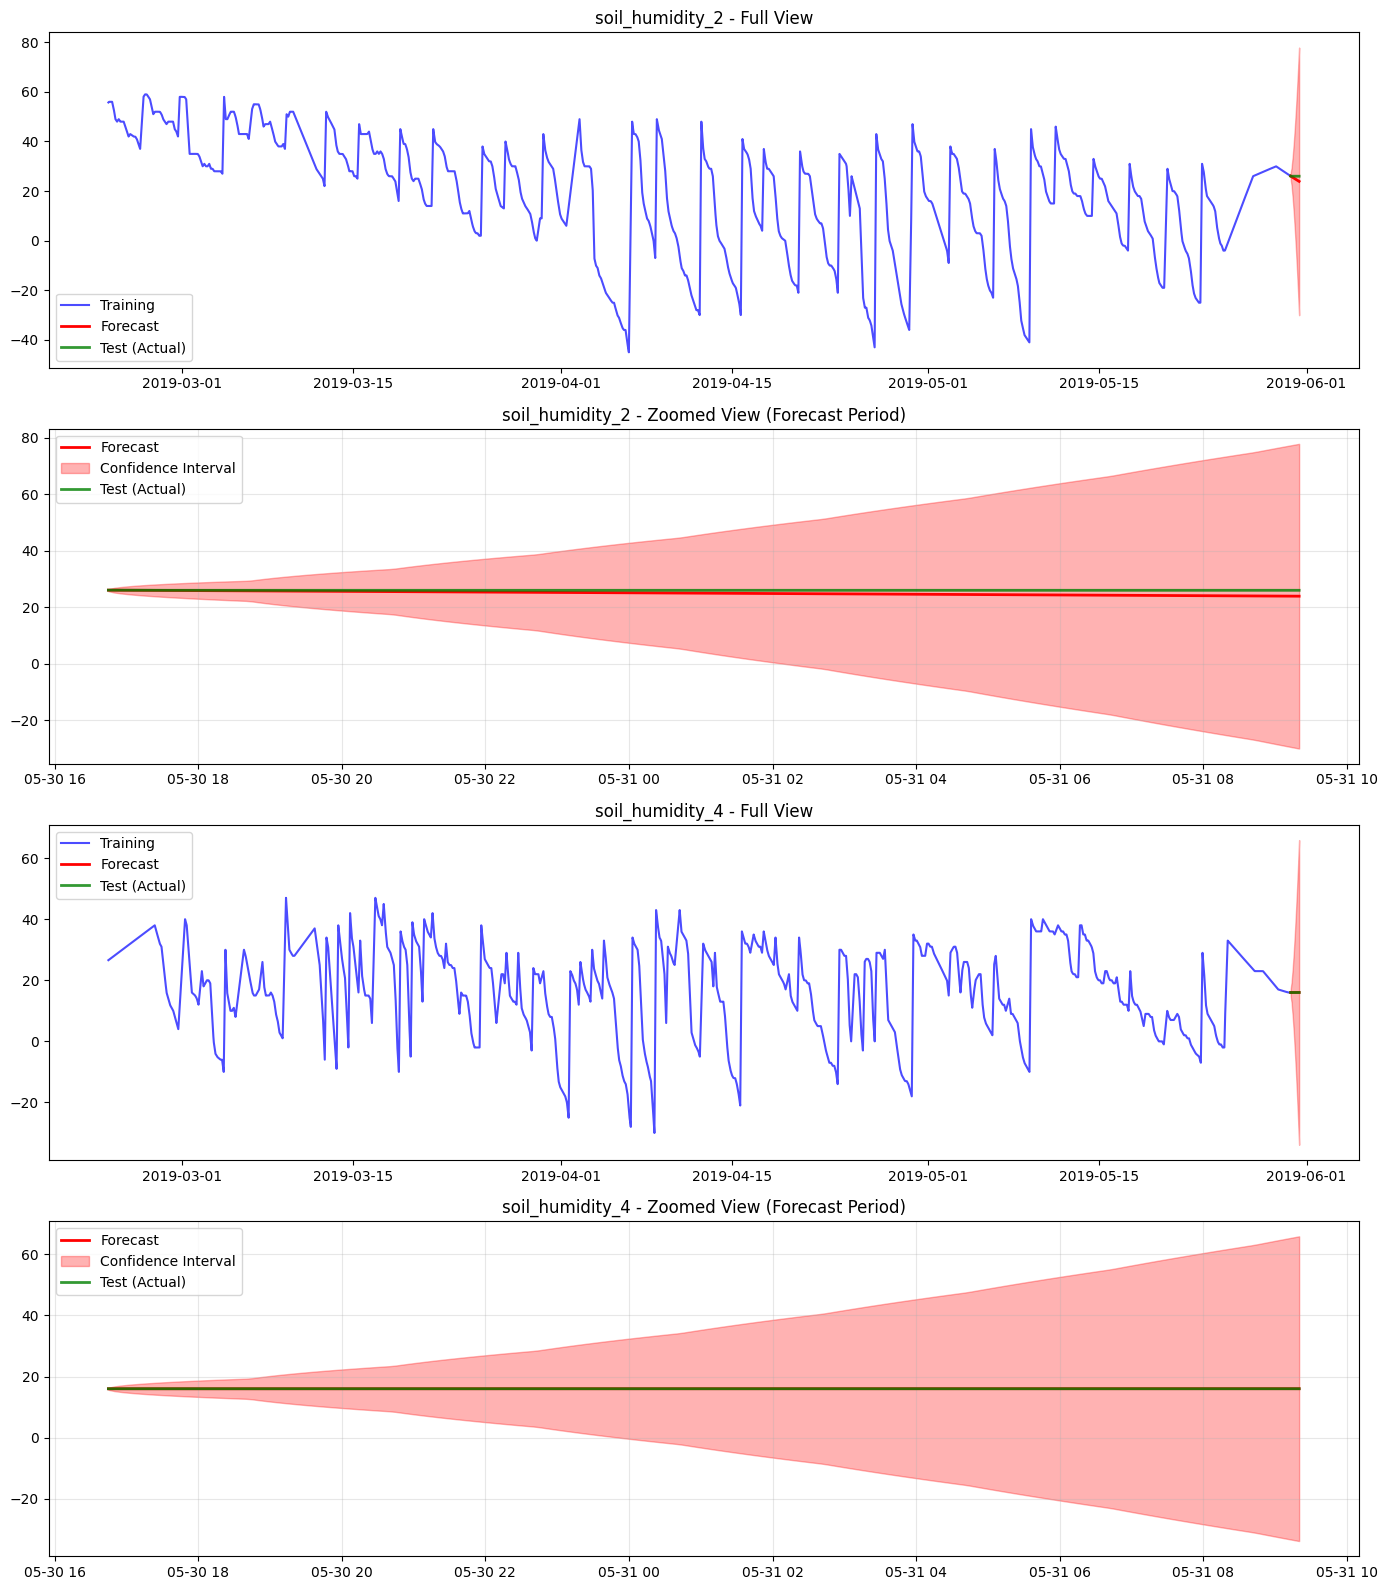


Training LSTM model for 'soil_humidity_2'...
Training completed for 'soil_humidity_2'

Training LSTM model for 'soil_humidity_4'...
Training completed for 'soil_humidity_4'

LSTM Forecast Metrics Summary:
                      mse       mae   mape
soil_humidity_2  0.141156  0.375700  1.44%
soil_humidity_4  0.012681  0.112612  0.70%


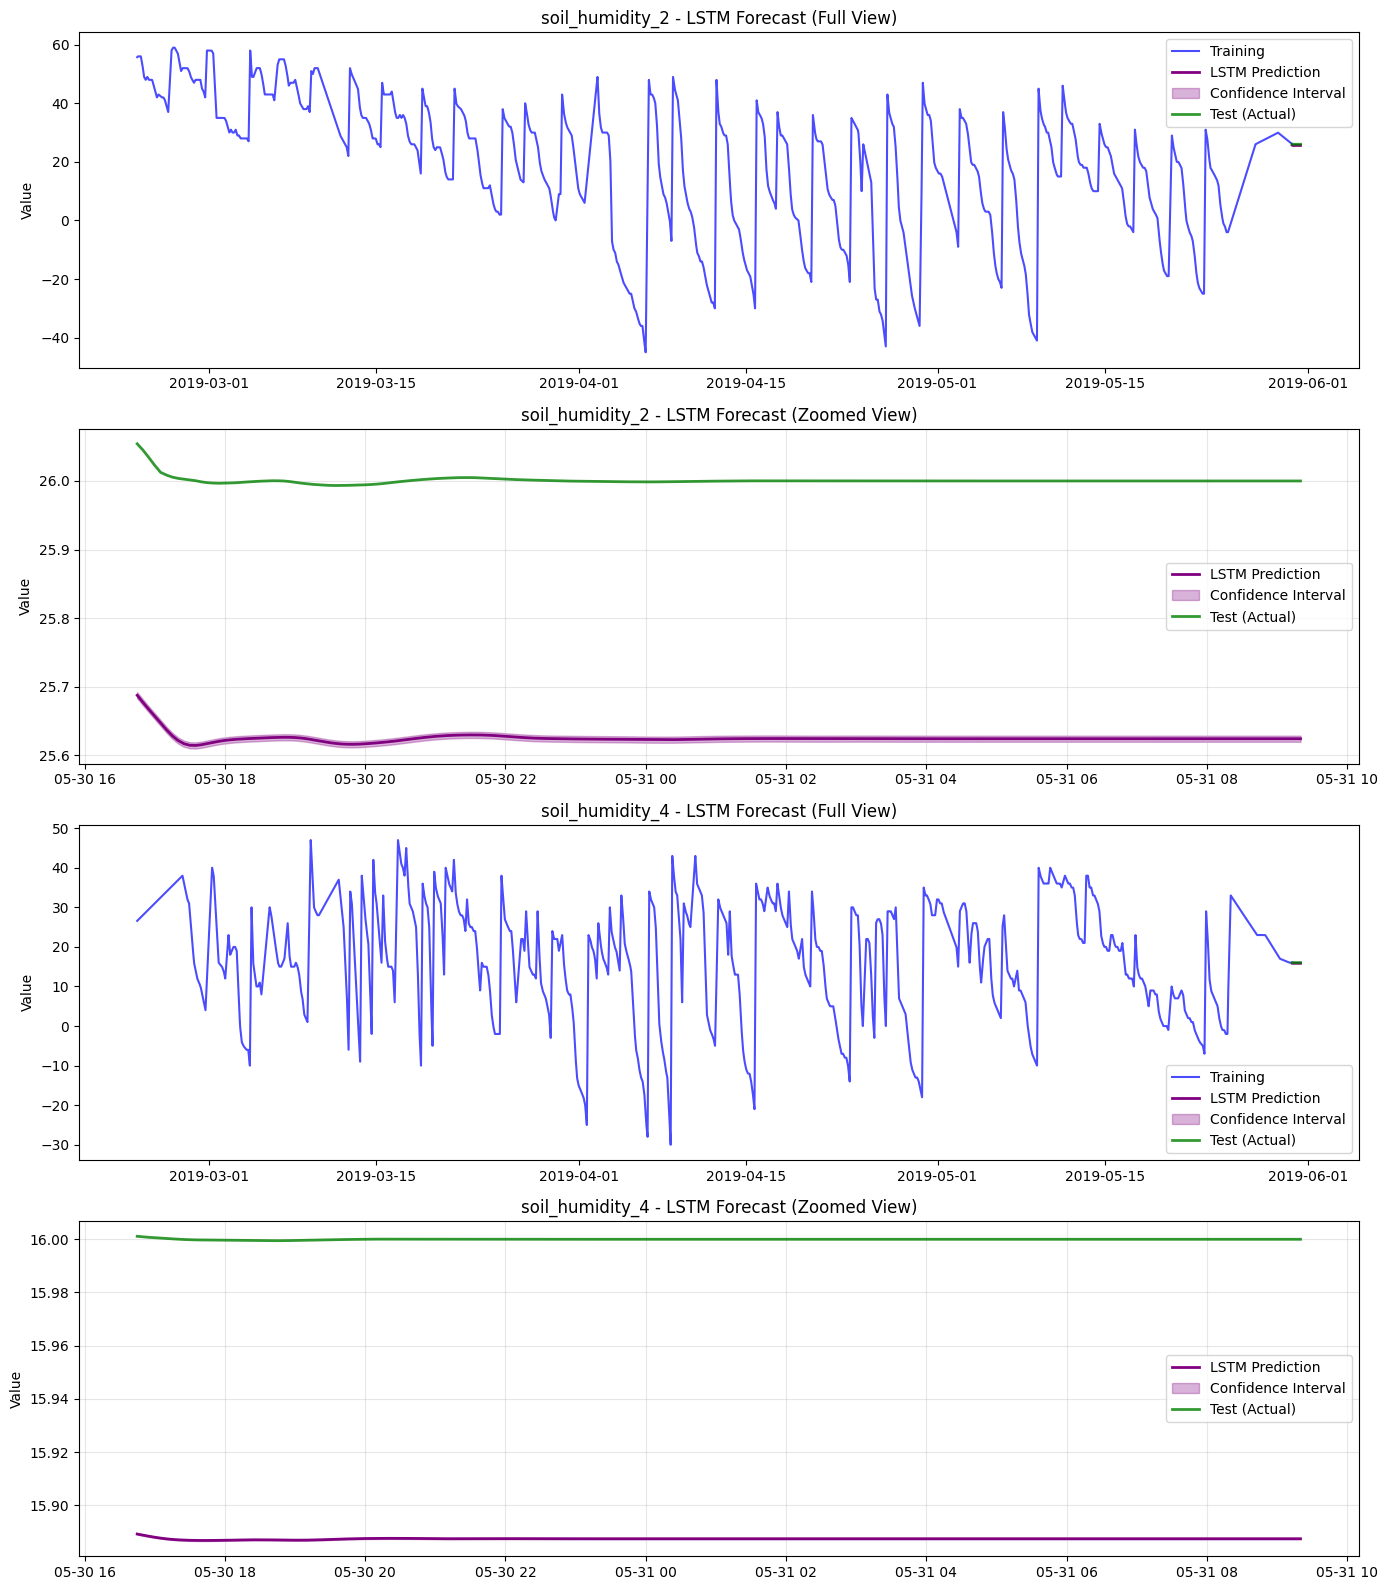


Processing 'soil_humidity_2' with enhanced wavelet decomposition...
  Selected wavelet: db8
  MSE: 1.1428, MAE: 0.9112, MAPE: 3.50%

Processing 'soil_humidity_4' with enhanced wavelet decomposition...
  Selected wavelet: coif3
  MSE: 0.0004, MAE: 0.0168, MAPE: 0.10%

Enhanced Wavelet Forecast Metrics Summary:
                      mse       mae   mape
soil_humidity_2  1.142784  0.911214  3.50%
soil_humidity_4  0.000390  0.016781  0.10%


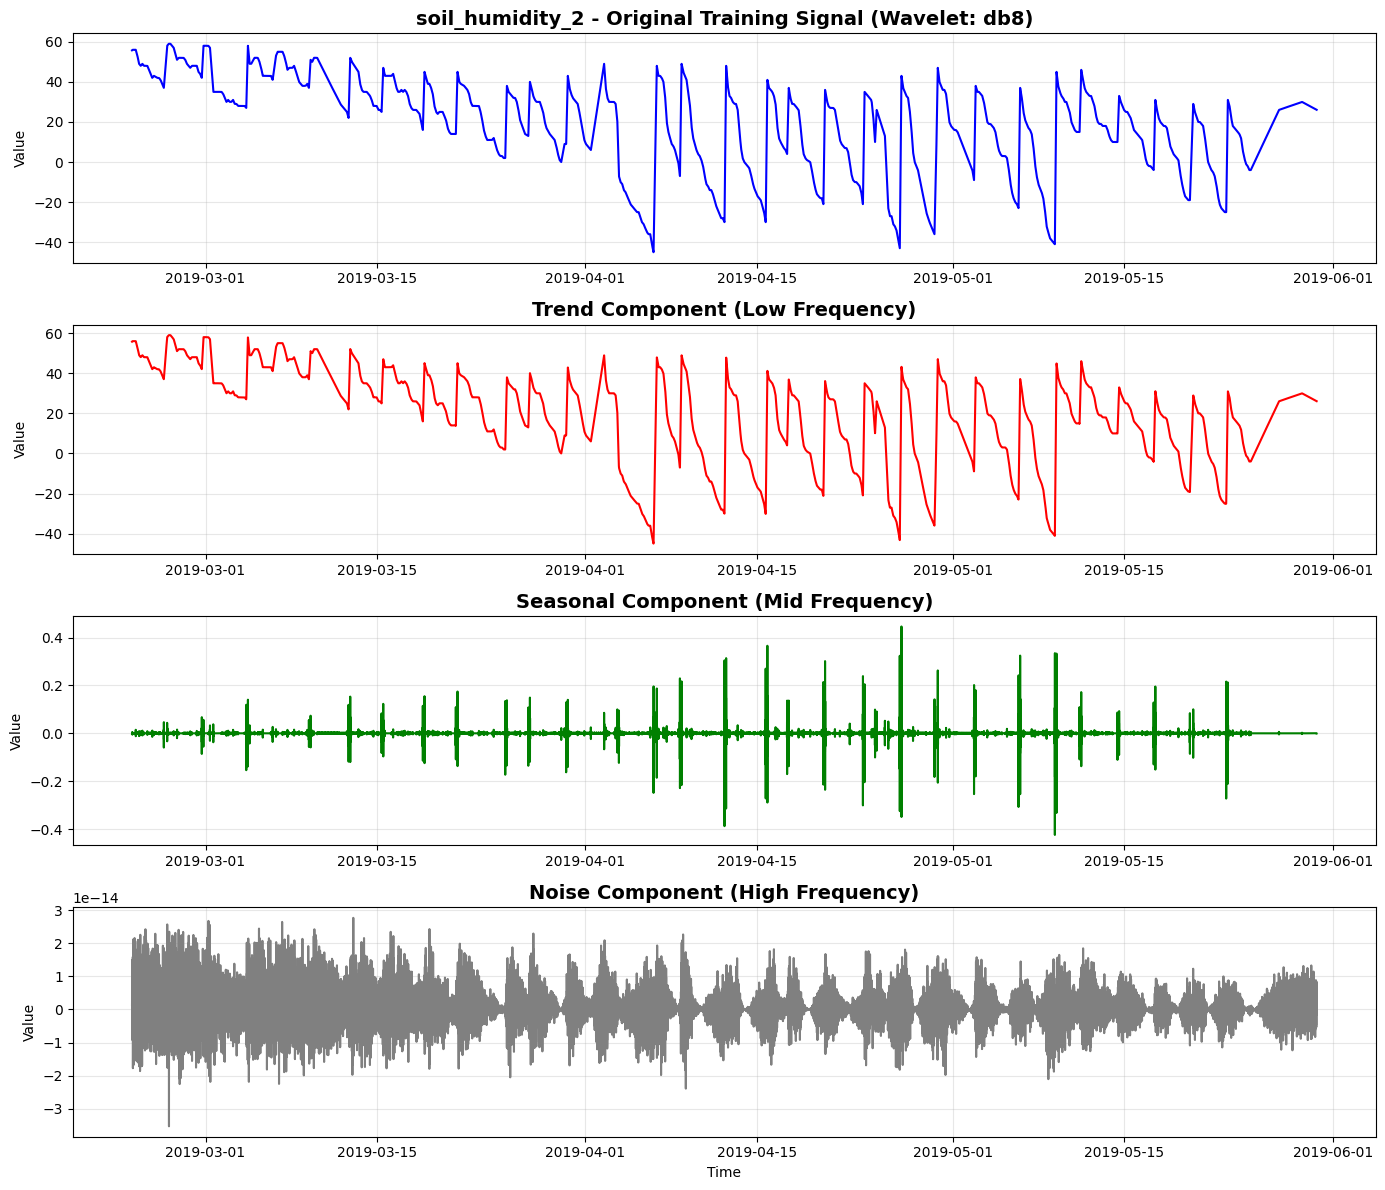

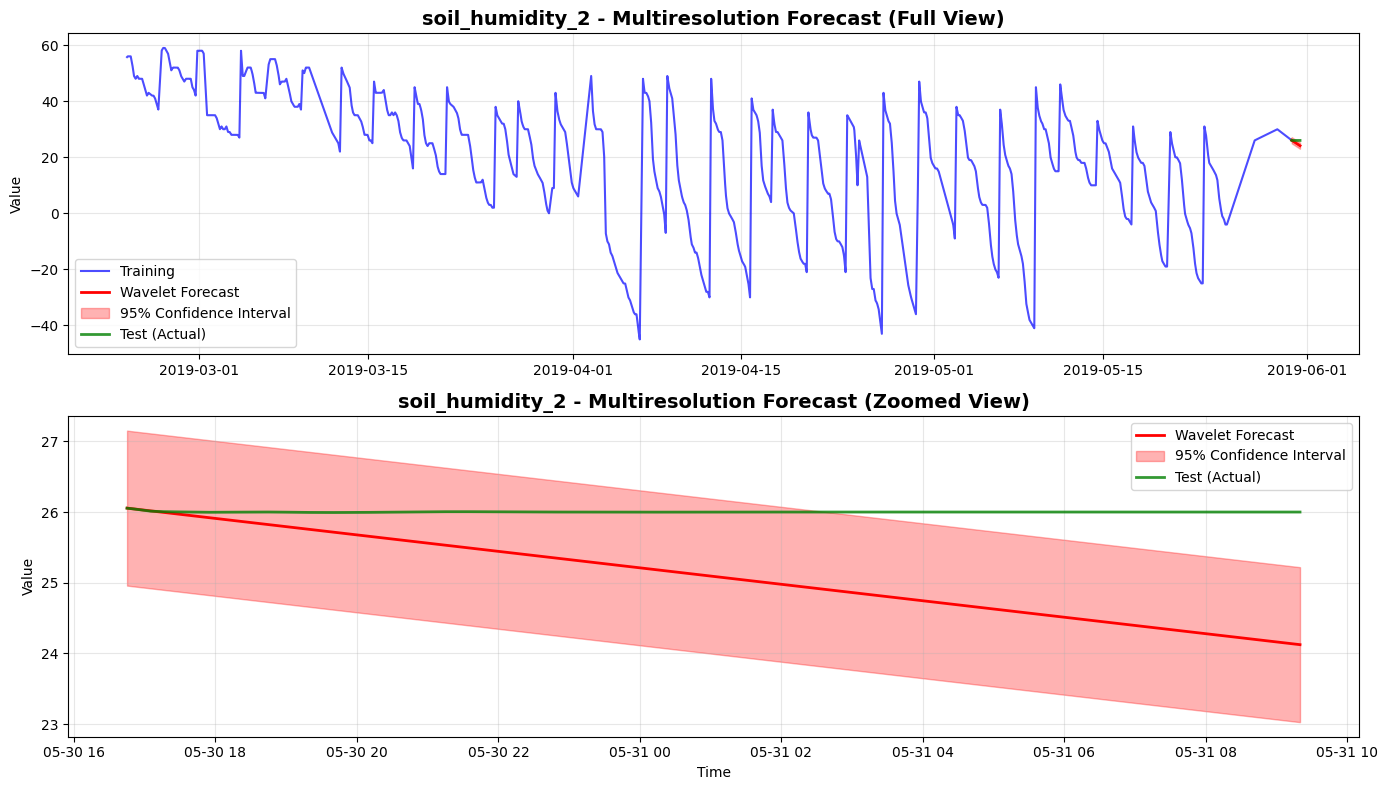

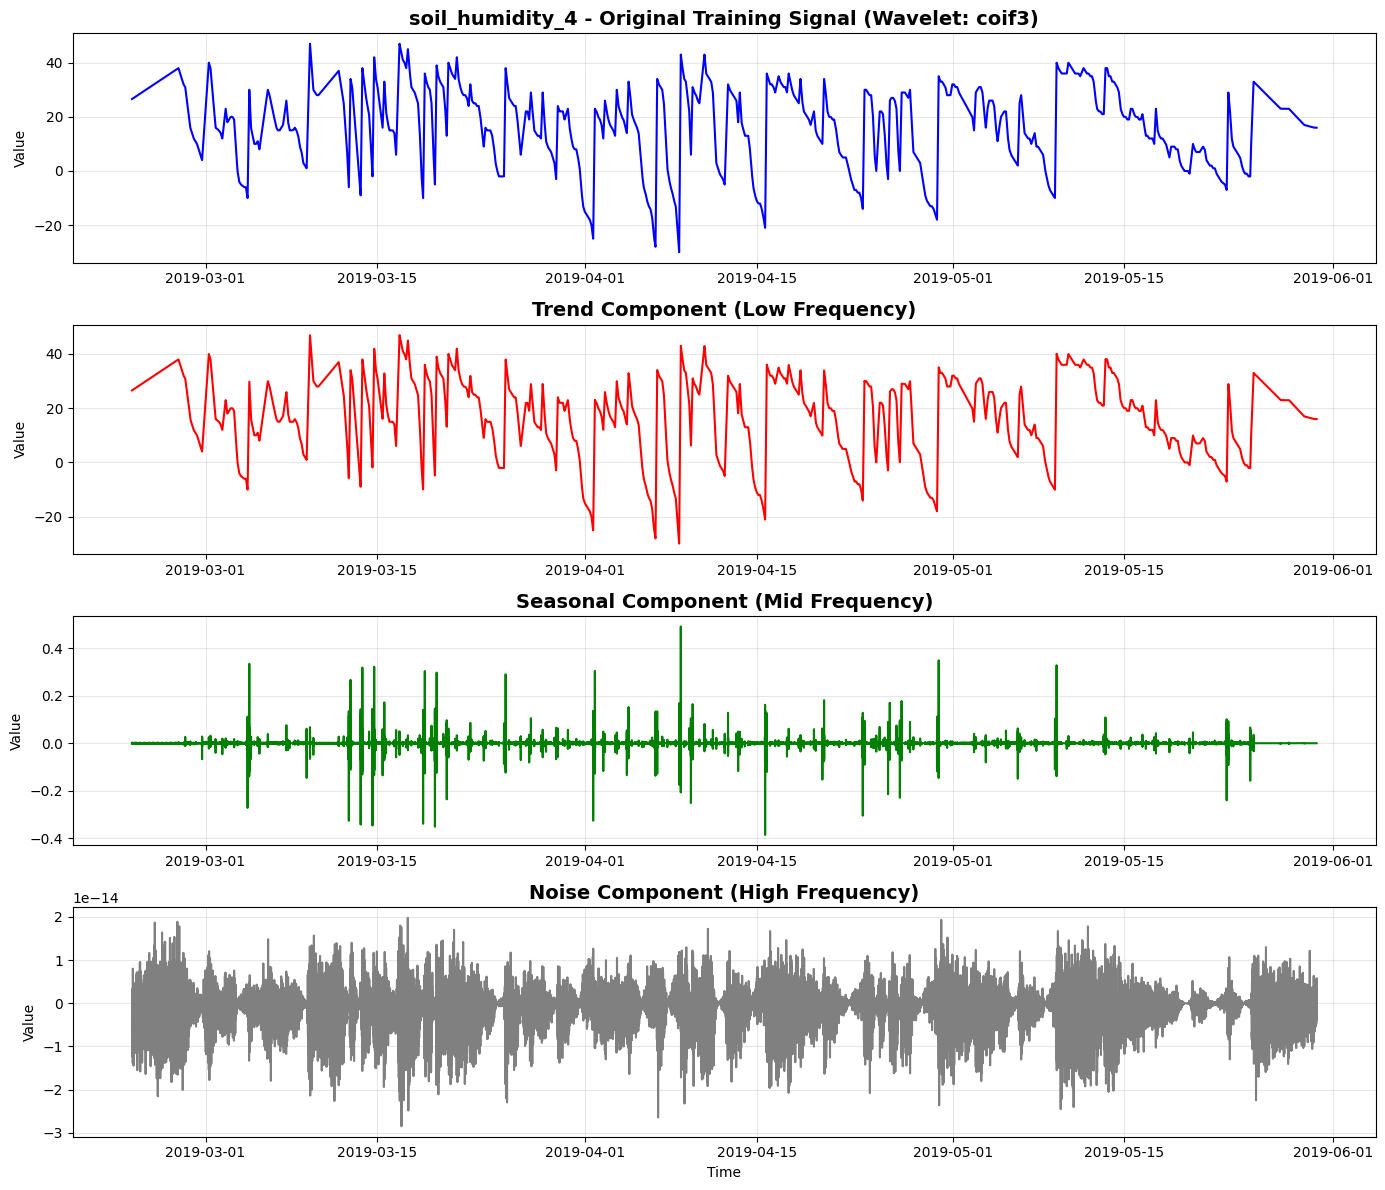

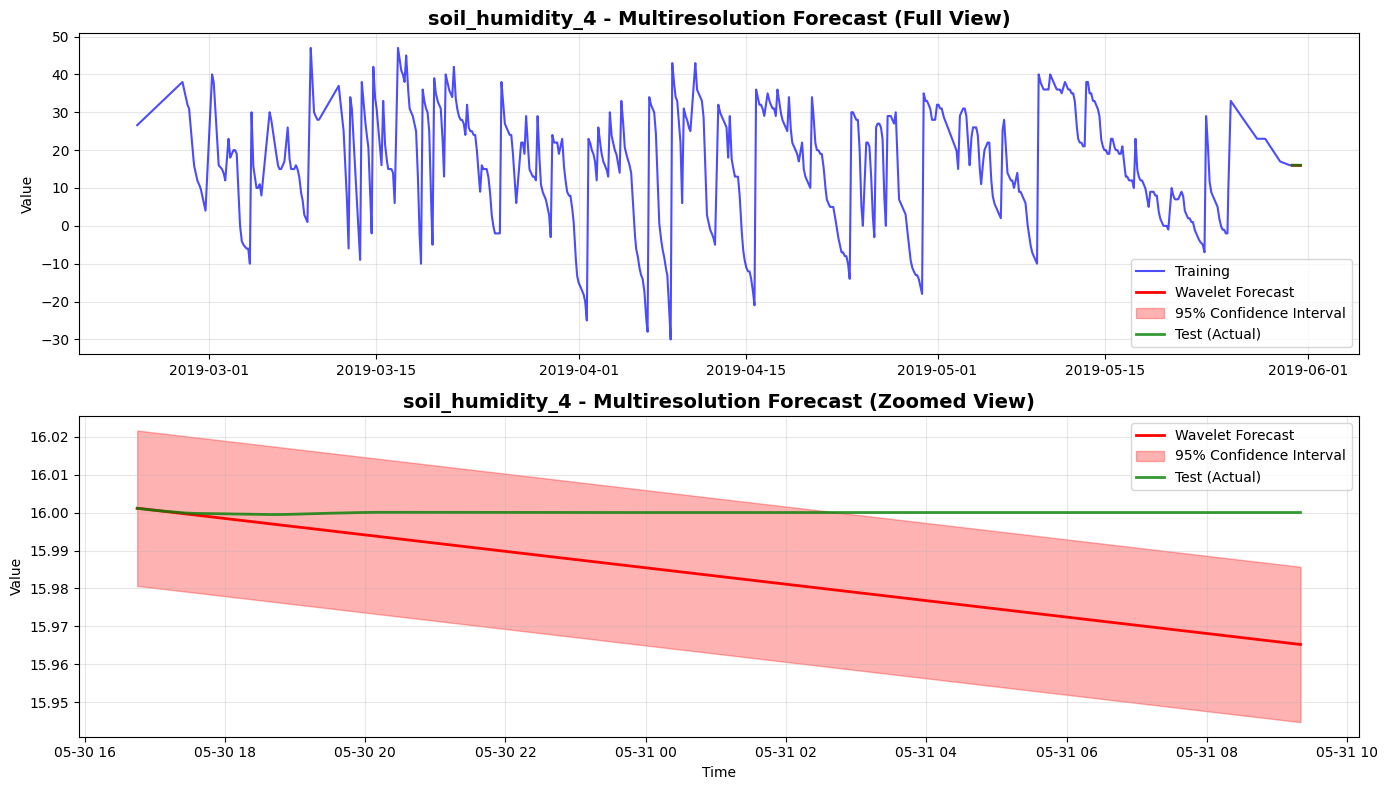


Creating ensemble for 'soil_humidity_2'...
Ensemble created for 'soil_humidity_2' using 3 models
Model weights: {'SARIMA': 0.25468701600229904, 'LSTM': 0.6920577555222136, 'Wavelet': 0.28533342482280116}

Creating ensemble for 'soil_humidity_4'...
Ensemble created for 'soil_humidity_4' using 3 models
Model weights: {'SARIMA': 11.47969029155856, 'LSTM': 1.4208045932721662, 'Wavelet': 9.534458239665582}

Ensemble Forecast Metrics Summary:
                      mse       mae   mape
soil_humidity_2  0.467002  0.633056  2.43%
soil_humidity_4  0.000053  0.007131  0.04%


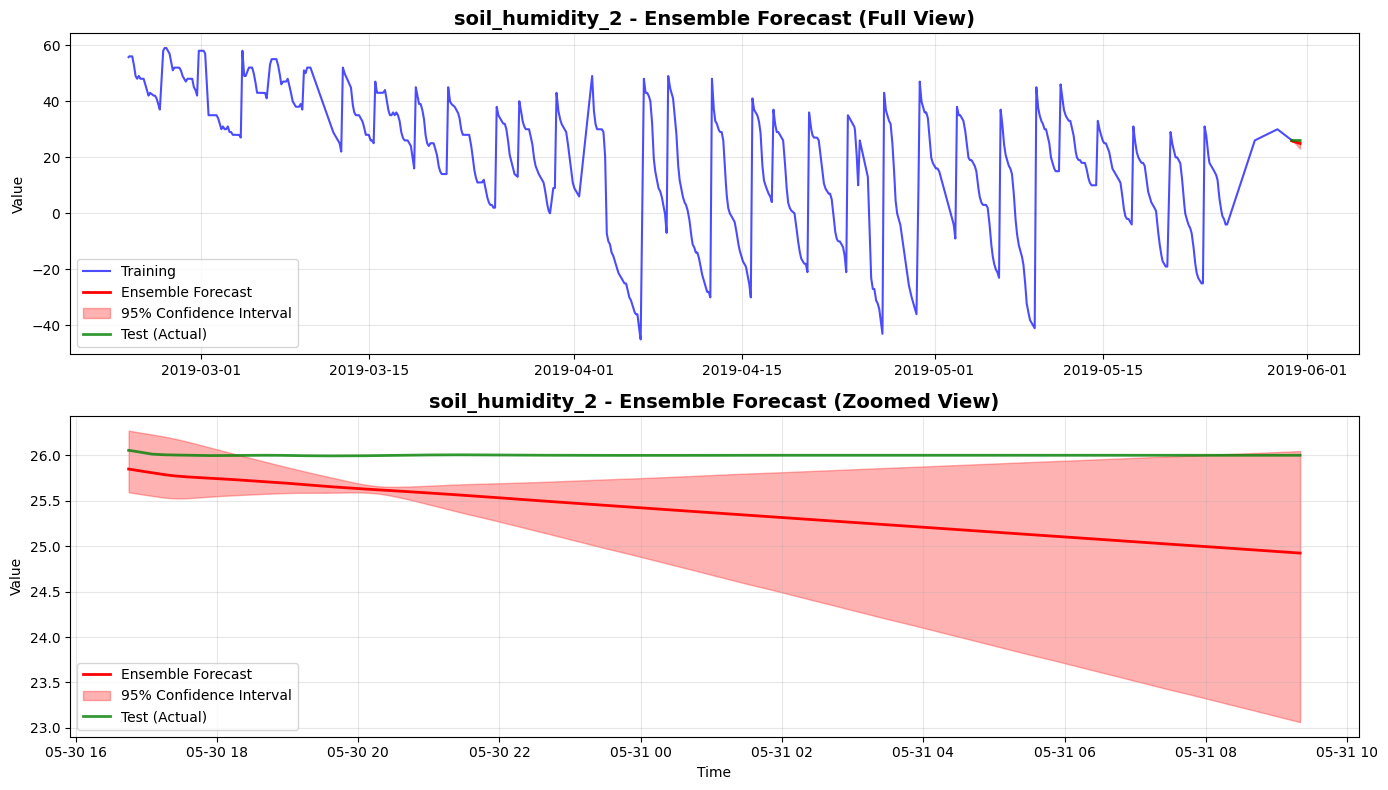

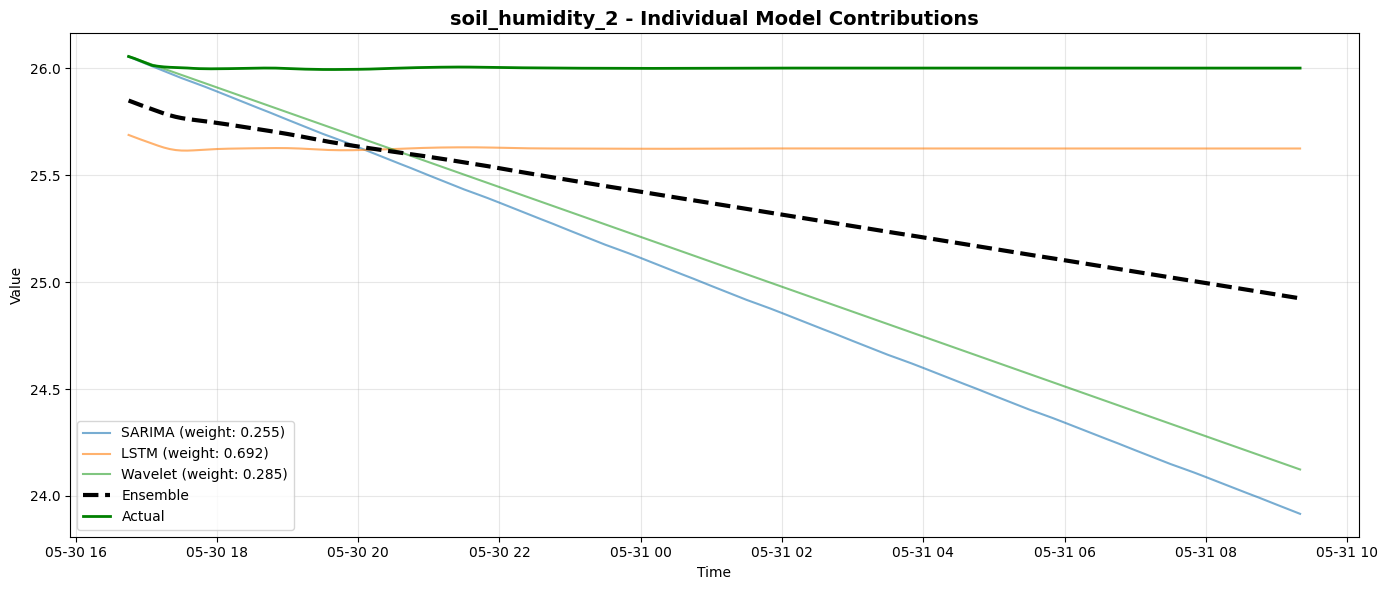

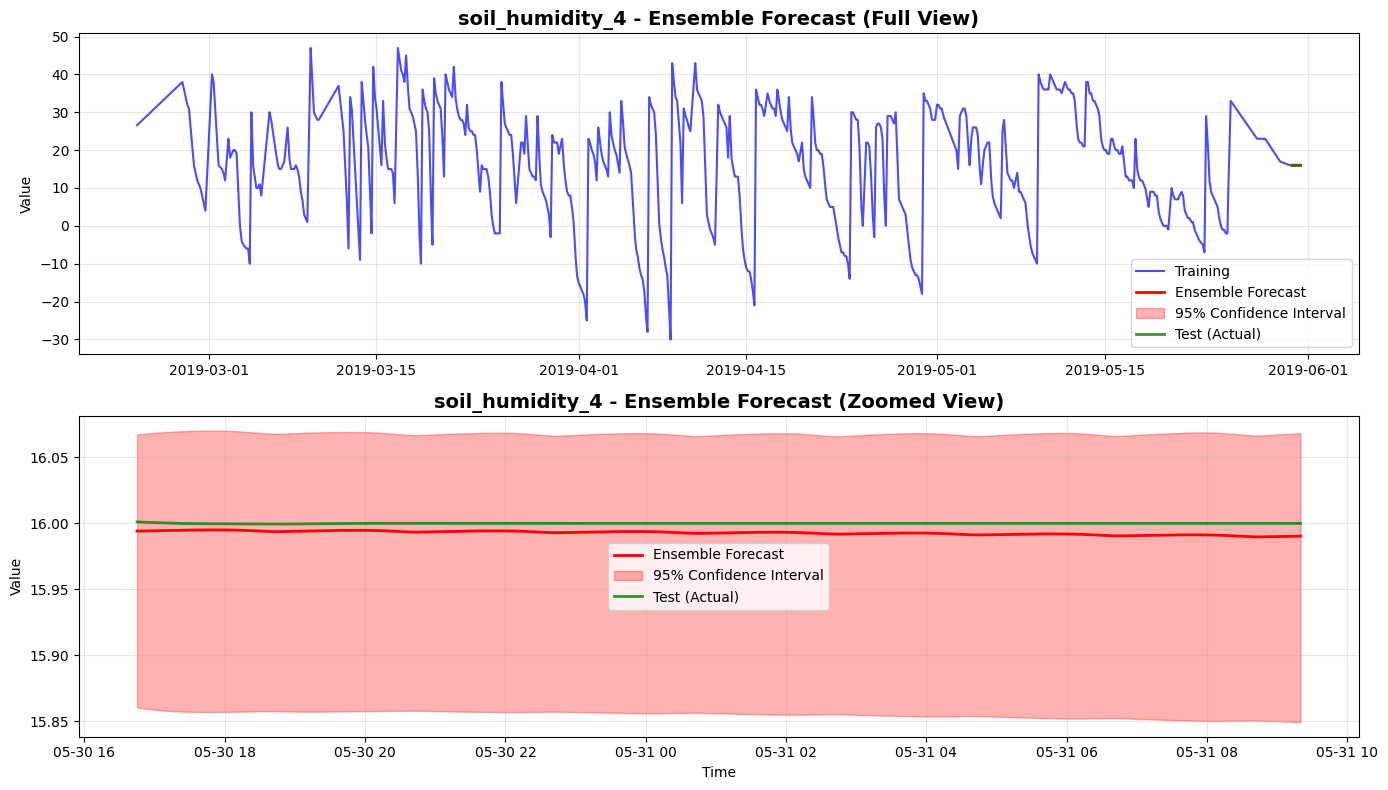

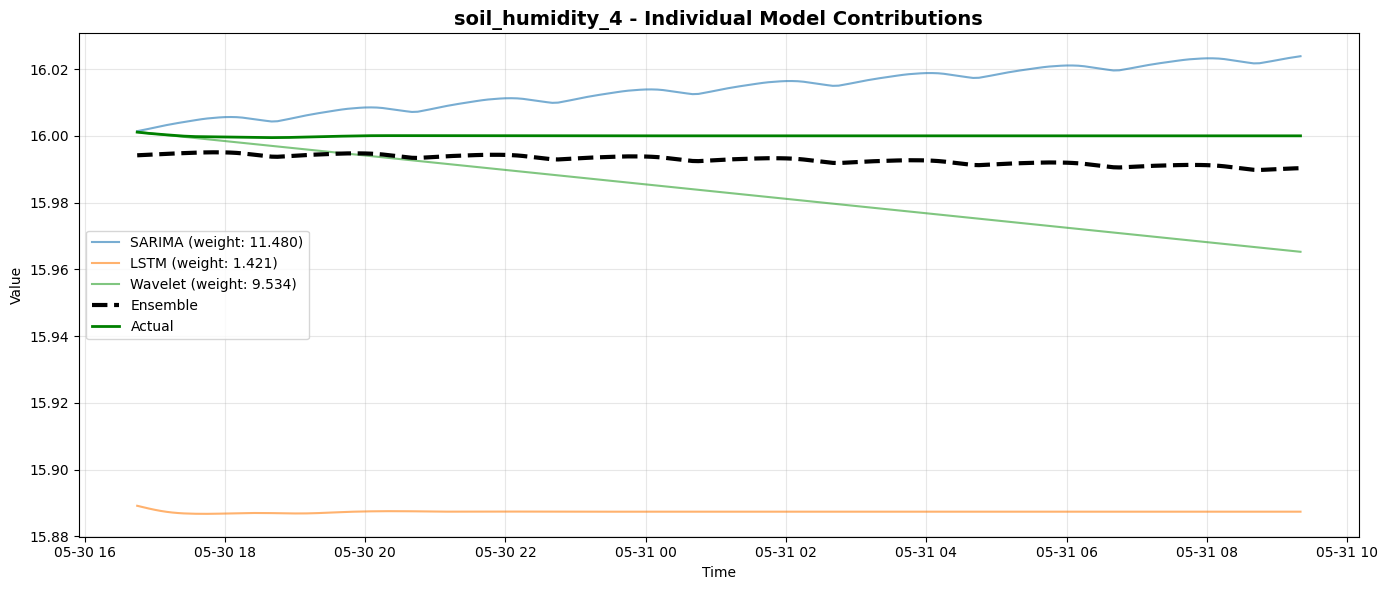

In [ ]:
# Example usage
# First, run individual forecasters
sarima_forecaster = SARIMAForecaster(denoised_df)
sarima_results = sarima_forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], forecast_steps=200)

lstm_forecaster = LSTMForecaster(denoised_df)
lstm_results = lstm_forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], forecast_steps=200)

wavelet_forecaster = WaveletForecaster(denoised_df)
wavelet_results = wavelet_forecaster.forecast(cols=['soil_humidity_2', 'soil_humidity_4'], forecast_steps=200)

# Create ensemble
ensemble = EnsembleForecastingSystem(denoised_df)

# Combine all models
test_actual = {
    'soil_humidity_2': sarima_results['soil_humidity_2']['test_actual'],
    'soil_humidity_4': sarima_results['soil_humidity_4']['test_actual']
}

ensemble_results = ensemble.forecast(
    model_results_dict={
         'SARIMA': sarima_results,
         'LSTM': lstm_results,
         'Wavelet': wavelet_results
     },
     test_actual_dict=test_actual,
     confidence_level=0.95
 )

### 3.8.5 Extension 5: Real-time Adaptive Forecasting

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error, mean_absolute_error

class AdaptiveForecaster:
    def __init__(self, df: pd.DataFrame, window_size=168, update_frequency=24):
        """
        Initialize adaptive forecaster for real-time predictions
        
        Parameters:
        -----------
        df : pd.DataFrame
            Input dataframe with time series data
        window_size : int
            Size of rolling window for training (default: 168 = 1 week of hourly data)
        update_frequency : int
            How often to retrain the model (default: 24 = daily)
        """
        self.df = df.copy()
        self.df.columns = (
            self.df.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_")
            .str.replace("(", "")
            .str.replace(")", "")
        )
        self.window_size = window_size
        self.update_frequency = update_frequency
    
    def wavelet_denoise(self, signal, wavelet='db4', level=3):
        """Denoise signal using wavelet transform"""
        try:
            coeffs = pywt.wavedec(signal, wavelet, level=level)
            threshold = np.std(coeffs[-1]) * np.sqrt(2 * np.log(len(signal)))
            coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]
            denoised = pywt.waverec(coeffs_thresh, wavelet)
            return denoised[:len(signal)]
        except:
            return signal
    
    def train_model(self, data):
        """Train forecasting model on given data"""
        if len(data) < 48:
            return None
        
        # Denoise data
        denoised_data = self.wavelet_denoise(data)
        
        # Try multiple models and select best
        best_model = None
        best_aic = np.inf
        
        # Try ARIMA models
        arima_orders = [(1, 0, 1), (2, 1, 2), (1, 1, 1), (2, 0, 1)]
        for order in arima_orders:
            try:
                model = ARIMA(denoised_data, order=order).fit()
                if model.aic < best_aic:
                    best_aic = model.aic
                    best_model = ('arima', model, order)
            except:
                continue
        
        # Try Exponential Smoothing as fallback
        if best_model is None:
            try:
                model = ExponentialSmoothing(denoised_data, seasonal=None, trend='add').fit()
                best_model = ('exp_smooth', model, None)
            except:
                pass
        
        return best_model
    
    def forecast_with_model(self, model_tuple, steps=1):
        """Generate forecast using trained model"""
        if model_tuple is None:
            return None
        
        model_type, model, order = model_tuple
        
        try:
            if model_type == 'arima':
                forecast = model.forecast(steps=steps)
            elif model_type == 'exp_smooth':
                forecast = model.forecast(steps=steps)
            else:
                return None
            return forecast
        except:
            return None
    
    def simulate_realtime(self, cols=None, start_index=100, forecast_horizon=1, plot=True):
        """
        Simulate real-time adaptive forecasting
        
        Parameters:
        -----------
        cols : list or str
            Columns to forecast
        start_index : int
            Index to start forecasting (need some initial data)
        forecast_horizon : int
            Number of steps ahead to forecast
        plot : bool
            Whether to generate plots
        """
        if cols is None:
            cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        elif isinstance(cols, str):
            cols = [cols]
        
        results = {}
        
        for col in cols:
            if col not in self.df.columns:
                print(f"Column '{col}' not found in DataFrame.")
                results[col] = None
                continue
            
            series = self.df[col].dropna().astype(float).to_numpy()
            if len(series) < start_index + 50:
                print(f"Column '{col}' has insufficient data for adaptive forecasting.")
                results[col] = None
                continue
            
            print(f"\nSimulating real-time forecasting for '{col}'...")
            
            # Initialize buffers
            data_buffer = []
            current_model = None
            update_counter = 0
            
            # Storage for results
            timestamps = []
            actual_values = []
            predicted_values = []
            errors = []
            model_updates = []
            
            # Simulate streaming data
            for i in range(start_index, len(series) - forecast_horizon):
                # Add new observation to buffer
                data_buffer.append(series[i])
                
                # Maintain rolling window
                if len(data_buffer) > self.window_size:
                    data_buffer.pop(0)
                
                # Update model periodically
                update_counter += 1
                if update_counter >= self.update_frequency or current_model is None:
                    if len(data_buffer) >= 48:
                        current_model = self.train_model(np.array(data_buffer))
                        if current_model is not None:
                            model_type, _, order = current_model
                            model_updates.append(i)
                            print(f"  Model updated at index {i}: {model_type}" + 
                                  (f" {order}" if order else ""))
                        update_counter = 0
                
                # Generate forecast
                if current_model is not None:
                    forecast = self.forecast_with_model(current_model, steps=forecast_horizon)
                    if forecast is not None:
                        predicted = forecast[forecast_horizon - 1] if len(forecast) >= forecast_horizon else forecast[-1]
                    else:
                        # Fallback to moving average
                        predicted = np.mean(data_buffer[-24:]) if len(data_buffer) >= 24 else np.mean(data_buffer)
                else:
                    # Fallback to moving average
                    predicted = np.mean(data_buffer[-24:]) if len(data_buffer) >= 24 else np.mean(data_buffer)
                
                actual = series[i + forecast_horizon]
                error = abs(actual - predicted)
                
                timestamps.append(i)
                actual_values.append(actual)
                predicted_values.append(predicted)
                errors.append(error)
            
            # Calculate performance metrics
            mae = np.mean(errors)
            rmse = np.sqrt(np.mean([e**2 for e in errors]))
            mape = np.mean([abs(a - p) / abs(a) * 100 for a, p in zip(actual_values, predicted_values) if a != 0])
            
            results[col] = {
                'timestamps': timestamps,
                'actual': actual_values,
                'predicted': predicted_values,
                'errors': errors,
                'model_updates': model_updates,
                'mae': mae,
                'rmse': rmse,
                'mape': mape,
                'forecast_horizon': forecast_horizon
            }
            
            print(f"Completed simulation for '{col}'")
            print(f"  Total forecasts: {len(timestamps)}")
            print(f"  Model updates: {len(model_updates)}")
        
        # Print metrics table
        metrics_df = pd.DataFrame({
            col: {k: v for k, v in res.items() if k in ['mae', 'rmse', 'mape', 'forecast_horizon']}
            for col, res in results.items() if res is not None
        }).T
        
        if 'mape' in metrics_df.columns:
            metrics_df_display = metrics_df.copy()
            metrics_df_display['mape'] = metrics_df_display['mape'].apply(lambda x: f"{x:.2f}%")
            print("\nAdaptive Forecasting Performance Summary:")
            print(metrics_df_display)
        
        # Plot
        if plot:
            for col in cols:
                if results[col] is None:
                    continue
                
                timestamps = results[col]['timestamps']
                actual = results[col]['actual']
                predicted = results[col]['predicted']
                errors = results[col]['errors']
                model_updates = results[col]['model_updates']
                
                # Create time index for plotting
                if isinstance(self.df.index, pd.DatetimeIndex):
                    time_index = [self.df.index[t] for t in timestamps]
                else:
                    time_index = timestamps
                
                # Create three subplots: full view, zoomed view, and error plot
                fig, axes = plt.subplots(3, 1, figsize=(14, 12))
                
                # FULL VIEW
                axes[0].plot(time_index, actual, label='Actual', color='blue', alpha=0.7, linewidth=1.5)
                axes[0].plot(time_index, predicted, label='Adaptive Forecast', 
                           color='red', alpha=0.8, linewidth=1.5)
                
                # Mark model updates
                for update_idx in model_updates:
                    if update_idx in timestamps:
                        idx_pos = timestamps.index(update_idx)
                        axes[0].axvline(x=time_index[idx_pos], color='green', 
                                      alpha=0.3, linestyle='--', linewidth=1)
                
                axes[0].set_title(f'{col} - Real-time Adaptive Forecasting (Full View)', 
                                fontsize=14, fontweight='bold')
                axes[0].legend()
                axes[0].grid(True, alpha=0.3)
                axes[0].set_ylabel('Value')
                
                # ZOOMED VIEW (last 200 points)
                zoom_start = max(0, len(time_index) - 200)
                axes[1].plot(time_index[zoom_start:], actual[zoom_start:], 
                           label='Actual', color='blue', alpha=0.7, linewidth=2)
                axes[1].plot(time_index[zoom_start:], predicted[zoom_start:], 
                           label='Adaptive Forecast', color='red', alpha=0.8, linewidth=2)
                
                # Mark model updates in zoomed view
                for update_idx in model_updates:
                    if update_idx in timestamps[zoom_start:]:
                        idx_pos = timestamps.index(update_idx)
                        if idx_pos >= zoom_start:
                            axes[1].axvline(x=time_index[idx_pos], color='green', 
                                          alpha=0.3, linestyle='--', linewidth=1)
                
                axes[1].set_title(f'{col} - Adaptive Forecasting (Zoomed View - Last 200 Points)', 
                                fontsize=14, fontweight='bold')
                axes[1].legend()
                axes[1].grid(True, alpha=0.3)
                axes[1].set_ylabel('Value')
                
                # ERROR PLOT
                axes[2].plot(time_index, errors, color='orange', alpha=0.7, linewidth=1)
                axes[2].axhline(y=np.mean(errors), color='red', linestyle='--', 
                              label=f'Mean Error: {np.mean(errors):.2f}')
                
                # Mark model updates
                for update_idx in model_updates:
                    if update_idx in timestamps:
                        idx_pos = timestamps.index(update_idx)
                        axes[2].axvline(x=time_index[idx_pos], color='green', 
                                      alpha=0.3, linestyle='--', linewidth=1)
                
                axes[2].set_title('Forecast Errors Over Time (Green lines = Model Updates)', 
                                fontsize=14, fontweight='bold')
                axes[2].legend()
                axes[2].grid(True, alpha=0.3)
                axes[2].set_xlabel('Time')
                axes[2].set_ylabel('Absolute Error')
                
                plt.tight_layout()
                plt.savefig(f"./output/adaptive_forecasting_{col}.png")
                plt.show()
                
                # Additional plot: Rolling performance metrics
                window = 50
                if len(errors) >= window:
                    rolling_mae = pd.Series(errors).rolling(window=window).mean()
                    rolling_rmse = pd.Series([e**2 for e in errors]).rolling(window=window).apply(lambda x: np.sqrt(x.mean()))
                    
                    fig, ax = plt.subplots(figsize=(14, 5))
                    ax.plot(time_index, rolling_mae, label=f'Rolling MAE (window={window})', 
                           color='blue', linewidth=2)
                    ax.plot(time_index, rolling_rmse, label=f'Rolling RMSE (window={window})', 
                           color='red', linewidth=2)
                    
                    for update_idx in model_updates:
                        if update_idx in timestamps:
                            idx_pos = timestamps.index(update_idx)
                            ax.axvline(x=time_index[idx_pos], color='green', 
                                      alpha=0.3, linestyle='--', linewidth=1)
                    
                    ax.set_title(f'{col} - Rolling Performance Metrics', fontsize=14, fontweight='bold')
                    ax.legend()
                    ax.grid(True, alpha=0.3)
                    ax.set_xlabel('Time')
                    ax.set_ylabel('Error')
                    
                    plt.tight_layout()
                    plt.savefig(f"./output/adaptive_forecasting_metrics_{col}.png")
                    plt.show()
        
        return results

# Example usage
# forecaster = AdaptiveForecaster(your_dataframe, window_size=168, update_frequency=24)
# 
# # Simulate real-time forecasting with 1-step ahead predictions
# results = forecaster.simulate_realtime(
#     cols=['soil_humidity_2', 'soil_humidity_4'],
#     start_index=100,  # Start after accumulating some initial data
#     forecast_horizon=1  # 1-step ahead forecast
# )
# 
# # For longer horizon forecasting (e.g., 24 hours ahead)
# results_24h = forecaster.simulate_realtime(
#     cols=['soil_humidity_2', 'soil_humidity_4'],
#     start_index=100,
#     forecast_horizon=24
# )


Simulating real-time forecasting for 'soil_humidity_2'...
  Model updated at index 27096: arima (2, 1, 2)
  Model updated at index 27120: arima (1, 1, 1)
  Model updated at index 27144: arima (1, 1, 1)
  Model updated at index 27168: arima (1, 1, 1)
  Model updated at index 27192: arima (1, 1, 1)
  Model updated at index 27216: arima (1, 1, 1)
  Model updated at index 27240: arima (1, 1, 1)
  Model updated at index 27264: arima (1, 1, 1)
  Model updated at index 27288: arima (1, 1, 1)
  Model updated at index 27312: arima (1, 1, 1)
  Model updated at index 27336: arima (1, 1, 1)
  Model updated at index 27360: arima (1, 1, 1)
  Model updated at index 27384: arima (1, 1, 1)
  Model updated at index 27408: arima (1, 1, 1)
  Model updated at index 27432: arima (2, 0, 1)
  Model updated at index 27456: arima (2, 1, 2)
  Model updated at index 27480: arima (1, 1, 1)
  Model updated at index 27504: arima (2, 1, 2)
  Model updated at index 27528: arima (1, 1, 1)
  Model updated at index 2755

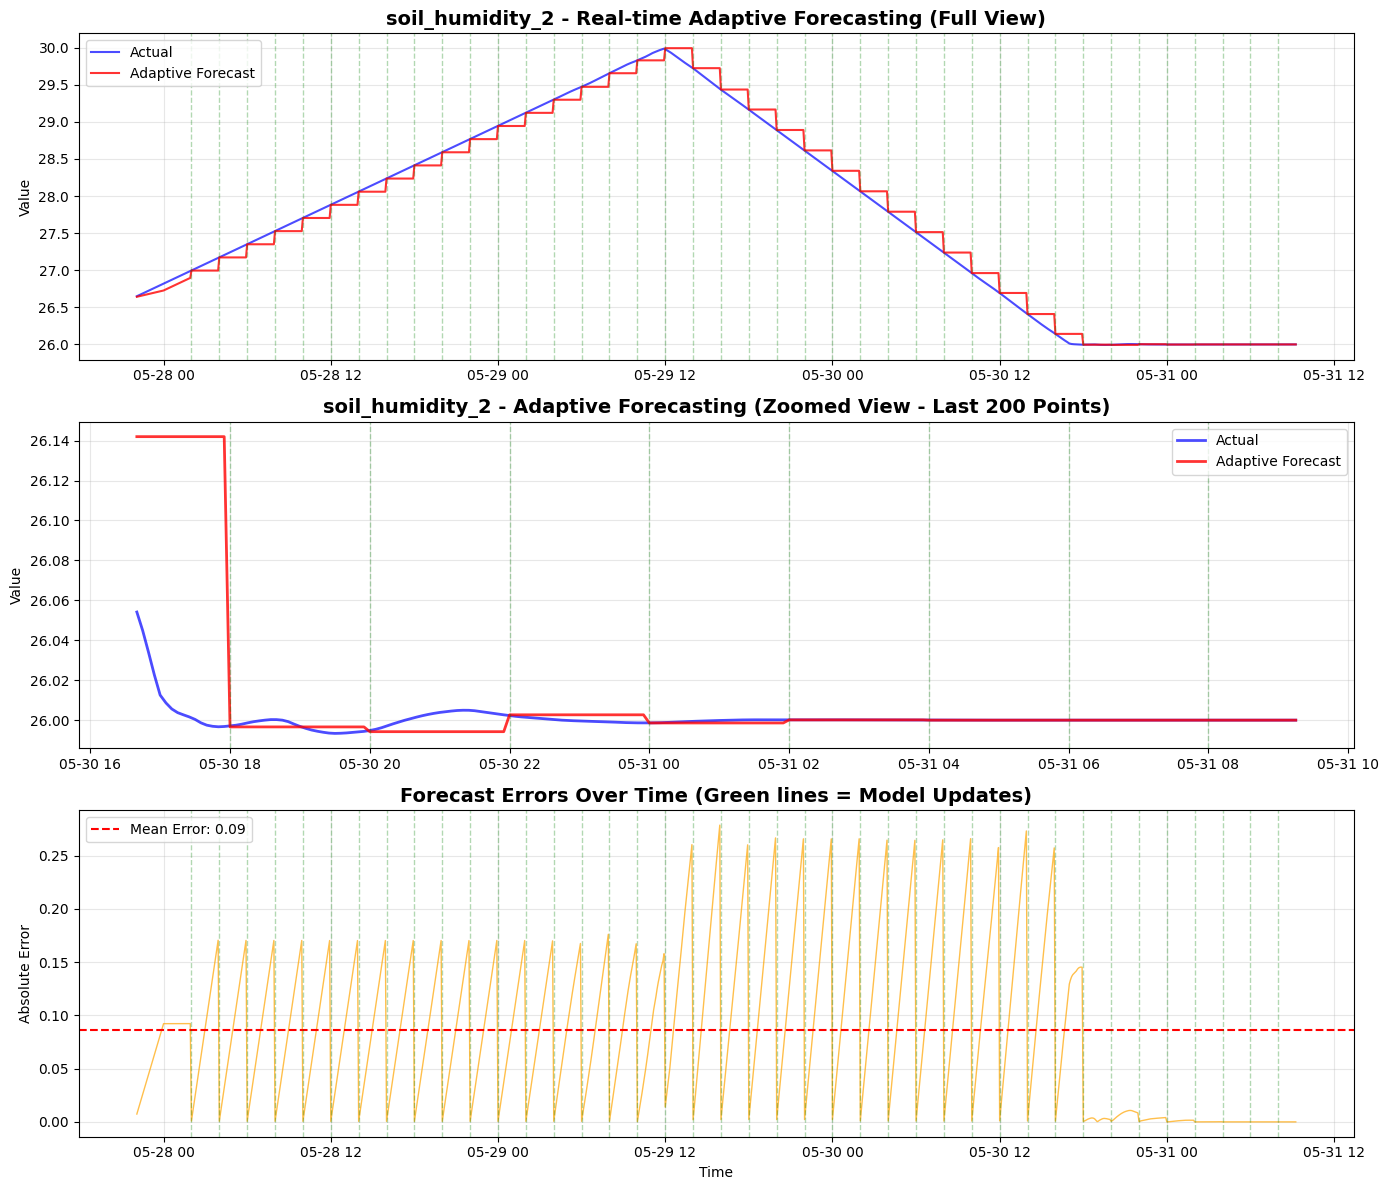

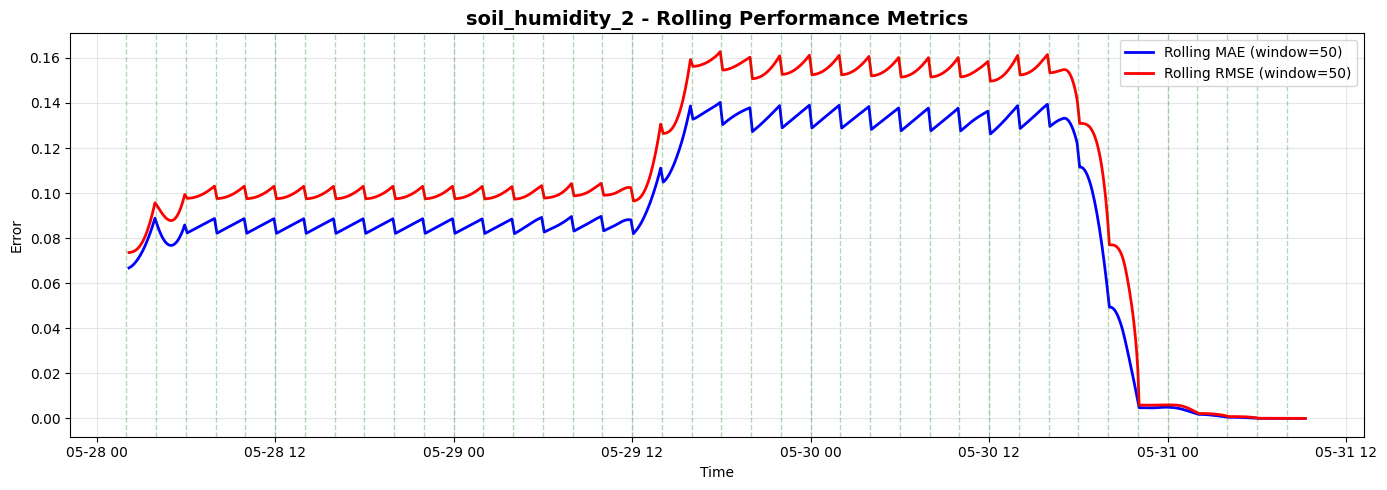

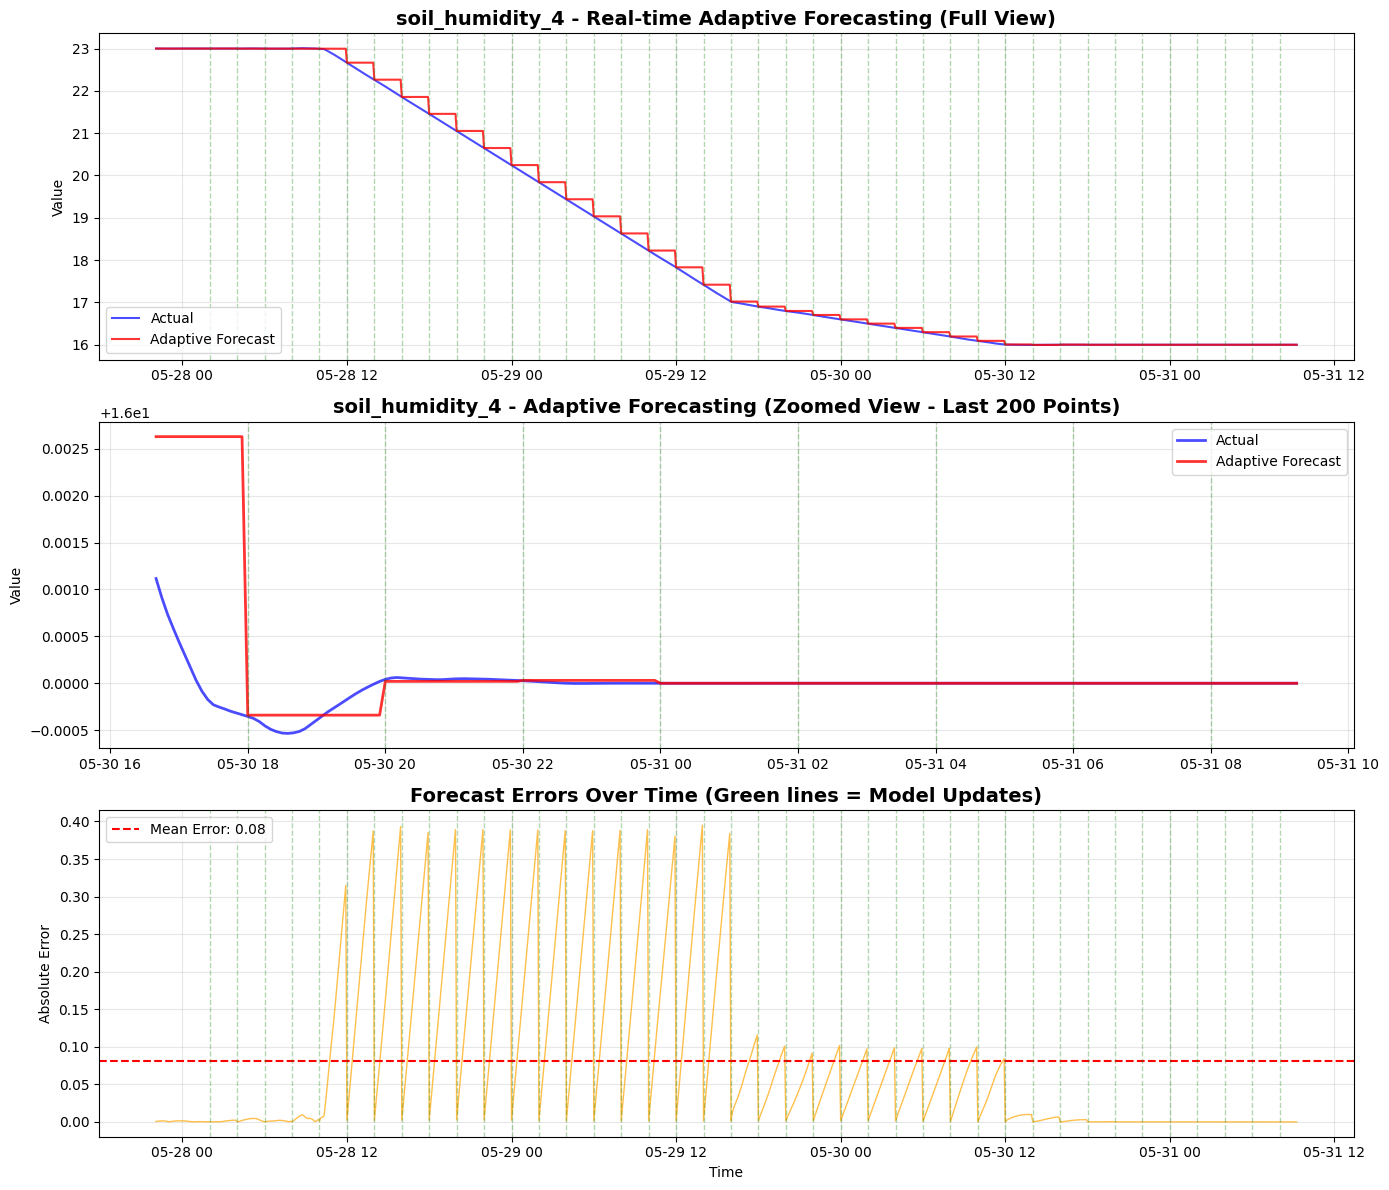

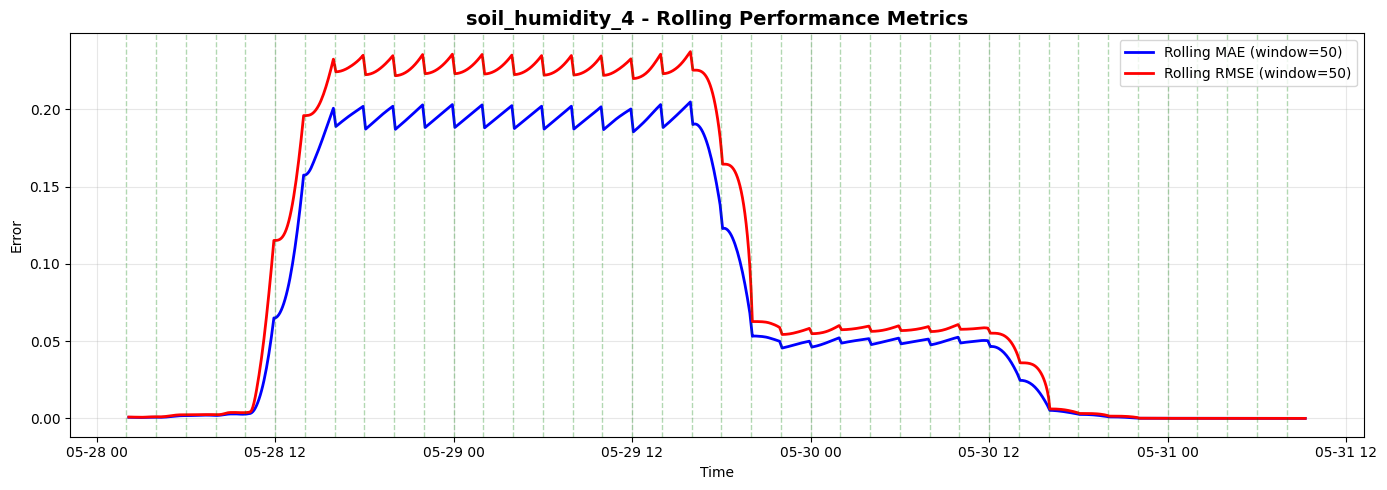

In [45]:
# Example usage
forecaster = AdaptiveForecaster(denoised_df, window_size=168, update_frequency=24)

# Simulate real-time forecasting with 1-step ahead predictions
results = forecaster.simulate_realtime(
    cols=['soil_humidity_2', 'soil_humidity_4'],
    #start_index=100,  # Start after accumulating some initial data
    start_index=len(denoised_df) - 1000,  # begin at last 1000 points
    forecast_horizon=1  # 1-step ahead forecast
)

## 3.9 Performance Comparison and Insights

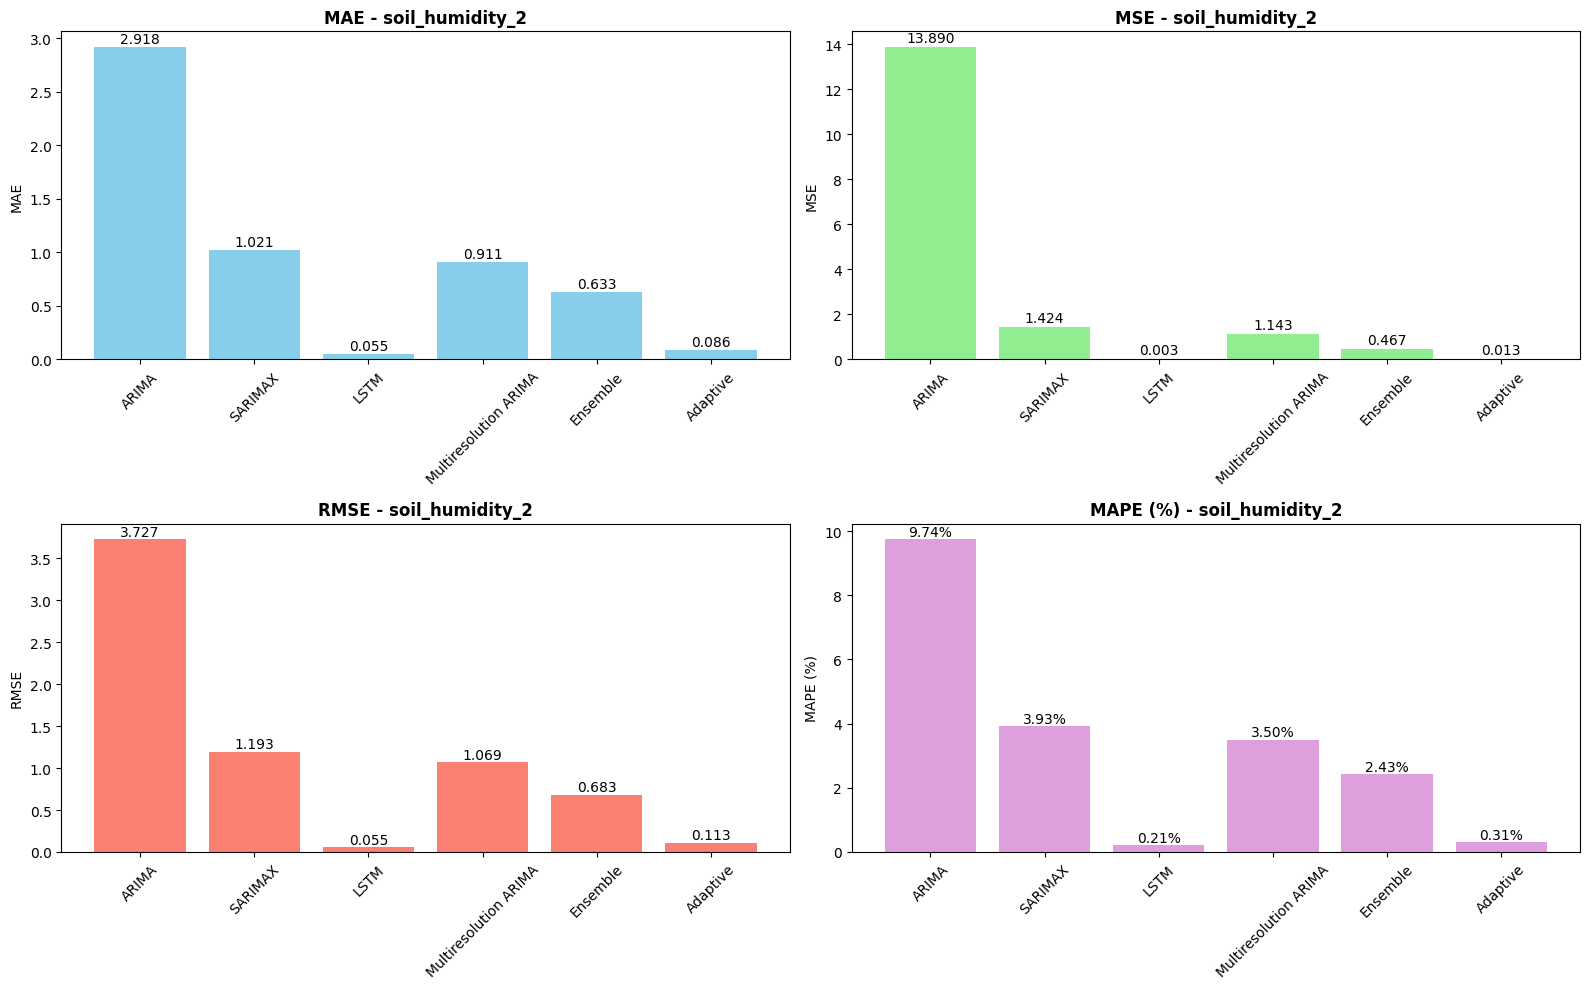


Performance Summary for soil_humidity_2:
                  Method     MAE      MSE    RMSE  MAPE (%)
0                  ARIMA  2.9175  13.8900  3.7269    9.7374
1                SARIMAX  1.0209   1.4243  1.1934    3.9300
2                   LSTM  0.0548   0.0030  0.0549    0.2100
3  Multiresolution ARIMA  0.9112   1.1428  1.0690    3.5000
4               Ensemble  0.6331   0.4670  0.6834    2.4300
5               Adaptive  0.0859   0.0127  0.1129    0.3100


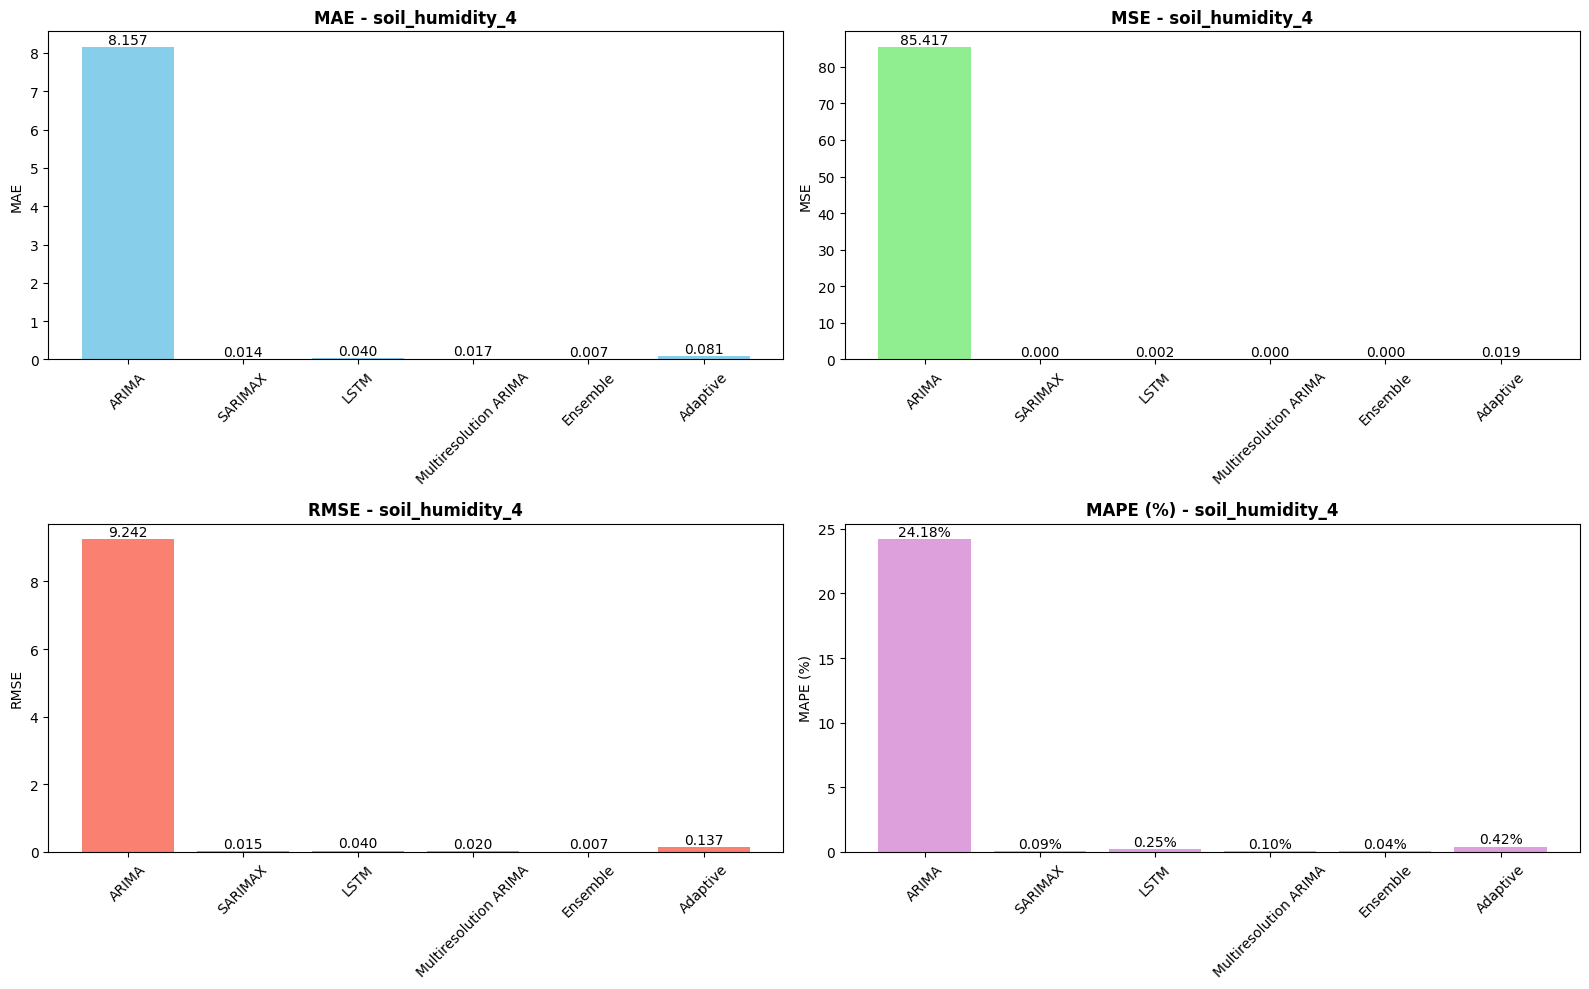


Performance Summary for soil_humidity_4:
                  Method     MAE      MSE    RMSE  MAPE (%)
0                  ARIMA  8.1566  85.4166  9.2421   24.1791
1                SARIMAX  0.0139   0.0002  0.0152    0.0900
2                   LSTM  0.0403   0.0016  0.0403    0.2500
3  Multiresolution ARIMA  0.0168   0.0004  0.0197    0.1000
4               Ensemble  0.0071   0.0001  0.0073    0.0400
5               Adaptive  0.0814   0.0189  0.1374    0.4200


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_forecasting_performance_2x2(sensor_name, metrics_dict):
    """
    Plots MAE, MSE, RMSE, and MAPE for a given sensor using multiple forecasting methods.
    
    Parameters:
    -----------
    sensor_name : str
        Name of the sensor, e.g., 'soil_humidity_2'.
    metrics_dict : dict
        Dictionary containing performance metrics for each method, e.g.,
        {
            'ARIMA': {'MAE': 2.91, 'MSE': 13.89, 'MAPE': 9.73},
            'SARIMAX': {...}, ...
        }
    """
    methods = list(metrics_dict.keys())
    mae_scores = [metrics_dict[m]['MAE'] for m in methods]
    mse_scores = [metrics_dict[m]['MSE'] for m in methods]
    rmse_scores = [np.sqrt(mse) for mse in mse_scores]
    mape_scores = [metrics_dict[m]['MAPE'] for m in methods]

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # MAE
    ax = axes[0, 0]
    ax.bar(methods, mae_scores, color='skyblue')
    ax.set_title(f'MAE - {sensor_name}', fontsize=12, fontweight='bold')
    ax.set_ylabel('MAE')
    ax.tick_params(axis='x', rotation=45)
    for i, v in enumerate(mae_scores):
        ax.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom')

    # MSE
    ax = axes[0, 1]
    ax.bar(methods, mse_scores, color='lightgreen')
    ax.set_title(f'MSE - {sensor_name}', fontsize=12, fontweight='bold')
    ax.set_ylabel('MSE')
    ax.tick_params(axis='x', rotation=45)
    for i, v in enumerate(mse_scores):
        ax.text(i, v + 0.1, f'{v:.3f}', ha='center', va='bottom')

    # RMSE
    ax = axes[1, 0]
    ax.bar(methods, rmse_scores, color='salmon')
    ax.set_title(f'RMSE - {sensor_name}', fontsize=12, fontweight='bold')
    ax.set_ylabel('RMSE')
    ax.tick_params(axis='x', rotation=45)
    for i, v in enumerate(rmse_scores):
        ax.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom')

    # MAPE
    ax = axes[1, 1]
    ax.bar(methods, mape_scores, color='plum')
    ax.set_title(f'MAPE (%) - {sensor_name}', fontsize=12, fontweight='bold')
    ax.set_ylabel('MAPE (%)')
    ax.tick_params(axis='x', rotation=45)
    for i, v in enumerate(mape_scores):
        ax.text(i, v + 0.01, f'{v:.2f}%', ha='center', va='bottom')

    plt.tight_layout()
    plt.savefig(f"./output/forecasting_performance_{sensor_name}.png")
    plt.show()

    # Summary table
    performance_df = pd.DataFrame({
        'Method': methods,
        'MAE': mae_scores,
        'MSE': mse_scores,
        'RMSE': rmse_scores,
        'MAPE (%)': mape_scores
    })
    print(f"\nPerformance Summary for {sensor_name}:")
    print(performance_df.round(4))


# Example metrics for soil_humidity_2
metrics_soil_humidity_2 = {
    'ARIMA': {'MAE': 2.917523, 'MSE': 13.890037, 'MAPE': 9.737374},
    'SARIMAX': {'MAE': 1.02086, 'MSE': 1.424289, 'MAPE': 3.93},
    'LSTM': {'MAE': 0.054835, 'MSE': 0.003019, 'MAPE': 0.21},
    'Multiresolution ARIMA': {'MAE': 0.911214, 'MSE': 1.142784, 'MAPE': 3.50},
    'Ensemble': {'MAE': 0.633056, 'MSE': 0.467002, 'MAPE': 2.43},
    'Adaptive': {'MAE': 0.085933, 'MSE': 0.012748, 'MAPE': 0.31}
}

# Example metrics for soil_humidity_4
metrics_soil_humidity_4 = {
    'ARIMA': {'MAE': 8.156625, 'MSE': 85.4166, 'MAPE': 24.179127},
    'SARIMAX': {'MAE': 0.013938, 'MSE': 0.000231, 'MAPE': 0.09},
    'LSTM': {'MAE': 0.040333, 'MSE': 0.001627, 'MAPE': 0.25},
    'Multiresolution ARIMA': {'MAE': 0.016781, 'MSE': 0.000390, 'MAPE': 0.10},
    'Ensemble': {'MAE': 0.007131, 'MSE': 0.000053, 'MAPE': 0.04},
    'Adaptive': {'MAE': 0.081419, 'MSE': 0.018873, 'MAPE': 0.42}
}

# Plot
plot_forecasting_performance_2x2('soil_humidity_2', metrics_soil_humidity_2)
plot_forecasting_performance_2x2('soil_humidity_4', metrics_soil_humidity_4)

